#**Download Both External Datasets**

In [3]:

# ============================================================
# M1.5 — DOWNLOAD BOTH EXTERNAL DATASETS
# EXACT SOURCES FROM Thesis_External_Validation.ipynb
# ============================================================

import sys
import subprocess
from pathlib import Path
import zipfile

subprocess.check_call([
    sys.executable, "-m", "pip", "-q",
    "install", "gdown", "kagglehub"
])

import gdown
import kagglehub

# ============================================================
# 1. MESSIDOR-2 — ORIGINAL RETFOUND BENCHMARK ARCHIVE
# ============================================================

MESSIDOR_ZIP = Path("/content/MESSIDOR2.zip")
MESSIDOR_DIR = Path("/content/MESSIDOR2")
MESSIDOR_ROOT = MESSIDOR_DIR / "MESSIDOR2"

MESSIDOR_FILE_ID = "1vOLBUK9xdzNV8eVkRjVdNrRwhPfaOmda"

if not MESSIDOR_ZIP.exists():
    gdown.download(
        id=MESSIDOR_FILE_ID,
        output=str(MESSIDOR_ZIP),
        quiet=False
    )

if not zipfile.is_zipfile(MESSIDOR_ZIP):
    raise RuntimeError("Messidor-2 download is not a valid ZIP.")

MESSIDOR_DIR.mkdir(parents=True, exist_ok=True)

if not MESSIDOR_ROOT.exists():
    with zipfile.ZipFile(MESSIDOR_ZIP) as z:
        z.extractall(MESSIDOR_DIR)

messidor_images = [
    p for p in MESSIDOR_ROOT.rglob("*")
    if p.suffix.lower() in {
        ".jpg", ".jpeg", ".png", ".tif", ".tiff"
    }
]

assert len(messidor_images) == 1744, (
    f"Messidor-2 expected 1744 imported images, "
    f"found {len(messidor_images)}"
)

print("Messidor-2: 1744 images verified.")

# ============================================================
# 2. IDRID — ORIGINAL KAGGLE DATASET SOURCE
# ============================================================

IDRID_ROOT = Path(
    kagglehub.dataset_download(
        "dankok/diabetic-retinopathy-image-dataset"
    )
)

IDRID_GRADING = IDRID_ROOT / "Disease_Grading"

IDRID_TRAIN_DIR = (
    IDRID_GRADING / "Original_Images" / "Training Set"
)
IDRID_TEST_DIR = (
    IDRID_GRADING / "Original_Images" / "Testing Set"
)

def image_count(folder):
    return sum(
        p.suffix.lower() in {".jpg", ".jpeg", ".png"}
        for p in folder.rglob("*")
        if p.is_file()
    )

train_n = image_count(IDRID_TRAIN_DIR)
test_n = image_count(IDRID_TEST_DIR)

assert train_n == 413, f"Expected 413 training, got {train_n}"
assert test_n == 103, f"Expected 103 testing, got {test_n}"

print("IDRiD: 516 images verified.")

# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n========== DATASETS READY ==========")
print("Messidor-2:", MESSIDOR_ROOT)
print("IDRiD:", IDRID_GRADING)
print("Total original external images:", 1744 + 516)
print("====================================")


Downloading...
From (original): https://drive.google.com/uc?id=1vOLBUK9xdzNV8eVkRjVdNrRwhPfaOmda
From (redirected): https://drive.google.com/uc?id=1vOLBUK9xdzNV8eVkRjVdNrRwhPfaOmda&confirm=t&uuid=49eb2c4e-ce20-4cfc-9aa9-6920aaaee33a
To: /content/MESSIDOR2.zip
100%|██████████| 2.51G/2.51G [01:00<00:00, 41.8MB/s]


Messidor-2: 1744 images verified.
Using Colab cache for faster access to the 'diabetic-retinopathy-image-dataset' dataset.
IDRiD: 516 images verified.

========== DATASETS READY ==========
Messidor-2: /content/MESSIDOR2/MESSIDOR2
IDRiD: /kaggle/input/diabetic-retinopathy-image-dataset/Disease_Grading
Total original external images: 2260


#**Connect Drive and inspect our existing research files**

In [2]:

from google.colab import drive
from pathlib import Path
import os

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/thesis_DR")

if not ROOT.is_dir():
    raise FileNotFoundError(
        f"Research directory not found: {ROOT}\n"
        "Check the Google Drive folder location."
    )

print("Research folder:", ROOT)
print("\nTop-level contents:")
for p in sorted(ROOT.iterdir()):
    print("DIR " if p.is_dir() else "FILE", p.name)

extensions = {".csv", ".json", ".pt", ".pth",
              ".pkl", ".npy", ".npz", ".parquet"}

artifacts = []
for current, dirs, files in os.walk(ROOT):
    for filename in files:
        path = Path(current) / filename
        if path.suffix.lower() in extensions:
            artifacts.append(path.relative_to(ROOT))

print(f"\nFound {len(artifacts)} potential research artifacts:\n")
for p in sorted(artifacts)[:150]:
    print(p)

if len(artifacts) > 150:
    print(f"\n... {len(artifacts) - 150} additional artifacts")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Research folder: /content/drive/MyDrive/thesis_DR

Top-level contents:
FILE aptos_dinov2_large_embeddings.npz
FILE aptos_dinov2_large_ltt_risk_control.csv
FILE aptos_dinov2_large_mlp_heads.pt
FILE aptos_dinov2_large_raw_predictions.csv
FILE aptos_dinov2_large_temperature_scaling.json
FILE aptos_exact_duplicate_audit.csv
FILE aptos_idrid_crossfit_weights.npz
FILE aptos_idrid_importance_weights.csv
FILE aptos_medsiglip_embeddings.npz
FILE aptos_medsiglip_ltt_risk_control.csv
FILE aptos_medsiglip_mlp_heads.pt
FILE aptos_medsiglip_raw_predictions.csv
FILE aptos_medsiglip_temperature_scaling.json
FILE aptos_retfound_green_embeddings.npz
FILE aptos_retfound_internal_test_results.csv
FILE aptos_retfound_ltt_risk_control.csv
FILE aptos_retfound_mlp_heads.pt
FILE aptos_retfound_raw_predictions.csv
FILE aptos_retfound_selective_baseline.csv
FILE aptos_retfound_temperat

#**Inspect only the four necessary files**

In [ ]:

import pandas as pd

files = {
    "SPLITS": "aptos_split_manifest.csv",
    "PREDICTIONS": "aptos_retfound_raw_predictions.csv",
    "LTT": "aptos_retfound_ltt_risk_control.csv",
    "EXISTING BASELINES": "aptos_retfound_selective_baseline.csv"
}

for label, filename in files.items():
    path = ROOT / filename

    print(f"\n{'='*60}")
    print(f"{label}: {filename}")

    if not path.exists():
        print("MISSING")
        continue

    df = pd.read_csv(path)

    print("Shape:", df.shape)
    print("Columns:", list(df.columns))
    print("\nFirst 2 records:")
    print(df.head(2).to_string(index=False))

    for col in df.columns:
        if col.lower() in {
            "seed", "split", "partition", "subset",
            "method", "baseline", "risk_target", "alpha"
        }:
            values = df[col].dropna().unique()
            print(f"\n{col}:", values[:20])



SPLITS: aptos_split_manifest.csv
Shape: (17520, 5)
Columns: ['seed', 'image_id', 'original_grade', 'binary_label', 'split']

First 2 records:
 seed     image_id  original_grade  binary_label       split
   42 66a0bf258013               4             1 development
   42 de730033c683               0             0 development

seed: [42 43 44 45 46]

split: ['development' 'prob_calibration' 'risk_calibration' 'internal_test']

PREDICTIONS: aptos_retfound_raw_predictions.csv
Shape: (17520, 7)
Columns: ['seed', 'image_id', 'split', 'original_grade', 'binary_label', 'raw_logit', 'raw_probability']

First 2 records:
 seed     image_id       split  original_grade  binary_label  raw_logit  raw_probability
   42 66a0bf258013 development               4             1   5.327720         0.995168
   42 de730033c683 development               0             0  -4.287941         0.013547

seed: [42 43 44 45 46]

split: ['development' 'prob_calibration' 'risk_calibration' 'internal_test']

LTT: aptos_r

#**Comparison of Automatic Non-Referral Threshold Selection Methods**

Purpose: To determine whether our proposed Learn-Then-Test (LTT) method provides better risk-controlled screening than simpler threshold-selection methods.

We compare three methods using the same RETFound-Green model:
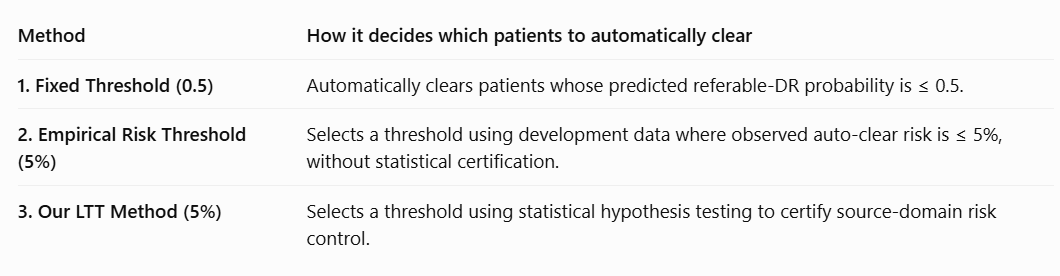

In [ ]:

import numpy as np
import pandas as pd
from scipy.special import expit
from pathlib import Path

ALPHA = 0.05
OUT = ROOT / "major_revision_M1"
OUT.mkdir(exist_ok=True)

pred = pd.read_csv(ROOT / "aptos_retfound_raw_predictions.csv")
ltt = pd.read_csv(ROOT / "aptos_retfound_ltt_risk_control.csv")
sweep = pd.read_csv(ROOT / "aptos_retfound_selective_baseline.csv")

# Recover the existing fitted source temperatures.
assert (sweep.groupby("seed")["temperature"].nunique() == 1).all()
temperatures = sweep.groupby("seed")["temperature"].first()

assert (temperatures > 0).all()
pred["temperature"] = pred["seed"].map(temperatures)
assert pred["temperature"].notna().all()

pred["score"] = expit(pred["raw_logit"] / pred["temperature"])

ltt5 = ltt[np.isclose(ltt["alpha"], ALPHA)].set_index("seed")
assert ltt5.index.is_unique

def evaluate(df, threshold):
    selected = df["score"].to_numpy() <= threshold
    labels = df["binary_label"].to_numpy()
    n = len(df)
    cleared = int(selected.sum())
    errors = int(labels[selected].sum())

    return {
        "n": n,
        "cleared": cleared,
        "errors": errors,
        "coverage": cleared / n,
        "risk": errors / cleared if cleared else np.nan,
        "referable_miss": (
            errors / labels.sum() if labels.sum() else np.nan
        )
    }

records = []

for seed in sorted(pred["seed"].unique()):
    d = pred[pred["seed"] == seed]
    dev = d[d["split"] == "development"]
    risk_cal = d[d["split"] == "risk_calibration"]
    test = d[d["split"] == "internal_test"]

    assert len(risk_cal) == 526
    assert len(test) == 526

    # Fixed cutoff: chosen without fitting to labels.
    fixed_t = 0.5

    # Development-selected empirical-risk baseline.
    candidates = np.unique(np.quantile(
        dev["score"], np.linspace(0.02, 0.98, 50)
    ))

    eligible = []
    for t in candidates:
        result = evaluate(dev, float(t))
        if result["cleared"] > 0 and result["risk"] <= ALPHA:
            eligible.append((result["coverage"], float(t)))

    empirical_t = (
        sorted(eligible, key=lambda x: (-x[0], x[1]))[0][1]
        if eligible else None
    )

    # Original source-certified LTT threshold.
    original = ltt5.loc[seed]
    ltt_t = (
        float(original["selected_threshold"])
        if bool(original["certified"]) else None
    )

    # Verify the saved LTT calibration counts.
    if ltt_t is not None:
        check = evaluate(risk_cal, ltt_t)
        assert check["cleared"] == int(original["auto_clear_count"]), (
            f"Seed {seed}: LTT calibration clearance mismatch"
        )
        assert check["errors"] == int(original["errors"]), (
            f"Seed {seed}: LTT calibration error mismatch"
        )

    methods = {
        "Fixed-0.5": fixed_t,
        "Empirical-5%": empirical_t,
        "Original-LTT-5%": ltt_t
    }

    for method, threshold in methods.items():
        if threshold is None:
            result = {
                "n": len(test),
                "cleared": 0,
                "errors": 0,
                "coverage": 0.0,
                "risk": np.nan,
                "referable_miss": 0.0
            }
        else:
            result = evaluate(test, threshold)

        records.append({
            "seed": int(seed),
            "method": method,
            "threshold": threshold,
            **result
        })

results = pd.DataFrame(records)

summary = results.groupby("method").agg(
    coverage_mean=("coverage", "mean"),
    coverage_sd=("coverage", "std"),
    risk_mean=("risk", "mean"),
    risk_sd=("risk", "std"),
    miss_mean=("referable_miss", "mean")
).reset_index()

results.to_csv(
    OUT / "M1_aptos_baselines_seedwise.csv", index=False
)
summary.to_csv(
    OUT / "M1_aptos_baselines_summary.csv", index=False
)

print("\nSEED-WISE RESULTS")
print(results.to_string(index=False, float_format=lambda x: f"{x:.5f}"))

print("\nMEAN RESULTS (%)")
display_cols = summary.copy()
for col in display_cols.columns:
    if col != "method":
        display_cols[col] = (display_cols[col] * 100).round(2)
print(display_cols.to_string(index=False))

print("\nSaved results to:", OUT)



SEED-WISE RESULTS
 seed          method  threshold   n  cleared  errors  coverage    risk  referable_miss
   42       Fixed-0.5    0.50000 526      298       8   0.56654 0.02685         0.03902
   42    Empirical-5%    0.71390 526      324      22   0.61597 0.06790         0.10732
   42 Original-LTT-5%    0.15928 526      270       1   0.51331 0.00370         0.00488
   43       Fixed-0.5    0.50000 526      325      21   0.61787 0.06462         0.10244
   43    Empirical-5%    0.46077 526      321      19   0.61027 0.05919         0.09268
   43 Original-LTT-5%    0.02797 526      272       2   0.51711 0.00735         0.00976
   44       Fixed-0.5    0.50000 526      309      16   0.58745 0.05178         0.07805
   44    Empirical-5%    0.55410 526      317      20   0.60266 0.06309         0.09756
   44 Original-LTT-5%    0.04626 526      255       0   0.48479 0.00000         0.00000
   45       Fixed-0.5    0.50000 526      324      22   0.61597 0.06790         0.10680
   45    Empi

**Independent Risk-Calibration Threshold Comparison**

In [ ]:

import numpy as np
import pandas as pd
from scipy.special import expit
from scipy.stats import binom

ALPHA = 0.05
DELTA = 0.05

pred = pd.read_csv(ROOT / "aptos_retfound_raw_predictions.csv")
sweep = pd.read_csv(ROOT / "aptos_retfound_selective_baseline.csv")

temp = sweep.groupby("seed")["temperature"].first()
assert (sweep.groupby("seed")["temperature"].nunique() == 1).all()
assert (temp > 0).all()

pred["score"] = expit(
    pred["raw_logit"] /
    pred["seed"].map(temp)
)

def evaluate(df, threshold):
    if threshold is None:
        return dict(n=len(df), cleared=0, errors=0,
                    coverage=0.0, risk=np.nan, miss=0.0)

    selected = df["score"].to_numpy() <= threshold
    y = df["binary_label"].to_numpy()
    m = int(selected.sum())
    e = int(y[selected].sum())

    return dict(
        n=len(df),
        cleared=m,
        errors=e,
        coverage=m / len(df),
        risk=e / m if m else np.nan,
        miss=e / y.sum() if y.sum() else np.nan
    )

records = []
audit = []

for seed in sorted(pred.seed.unique()):
    data = pred[pred.seed == seed]
    dev = data[data.split == "development"]
    cal = data[data.split == "risk_calibration"]
    test = data[data.split == "internal_test"]

    # Same development-derived candidate grid as original LTT.
    candidates = np.unique(np.quantile(
        dev.score,
        np.linspace(0.02, 0.98, 50)
    ))

    # Match original LTT candidate ordering:
    # minimum development surrogate loss, then higher coverage.
    y_dev = dev.binary_label.to_numpy()
    s_dev = dev.score.to_numpy()

    ordered = []
    for t in candidates:
        a = s_dev <= t
        loss = np.mean(a * y_dev + ALPHA * (~a))
        ordered.append((float(t), loss, a.mean()))

    ordered.sort(key=lambda x: (x[1], -x[2], x[0]))

    # Baseline A: empirical-risk selection on shared calibration set.
    eligible = []
    for t, _, _ in ordered:
        r = evaluate(cal, t)
        if r["cleared"] and r["risk"] <= ALPHA:
            eligible.append((r["coverage"], t))

    empirical_t = (
        sorted(eligible, key=lambda x: (-x[0], x[1]))[0][1]
        if eligible else None
    )

    # Baseline B: exact binomial fixed-sequence testing.
    passed = []

    for position, (t, dev_loss, dev_cov) in enumerate(ordered, 1):
        r = evaluate(cal, t)
        m, e = r["cleared"], r["errors"]

        # H0: conditional auto-clear risk >= 5%.
        p_value = float(binom.cdf(e, m, ALPHA)) if m else 1.0
        certified = m > 0 and p_value <= DELTA

        audit.append({
            "seed": seed,
            "position": position,
            "threshold": t,
            "dev_surrogate_loss": dev_loss,
            "dev_coverage": dev_cov,
            "cal_cleared": m,
            "cal_errors": e,
            "cal_risk": r["risk"],
            "p_value": p_value,
            "passed": certified
        })

        if not certified:
            break

        passed.append((r["coverage"], t))

    binomial_t = (
        sorted(passed, key=lambda x: (-x[0], x[1]))[0][1]
        if passed else None
    )

    for method, threshold in {
        "Empirical-Cal-5%": empirical_t,
        "Binomial-FS-5%": binomial_t
    }.items():
        result = evaluate(test, threshold)

        records.append({
            "seed": seed,
            "method": method,
            "threshold": threshold,
            "certified": method == "Binomial-FS-5%"
                         and threshold is not None,
            **result
        })

new_results = pd.DataFrame(records)
audit_df = pd.DataFrame(audit)

OUT.mkdir(parents=True, exist_ok=True)

new_results.to_csv(
    OUT / "M1_additional_baselines_seedwise.csv",
    index=False
)
audit_df.to_csv(
    OUT / "M1_binomial_candidate_audit.csv",
    index=False
)

summary = new_results.groupby("method").agg(
    coverage=("coverage", "mean"),
    risk=("risk", "mean"),
    miss=("miss", "mean"),
    certified_seeds=("certified", "sum")
)

print("SEED-WISE RESULTS")
print(new_results.to_string(index=False))

print("\nSUMMARY (%)")
for column in ["coverage", "risk", "miss"]:
    summary[column] = (summary[column] * 100).round(2)

print(summary.to_string())

print("\nCandidate tests per seed:")
print(audit_df.groupby("seed").agg(
    tests=("position", "count"),
    passed=("passed", "sum")
).to_string())



SEED-WISE RESULTS
 seed           method  threshold  certified   n  cleared  errors  coverage     risk     miss
   42 Empirical-Cal-5%   0.611878      False 526      310      15  0.589354 0.048387 0.073171
   42   Binomial-FS-5%   0.295889       True 526      283       3  0.538023 0.010601 0.014634
   43 Empirical-Cal-5%   0.132827      False 526      288       4  0.547529 0.013889 0.019512
   43   Binomial-FS-5%   0.061035       True 526      282       2  0.536122 0.007092 0.009756
   44 Empirical-Cal-5%   0.464331      False 526      307      14  0.583650 0.045603 0.068293
   44   Binomial-FS-5%   0.240189       True 526      281       3  0.534221 0.010676 0.014634
   45 Empirical-Cal-5%   0.424615      False 526      319      18  0.606464 0.056426 0.087379
   45   Binomial-FS-5%   0.202222       True 526      299       7  0.568441 0.023411 0.033981
   46 Empirical-Cal-5%   0.615248      False 526      324      22  0.615970 0.067901 0.106796
   46   Binomial-FS-5%   0.442151       Tr

Original LTT has the lowest observed risk: 0.37%, compared with 1.70% for exact binomial testing.



Binomial testing achieves higher coverage: 55.06% versus LTT's 51.06%, while remaining below 5% observed risk in every internal test.


Both statistical methods certified thresholds in all five seeds.


The empirical calibration method exceeded 5% observed risk in two seeds (45 and 46), despite meeting its empirical calibration criterion.

#**Verify Fairness of the LTT and Binomial Screening Comparison**

In [ ]:

import numpy as np
import pandas as pd

ALPHA = 0.05

pred = pd.read_csv(
    ROOT / "aptos_retfound_raw_predictions.csv"
)
ltt = pd.read_csv(
    ROOT / "aptos_retfound_ltt_risk_control.csv"
)
binomial_audit = pd.read_csv(
    OUT / "M1_binomial_candidate_audit.csv"
)
sweep = pd.read_csv(
    ROOT / "aptos_retfound_selective_baseline.csv"
)

temperature = sweep.groupby("seed")["temperature"].first()

from scipy.special import expit

pred["score"] = expit(
    pred["raw_logit"] /
    pred["seed"].map(temperature)
)

records = []

for seed in sorted(pred["seed"].unique()):
    dev = pred[
        (pred["seed"] == seed) &
        (pred["split"] == "development")
    ]

    scores = dev["score"].to_numpy()
    labels = dev["binary_label"].to_numpy()

    candidates = np.unique(
        np.quantile(scores, np.linspace(0.02, 0.98, 50))
    )

    ordered = []
    for t in candidates:
        selected = scores <= t
        loss = np.mean(
            selected * labels + ALPHA * (~selected)
        )
        ordered.append((float(t), loss, selected.mean()))

    ordered.sort(key=lambda x: (x[1], -x[2], x[0]))
    thresholds = np.array([x[0] for x in ordered])

    original = ltt[
        (ltt["seed"] == seed) &
        (np.isclose(ltt["alpha"], ALPHA))
    ].iloc[0]

    selected_t = float(original["selected_threshold"])
    original_fail = float(original["first_failed_threshold"])
    passed_n = int(original["certified_candidates_before_stop"])

    selected_match = np.any(
        np.isclose(thresholds, selected_t, atol=1e-6)
    )

    reconstructed_fail = (
        thresholds[passed_n]
        if passed_n < len(thresholds) else np.nan
    )

    failure_match = np.isclose(
        reconstructed_fail, original_fail,
        atol=1e-6, equal_nan=True
    )

    audit = binomial_audit[
        binomial_audit["seed"] == seed
    ].sort_values("position")

    checked = thresholds[:len(audit)]
    binomial_match = np.allclose(
        checked,
        audit["threshold"].to_numpy(),
        atol=1e-6
    )

    records.append({
        "seed": seed,
        "candidates": len(thresholds),
        "LTT_selected_in_grid": selected_match,
        "LTT_first_failure_matches": failure_match,
        "Binomial_order_matches": binomial_match,
        "LTT_passed_candidates": passed_n,
        "Binomial_passed_candidates": int(audit["passed"].sum())
    })

verification = pd.DataFrame(records)

print("M1 THRESHOLD FAIRNESS VERIFICATION")
print(verification.to_string(index=False))

checks = verification[
    [
        "LTT_selected_in_grid",
        "LTT_first_failure_matches",
        "Binomial_order_matches"
    ]
]

print("\nOVERALL VERIFICATION:",
      "PASS" if checks.to_numpy().all() else "INVESTIGATE")

verification.to_csv(
    OUT / "M1_threshold_fairness_verification.csv",
    index=False
)


M1 THRESHOLD FAIRNESS VERIFICATION
 seed  candidates  LTT_selected_in_grid  LTT_first_failure_matches  Binomial_order_matches  LTT_passed_candidates  Binomial_passed_candidates
   42          50                  True                       True                    True                      2                           7
   43          50                  True                       True                    True                      1                           3
   44          50                  True                       True                    True                      1                           8
   45          50                  True                       True                    True                      4                          15
   46          50                  True                       True                    True                      1                          16

OVERALL VERIFICATION: PASS


#**External Evaluation of Automatic Non-Referral Threshold Selection Methods**
We will test the five methods already implemented on IDRiD and Messidor-2, using their original APTOS-selected thresholds without external recalibration.

In [ ]:

import numpy as np
import pandas as pd
from scipy.special import expit

OUT = ROOT / "major_revision_M1"

# Load thresholds selected only from APTOS.
a = pd.read_csv(OUT / "M1_aptos_baselines_seedwise.csv")
b = pd.read_csv(OUT / "M1_additional_baselines_seedwise.csv")

policies = pd.concat([
    a[["seed", "method", "threshold"]],
    b[["seed", "method", "threshold"]]
], ignore_index=True)

assert len(policies) == 25
assert not policies.duplicated(["seed", "method"]).any()

# Existing source-fitted temperatures.
sweep = pd.read_csv(
    ROOT / "aptos_retfound_selective_baseline.csv"
)
assert (sweep.groupby("seed")["temperature"].nunique() == 1).all()
temperatures = sweep.groupby("seed")["temperature"].first()

datasets = {
    "IDRiD": ("idrid_retfound_raw_predictions.csv", 507),
    "Messidor-2": ("messidor2_retfound_raw_predictions.csv", 1740)
}

records = []

for dataset, (filename, expected_n) in datasets.items():

    df = pd.read_csv(ROOT / filename)

    required = {
        "seed", "image_id", "binary_label", "raw_logit"
    }
    missing = required - set(df.columns)
    if missing:
        raise ValueError(
            f"{filename}: missing {missing}. "
            f"Available columns: {list(df.columns)}"
        )

    assert not df.duplicated(["seed", "image_id"]).any()
    assert set(df["seed"]) == set(temperatures.index)
    assert df["binary_label"].isin([0, 1]).all()

    # Verify identical external cohorts across source seeds.
    reference = None
    for seed in sorted(df.seed.unique()):
        d = df[df.seed == seed]
        assert len(d) == expected_n, (dataset, seed, len(d))

        labels = d.set_index("image_id")["binary_label"].sort_index()
        if reference is None:
            reference = labels
        else:
            pd.testing.assert_series_equal(reference, labels)

    # Apply each seed's ORIGINAL APTOS temperature.
    df["temperature"] = df["seed"].map(temperatures)
    assert df["temperature"].notna().all()
    assert (df["temperature"] > 0).all()

    df["score"] = expit(
        df["raw_logit"] / df["temperature"]
    )

    for p in policies.itertuples(index=False):
        d = df[df["seed"] == p.seed]

        threshold = p.threshold
        selected = (
            d["score"].to_numpy() <= threshold
            if pd.notna(threshold)
            else np.zeros(len(d), dtype=bool)
        )

        y = d["binary_label"].to_numpy()
        n = len(y)
        m = int(selected.sum())
        e = int(y[selected].sum())
        positives = int(y.sum())

        records.append({
            "dataset": dataset,
            "seed": int(p.seed),
            "method": p.method,
            "source_threshold": threshold,
            "total": n,
            "referable_total": positives,
            "cleared": m,
            "missed_referable": e,
            "coverage": m / n,
            "risk": e / m if m else np.nan,
            "referable_miss": (
                e / positives if positives else np.nan
            )
        })

results = pd.DataFrame(records)

summary = results.groupby(
    ["dataset", "method"], as_index=False
).agg(
    coverage=("coverage", "mean"),
    risk=("risk", "mean"),
    referable_miss=("referable_miss", "mean")
)

# Reproduce our original manuscript's RETFound external results.
expected = {
    "IDRiD": (33.61, 14.73),
    "Messidor-2": (78.74, 14.66)
}

checks = []
for dataset, (expected_cov, expected_risk) in expected.items():
    row = summary[
        (summary.dataset == dataset) &
        (summary.method == "Original-LTT-5%")
    ].iloc[0]

    cov = row.coverage * 100
    risk = row.risk * 100

    passed = (
        abs(cov - expected_cov) < 0.05 and
        abs(risk - expected_risk) < 0.05
    )

    checks.append(passed)
    print(
        f"{dataset} original LTT reproduction: "
        f"{'PASS' if passed else 'MISMATCH'} "
        f"(coverage={cov:.2f}%, risk={risk:.2f}%)"
    )

results.to_csv(
    OUT / "M1_external_baselines_seedwise.csv",
    index=False
)
summary.to_csv(
    OUT / "M1_external_baselines_summary.csv",
    index=False
)

print("\nEXTERNAL SCREENING RESULTS (%)")

shown = summary.copy()
for col in ["coverage", "risk", "referable_miss"]:
    shown[col] = (shown[col] * 100).round(2)

print(shown.to_string(index=False))

print("\nOVERALL REPRODUCTION:",
      "PASS" if all(checks) else "INVESTIGATE")


IDRiD original LTT reproduction: PASS (coverage=33.61%, risk=14.73%)
Messidor-2 original LTT reproduction: PASS (coverage=78.74%, risk=14.66%)

EXTERNAL SCREENING RESULTS (%)
   dataset           method  coverage  risk  referable_miss
     IDRiD   Binomial-FS-5%     42.96 22.12           15.27
     IDRiD     Empirical-5%     50.89 29.57           24.16
     IDRiD Empirical-Cal-5%     48.40 27.06           21.01
     IDRiD        Fixed-0.5     50.30 28.96           23.60
     IDRiD  Original-LTT-5%     33.61 14.73            8.01
Messidor-2   Binomial-FS-5%     86.62 17.76           58.99
Messidor-2     Empirical-5%     92.06 20.44           71.96
Messidor-2 Empirical-Cal-5%     90.36 19.52           67.56
Messidor-2        Fixed-0.5     91.23 19.90           69.45
Messidor-2  Original-LTT-5%     78.74 14.66           44.26

OVERALL REPRODUCTION: PASS


LTT has the lowest observed risk, but it also clears fewer images. We cannot attribute the difference entirely to a better statistical method.



Binomial testing clears more images, but its observed external risk is higher.



Neither LTT nor binomial testing preserves the source-domain 5% risk target externally.



This supports our paper's central finding: source-domain risk certification does not guarantee external risk control under distribution shift.

#**External Validation of DINOv2-Large and MedSigLIP**
Goal: Determine whether DINOv2-Large and MedSigLIP also experience increased automatic non-referral risk on IDRiD and Messidor-2, like RETFound-Green.

**Verify Saved Models and External Data Availability**

In [ ]:

import numpy as np
import pandas as pd
import torch
import json
from pathlib import Path

models = {
    "DINOv2-Large": "dinov2_large",
    "MedSigLIP": "medsiglip"
}

for name, prefix in models.items():
    print(f"\n{'='*55}")
    print(name)

    # Check saved embedding structure.
    npz_path = ROOT / f"aptos_{prefix}_embeddings.npz"
    with np.load(npz_path, allow_pickle=True) as data:
        print("\nAPTOS embedding arrays:")
        for key in data.files:
            arr = data[key]
            print(key, arr.shape, arr.dtype)

    # Check trained classification heads.
    checkpoint = torch.load(
        ROOT / f"aptos_{prefix}_mlp_heads.pt",
        map_location="cpu",
        weights_only=True
    )
    print("\nCheckpoint structure:")
    print("Type:", type(checkpoint).__name__)
    if isinstance(checkpoint, dict):
        print("Keys:", list(checkpoint.keys())[:20])

    # Check saved temperature structure.
    with open(ROOT / f"aptos_{prefix}_temperature_scaling.json") as f:
        temp = json.load(f)

    print("\nTemperature structure:")
    if isinstance(temp, dict):
        print("Keys:", list(temp.keys())[:20])
    else:
        print("Type:", type(temp).__name__)

    # Check existing source certification.
    ltt = pd.read_csv(
        ROOT / f"aptos_{prefix}_ltt_risk_control.csv"
    )
    selected = ltt[np.isclose(ltt["alpha"], 0.05)]

    print("\n5% LTT certification:")
    print(selected[
        ["seed", "certified", "selected_threshold"]
    ].to_string(index=False))

print("\n" + "="*55)
print("AVAILABLE DRIVE DATA DIRECTORIES")
for p in sorted(Path("/content/drive/MyDrive").iterdir()):
    if p.is_dir():
        print(p.name)

print("\nLOCAL COLAB DATA DIRECTORIES")
for p in sorted(Path("/content").iterdir()):
    if p.is_dir() and p.name != "drive":
        print(p.name)



DINOv2-Large

APTOS embedding arrays:
embeddings (3504, 1024) float32
image_id (3504,) <U12
original_grade (3504,) int64
binary_label (3504,) int64

Checkpoint structure:
Type: dict
Keys: ['backbone', 'encoder_status', 'embedding_dim', 'head_architecture', 'training_protocol', 'hpo_configs', 'seeds', 'heads']

Temperature structure:
Keys: ['model', 'method', 'objective', 'fit_split', 'ece_bins', 'seeds']

5% LTT certification:
 seed  certified  selected_threshold
   42      False                 NaN
   43       True            0.097320
   44       True            0.126720
   45       True            0.251959
   46      False                 NaN

MedSigLIP

APTOS embedding arrays:
embeddings (3504, 1152) float32
image_id (3504,) <U12
original_grade (3504,) int64
binary_label (3504,) int64

Checkpoint structure:
Type: dict
Keys: ['backbone', 'encoder_status', 'embedding_dim', 'head_architecture', 'training_protocol', 'hpo_configs', 'seeds', 'heads']

Temperature structure:
Keys: ['model

In [ ]:

from huggingface_hub import login, hf_hub_download
from getpass import getpass

# Securely enter your Hugging Face token.
# It will not appear in the notebook output.
HF_TOKEN = getpass("Enter Hugging Face READ token: ")

login(token=HF_TOKEN, add_to_git_credential=False)

# Verify access BEFORE attempting model extraction.
hf_hub_download(
    repo_id="google/medsiglip-448",
    filename="config.json",
    token=HF_TOKEN
)

print("SUCCESS: MedSigLIP access authorized.")


Enter Hugging Face READ token: ··········


config.json:   0%|          | 0.00/879 [00:00<?, ?B/s]

SUCCESS: MedSigLIP access authorized.


#**Extract External DINOv2-Large and MedSigLIP Embeddings**

In [ ]:

# ============================================================
# M1.5 — EXTERNAL FOUNDATION MODEL EMBEDDING EXTRACTION
# Models: DINOv2-Large and MedSigLIP
# Datasets: IDRiD and Messidor-2
# Based on original source-model preprocessing notebooks
# ============================================================

import gc
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from transformers import AutoImageProcessor, AutoProcessor, AutoModel

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_DR")
SAVE_DIR = PROJECT_DIR / "major_revision_M1"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

if not torch.cuda.is_available():
    raise RuntimeError("Enable GPU: Runtime > Change runtime type > T4 GPU")

device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))

# ============================================================
# 1. LOAD EXACT ORIGINAL EXTERNAL COHORTS
# Reuse the saved RETFound cohort identifiers and labels.
# No new duplicate removal or label generation.
# ============================================================

cohorts = {}

with np.load(
    PROJECT_DIR / "idrid_retfound_green_embeddings.npz",
    allow_pickle=True
) as ref:

    idrid = pd.DataFrame({
        "image_id": ref["image_id"].astype(str),
        "original_image_id": ref["original_image_id"].astype(str),
        "source_split": ref["source_split"].astype(str),
        "original_grade": ref["original_grade"].astype(int),
        "binary_label": ref["binary_label"].astype(int)
    })

idrid["path"] = [
    str(
        IDRID_GRADING
        / "Original_Images"
        / ("Training Set" if split == "train" else "Testing Set")
        / f"{image_id}.jpg"
    )
    for split, image_id in zip(
        idrid["source_split"],
        idrid["original_image_id"]
    )
]

assert len(idrid) == 507
cohorts["idrid"] = idrid

with np.load(
    PROJECT_DIR / "messidor2_retfound_green_embeddings.npz",
    allow_pickle=True
) as ref:

    messidor = pd.DataFrame({
        "image_id": ref["image_id"].astype(str),
        "original_grade": ref["original_grade"].astype(int),
        "binary_label": ref["binary_label"].astype(int)
    })

messidor["path"] = [
    str(MESSIDOR_ROOT / image_id)
    for image_id in messidor["image_id"]
]

assert len(messidor) == 1740
cohorts["messidor2"] = messidor

for name, df in cohorts.items():
    assert df["image_id"].is_unique
    assert (df["binary_label"] == (df["original_grade"] >= 2)).all()

    missing = [p for p in df["path"] if not Path(p).is_file()]
    if missing:
        raise FileNotFoundError(
            f"{name}: {len(missing)} images missing. First: {missing[0]}"
        )

    print(f"{name}: {len(df)} original evaluation images ready")

# ============================================================
# 2. EXACT SOURCE-MODEL CUSTOM PREPROCESSING
# From original DINOv2 and MedSigLIP notebooks.
# ============================================================

def remove_black_border(image, threshold=7):
    arr = np.asarray(image)

    gray = (
        0.299 * arr[:, :, 0]
        + 0.587 * arr[:, :, 1]
        + 0.114 * arr[:, :, 2]
    )

    mask = gray > threshold

    if not mask.any():
        return image

    rows = np.where(mask.any(axis=1))[0]
    cols = np.where(mask.any(axis=0))[0]

    cropped = arr[
        rows[0]:rows[-1] + 1,
        cols[0]:cols[-1] + 1
    ]

    return Image.fromarray(cropped)


def pad_to_square(image):
    width, height = image.size
    side = max(width, height)

    square = Image.new("RGB", (side, side), (0, 0, 0))

    square.paste(
        image,
        ((side - width) // 2, (side - height) // 2)
    )

    return square


class ExternalRetinaDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        with Image.open(row["path"]) as img:
            image = img.convert("RGB")
            image = remove_black_border(image, threshold=7)
            image = pad_to_square(image)

        return image


# ============================================================
# 3. EXTRACT BOTH ENCODERS
# ============================================================

models = [
    {
        "name": "medsiglip",
        "model_id": "google/medsiglip-448",
        "dim": 1152
    }
]

BATCH_SIZE = 8

for spec in models:

    name = spec["name"]
    print(f"\n{'='*55}")
    print("MODEL:", name)

    # Original DINOv2 used AutoImageProcessor.
    # Original MedSigLIP used AutoProcessor.
    if name == "dinov2_large":
        processor = AutoImageProcessor.from_pretrained(
            spec["model_id"]
        )

        model = AutoModel.from_pretrained(
            spec["model_id"],
            torch_dtype=torch.float16,
            low_cpu_mem_usage=True
        )
    else:
        processor = AutoProcessor.from_pretrained(
            spec["model_id"]
        )

        model = AutoModel.from_pretrained(
            spec["model_id"]
        )

    model = model.to(device)
    model.eval()

    for parameter in model.parameters():
        parameter.requires_grad = False

    for dataset_name, df in cohorts.items():

        output = (
            SAVE_DIR /
            f"{dataset_name}_{name}_embeddings.npz"
        )

        # Avoid repeating a completed extraction.
        if output.exists():
            with np.load(output, allow_pickle=True) as old:
                valid = (
                    old["embeddings"].shape == (len(df), spec["dim"])
                    and np.array_equal(
                        old["image_id"].astype(str),
                        df["image_id"].to_numpy()
                    )
                    and np.array_equal(
                        old["original_grade"],
                        df["original_grade"].to_numpy()
                    )
                    and np.array_equal(
                        old["binary_label"],
                        df["binary_label"].to_numpy()
                    )
                    and np.isfinite(old["embeddings"]).all()
                )
            if valid:
                print("Already saved, skipping:", output.name)
                continue

        loader = DataLoader(
            ExternalRetinaDataset(df),
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=0,
            collate_fn=lambda batch: batch
        )

        all_features = []

        with torch.inference_mode():
            for images in tqdm(
                loader,
                desc=f"{name} - {dataset_name}"
            ):

                inputs = processor(
                    images=images,
                    return_tensors="pt"
                )

                pixel_values = inputs["pixel_values"].to(
                    device=device,
                    dtype=next(model.parameters()).dtype
                )

                if name == "dinov2_large":
                    outputs = model(
                        pixel_values=pixel_values
                    )

                    # Same CLS-token extraction as source notebook.
                    features = outputs.last_hidden_state[:, 0, :]

                else:
                    # Same get_image_features extraction as source.
                    features = model.get_image_features(
                        pixel_values=pixel_values
                    )

                    if hasattr(features, "pooler_output"):
                        features = features.pooler_output

                all_features.append(
                    features.float().cpu().numpy()
                )

                del inputs, pixel_values, features

        embeddings = np.concatenate(
            all_features, axis=0
        ).astype(np.float32)

        assert embeddings.shape == (
            len(df), spec["dim"]
        ), (name, dataset_name, embeddings.shape)

        assert np.isfinite(embeddings).all()

        np.savez_compressed(
            output,
            embeddings=embeddings,
            image_id=df["image_id"].to_numpy(dtype=str),
            original_grade=df["original_grade"].to_numpy(dtype=np.int64),
            binary_label=df["binary_label"].to_numpy(dtype=np.int64)
        )

        print(
            f"SAVED: {output.name} "
            f"| shape={embeddings.shape}"
        )

        del embeddings, all_features, loader
        gc.collect()
        torch.cuda.empty_cache()

    del model, processor
    gc.collect()
    torch.cuda.empty_cache()

print("\n===== M1.5 EMBEDDING EXTRACTION COMPLETE =====")
print("All results stored in:", SAVE_DIR)


GPU: Tesla T4
idrid: 507 original evaluation images ready
messidor2: 1740 original evaluation images ready

MODEL: medsiglip


preprocessor_config.json:   0%|          | 0.00/360 [00:00<?, ?B/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


tokenizer_config.json:   0%|          | 0.00/809 [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  798kB            

spiece.model: downloading bytes:           |  0.00B            

... (5 outputs left out)

medsiglip - idrid:   0%|          | 0/64 [00:00<?, ?it/s]

SAVED: idrid_medsiglip_embeddings.npz | shape=(507, 1152)


medsiglip - messidor2:   0%|          | 0/218 [00:00<?, ?it/s]

SAVED: messidor2_medsiglip_embeddings.npz | shape=(1740, 1152)

===== M1.5 EMBEDDING EXTRACTION COMPLETE =====
All results stored in: /content/drive/MyDrive/thesis_DR/major_revision_M1


#**External Screening Evaluation Using Saved Models**

In [ ]:

# ============================================================
# M1.5 — EXTERNAL FOUNDATION MODEL SCREENING EVALUATION
# Models: DINOv2-Large and MedSigLIP
# Datasets: IDRiD and Messidor-2
# Uses original saved MLP heads, temperatures and LTT policies
# No retraining or external threshold recalibration
# ============================================================

import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from scipy.special import expit
from sklearn.metrics import roc_auc_score, average_precision_score

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_DR")
SAVE_DIR = PROJECT_DIR / "major_revision_M1"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

SEEDS = [42, 43, 44, 45, 46]
ALPHA = 0.05

DEVICE = torch.device("cpu")

# ============================================================
# 1. ORIGINAL MLP ARCHITECTURE
# Exactly as defined in the original training notebooks
# ============================================================

class MLPHead(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim=512,
        dropout=0.10
    ):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(1)


def predict_logits(model, embeddings):
    model.eval()

    with torch.inference_mode():
        logits = model(
            torch.from_numpy(
                embeddings.astype(np.float32)
            ).to(DEVICE)
        )

    return logits.cpu().numpy()


# ============================================================
# 2. MODEL CONFIGURATIONS
# ============================================================

MODELS = {
    "DINOv2-Large": {
        "prefix": "dinov2_large",
        "dim": 1024
    },
    "MedSigLIP": {
        "prefix": "medsiglip",
        "dim": 1152
    }
}

DATASETS = {
    "IDRiD": ("idrid", 507),
    "Messidor-2": ("messidor2", 1740)
}

all_predictions = []
all_results = []
verification = []

# ============================================================
# 3. LOAD ORIGINAL SAVED MODELS AND PARAMETERS
# ============================================================

for model_name, config in MODELS.items():

    prefix = config["prefix"]
    dim = config["dim"]

    print(f"\n{'='*60}")
    print("MODEL:", model_name)

    checkpoint = torch.load(
        PROJECT_DIR / f"aptos_{prefix}_mlp_heads.pt",
        map_location=DEVICE,
        weights_only=True
    )

    assert checkpoint["embedding_dim"] == dim

    with open(
        PROJECT_DIR / f"aptos_{prefix}_temperature_scaling.json"
    ) as f:
        temp_data = json.load(f)

    ltt = pd.read_csv(
        PROJECT_DIR / f"aptos_{prefix}_ltt_risk_control.csv"
    )

    ltt = ltt[
        np.isclose(ltt["alpha"], ALPHA)
    ].copy()

    assert len(ltt) == 5
    assert set(ltt["seed"]) == set(SEEDS)

    ltt = ltt.set_index("seed")

    # ========================================================
    # 4. LOAD ORIGINAL APTOS EMBEDDINGS AND PREDICTIONS
    # Used only to verify the saved classification heads
    # ========================================================

    with np.load(
        PROJECT_DIR / f"aptos_{prefix}_embeddings.npz",
        allow_pickle=False
    ) as data:

        aptos_embeddings = data["embeddings"].astype(np.float32)
        aptos_ids = data["image_id"].astype(str)

    aptos_predictions = pd.read_csv(
        PROJECT_DIR / f"aptos_{prefix}_raw_predictions.csv",
        dtype={"image_id": str}
    )

    assert aptos_embeddings.shape == (3504, dim)
    assert len(np.unique(aptos_ids)) == 3504

    # ========================================================
    # 5. LOAD NEW EXTERNAL EMBEDDINGS
    # ========================================================

    external_data = {}

    for dataset_name, (dataset_prefix, expected_n) in DATASETS.items():

        path = (
            SAVE_DIR /
            f"{dataset_prefix}_{prefix}_embeddings.npz"
        )

        with np.load(path, allow_pickle=False) as data:

            X = data["embeddings"].astype(np.float32)
            ids = data["image_id"].astype(str)
            grades = data["original_grade"].astype(int)
            labels = data["binary_label"].astype(int)

        assert X.shape == (expected_n, dim)
        assert len(np.unique(ids)) == expected_n
        assert np.isfinite(X).all()
        assert np.array_equal(labels, (grades >= 2).astype(int))

        external_data[dataset_name] = {
            "embeddings": X,
            "image_id": ids,
            "original_grade": grades,
            "binary_label": labels
        }

    # ========================================================
    # 6. RUN ORIGINAL FIVE SOURCE-TRAINED HEADS
    # ========================================================

    for seed in SEEDS:

        head = MLPHead(input_dim=dim).to(DEVICE)

        head.load_state_dict(
            checkpoint["heads"][seed]["state_dict"],
            strict=True
        )

        head.eval()

        temperature = float(
            temp_data["seeds"][str(seed)]["temperature"]
        )

        assert temperature > 0

        policy = ltt.loc[seed]
        certified = bool(policy["certified"])

        threshold = (
            float(policy["selected_threshold"])
            if certified else np.nan
        )

        if certified:
            assert np.isfinite(threshold)

        # ====================================================
        # 7. VERIFY ORIGINAL APTOS HEAD PREDICTIONS
        # ====================================================

        source_logits = predict_logits(
            head,
            aptos_embeddings
        )

        saved_source = aptos_predictions[
            aptos_predictions["seed"] == seed
        ].copy()

        assert len(saved_source) == 3504
        assert saved_source["image_id"].is_unique

        reproduced_source = pd.Series(
            source_logits,
            index=aptos_ids
        ).reindex(saved_source["image_id"])

        assert reproduced_source.notna().all()

        max_difference = float(
            np.max(
                np.abs(
                    reproduced_source.to_numpy()
                    - saved_source["raw_logit"].to_numpy()
                )
            )
        )

        verification.append({
            "model": model_name,
            "seed": seed,
            "max_logit_difference": max_difference,
            "passed": max_difference < 1e-3
        })

        if max_difference >= 1e-3:
            raise RuntimeError(
                f"APTOS prediction reproduction FAILED: "
                f"{model_name}, seed {seed}, "
                f"maximum difference={max_difference}"
            )

        # ====================================================
        # 8. EXTERNAL INFERENCE
        # ====================================================

        for dataset_name, data in external_data.items():

            raw_logits = predict_logits(
                head,
                data["embeddings"]
            )

            raw_probabilities = expit(raw_logits)

            probabilities = expit(
                raw_logits / temperature
            )

            labels = data["binary_label"]
            n = len(labels)

            # Failed certification => no automatic clearance.
            if certified:
                auto_clear = probabilities <= threshold
            else:
                auto_clear = np.zeros(n, dtype=bool)

            cleared = int(auto_clear.sum())
            errors = int(labels[auto_clear].sum())
            referable_total = int(labels.sum())

            coverage = cleared / n

            risk = (
                errors / cleared
                if cleared > 0 else np.nan
            )

            referable_miss = (
                errors / referable_total
                if referable_total > 0 else np.nan
            )

            auroc = roc_auc_score(
                labels,
                probabilities
            )

            auprc = average_precision_score(
                labels,
                probabilities
            )

            # Save image-level predictions.
            pred_df = pd.DataFrame({
                "model": model_name,
                "dataset": dataset_name,
                "seed": seed,
                "image_id": data["image_id"],
                "original_grade": data["original_grade"],
                "binary_label": labels,
                "raw_logit": raw_logits,
                "raw_probability": raw_probabilities,
                "calibrated_probability": probabilities,
                "temperature": temperature,
                "certified": certified,
                "source_threshold": threshold,
                "auto_clear": auto_clear.astype(int)
            })

            all_predictions.append(pred_df)

            all_results.append({
                "model": model_name,
                "dataset": dataset_name,
                "seed": seed,
                "certified": certified,
                "source_threshold": threshold,
                "total_images": n,
                "referable_total": referable_total,
                "auto_cleared": cleared,
                "missed_referable": errors,
                "coverage": coverage,
                "auto_clear_risk": risk,
                "referable_miss": referable_miss,
                "auroc": auroc,
                "auprc": auprc
            })

    print(model_name, "— five-seed evaluation completed.")

# ============================================================
# 9. SAVE COMPLETE RESULTS
# ============================================================

verification_df = pd.DataFrame(verification)

assert verification_df["passed"].all()

predictions_df = pd.concat(
    all_predictions,
    ignore_index=True
)

results_df = pd.DataFrame(all_results)

assert len(results_df) == 20
assert len(predictions_df) == 5 * 2 * (507 + 1740)

summary_df = results_df.groupby(
    ["model", "dataset"], as_index=False
).agg(
    certified_seeds=("certified", "sum"),
    mean_auroc=("auroc", "mean"),
    mean_auprc=("auprc", "mean"),
    mean_coverage=("coverage", "mean"),
    mean_risk_certified=("auto_clear_risk", "mean"),
    mean_referable_miss=("referable_miss", "mean")
)

verification_df.to_csv(
    SAVE_DIR / "M1_external_head_reproduction_check.csv",
    index=False
)

predictions_df.to_csv(
    SAVE_DIR / "M1_external_encoder_predictions.csv",
    index=False
)

results_df.to_csv(
    SAVE_DIR / "M1_external_encoder_seedwise.csv",
    index=False
)

summary_df.to_csv(
    SAVE_DIR / "M1_external_encoder_summary.csv",
    index=False
)

# ============================================================
# 10. FINAL OUTPUT
# ============================================================

print("\n===== ORIGINAL APTOS PREDICTION VERIFICATION =====")
print(
    verification_df.groupby("model").agg(
        max_difference=("max_logit_difference", "max"),
        all_passed=("passed", "all")
    ).to_string()
)

print("\n===== EXTERNAL SCREENING SUMMARY =====")

display_df = summary_df.copy()

for col in [
    "mean_coverage",
    "mean_risk_certified",
    "mean_referable_miss"
]:
    display_df[col] = (
        display_df[col] * 100
    ).round(2)

for col in ["mean_auroc", "mean_auprc"]:
    display_df[col] = display_df[col].round(4)

print(display_df.to_string(index=False))

print("\nALL RESULTS SAVED TO:", SAVE_DIR)
print("M1.5 COMPLETE — External predictions generated.")



MODEL: DINOv2-Large
DINOv2-Large — five-seed evaluation completed.

MODEL: MedSigLIP
MedSigLIP — five-seed evaluation completed.

===== ORIGINAL APTOS PREDICTION VERIFICATION =====
              max_difference  all_passed
model                                   
DINOv2-Large        0.000003        True
MedSigLIP           0.000004        True

===== EXTERNAL SCREENING SUMMARY =====
       model    dataset  certified_seeds  mean_auroc  mean_auprc  mean_coverage  mean_risk_certified  mean_referable_miss
DINOv2-Large      IDRiD                3      0.9556      0.9766          23.20                16.31                 6.06
DINOv2-Large Messidor-2                3      0.8080      0.6587          49.11                16.88                31.74
   MedSigLIP      IDRiD                4      0.9705      0.9831          33.02                15.04                 7.95
   MedSigLIP Messidor-2                4      0.9159      0.8467          62.46                10.15                24.31

ALL

#**Compare RETFound, DINOv2 and MedSigLIP at matched automatic-clearance coverage.**

PASS: All three models use identical image IDs and labels.


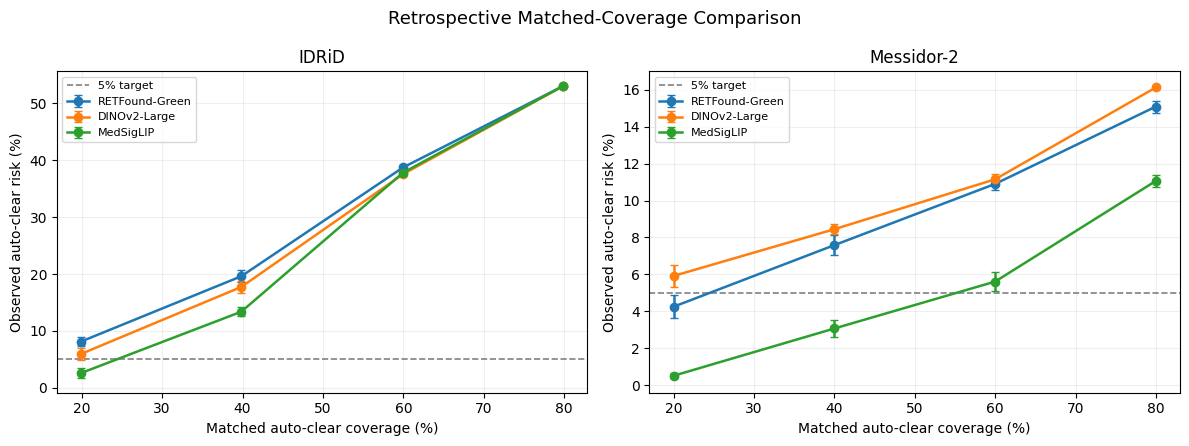


===== MATCHED-COVERAGE RISK (%) =====
   dataset  target_coverage          model  coverage_mean  risk_mean  risk_sd  miss_mean  tie_splits
     IDRiD              0.2   DINOv2-Large          19.92       5.94     0.99       1.89           0
     IDRiD              0.2      MedSigLIP          19.92       2.57     0.89       0.82           0
     IDRiD              0.2 RETFound-Green          19.92       8.12     0.83       2.59           0
     IDRiD              0.4   DINOv2-Large          39.84      17.72     1.07      11.29           0
     IDRiD              0.4      MedSigLIP          39.84      13.37     0.78       8.52           0
     IDRiD              0.4 RETFound-Green          39.84      19.60     1.08      12.49           0
     IDRiD              0.6   DINOv2-Large          59.96      37.57     0.15      36.03           0
     IDRiD              0.6      MedSigLIP          59.96      37.83     0.23      36.28           0
     IDRiD              0.6 RETFound-Green          

In [ ]:

# ============================================================
# M1.6 — MATCHED-COVERAGE FOUNDATION MODEL COMPARISON
# RETFound-Green vs DINOv2-Large vs MedSigLIP
# IDRiD and Messidor-2 | Five source seeds
# Retrospective analysis — NOT deployable risk certification
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.special import expit

ROOT = Path("/content/drive/MyDrive/thesis_DR")
OUT = ROOT / "major_revision_M1"
OUT.mkdir(parents=True, exist_ok=True)

SEEDS = [42, 43, 44, 45, 46]
COVERAGE_LEVELS = [0.20, 0.40, 0.60, 0.80]

# ============================================================
# 1. LOAD ORIGINAL RETFOUND EXTERNAL PREDICTIONS
# ============================================================

temperature_df = pd.read_csv(
    ROOT / "aptos_retfound_selective_baseline.csv"
)

temperatures = temperature_df.groupby(
    "seed"
)["temperature"].first()

retfound_parts = []

for dataset_name, filename in {
    "IDRiD": "idrid_retfound_raw_predictions.csv",
    "Messidor-2": "messidor2_retfound_raw_predictions.csv"
}.items():

    df = pd.read_csv(
        ROOT / filename,
        dtype={"image_id": str}
    )

    df["score"] = expit(
        df["raw_logit"].to_numpy() /
        df["seed"].map(temperatures).to_numpy()
    )

    df["dataset"] = dataset_name
    df["model"] = "RETFound-Green"

    retfound_parts.append(
        df[[
            "dataset", "model", "seed",
            "image_id", "binary_label", "score"
        ]]
    )

retfound = pd.concat(
    retfound_parts,
    ignore_index=True
)

# ============================================================
# 2. LOAD NEW DINOv2 AND MEDSIGLIP PREDICTIONS
# ============================================================

other = pd.read_csv(
    OUT / "M1_external_encoder_predictions.csv",
    dtype={"image_id": str}
)

other = other.rename(
    columns={"calibrated_probability": "score"}
)

other = other[[
    "dataset", "model", "seed",
    "image_id", "binary_label", "score"
]]

all_scores = pd.concat(
    [retfound, other],
    ignore_index=True
)

MODELS = [
    "RETFound-Green",
    "DINOv2-Large",
    "MedSigLIP"
]

DATASETS = {
    "IDRiD": 507,
    "Messidor-2": 1740
}

# ============================================================
# 3. VERIFY IDENTICAL EVALUATION IMAGES AND LABELS
# ============================================================

assert set(all_scores["model"]) == set(MODELS)
assert np.isfinite(all_scores["score"]).all()
assert all_scores["binary_label"].isin([0, 1]).all()

assert not all_scores.duplicated(
    ["dataset", "model", "seed", "image_id"]
).any()

reference = retfound[[
    "dataset", "seed", "image_id", "binary_label"
]]

for model_name in MODELS[1:]:

    comparison = all_scores[
        all_scores["model"] == model_name
    ][[
        "dataset", "seed", "image_id", "binary_label"
    ]]

    joined = reference.merge(
        comparison,
        on=["dataset", "seed", "image_id"],
        how="outer",
        suffixes=("_reference", "_model"),
        indicator=True,
        validate="one_to_one"
    )

    assert (joined["_merge"] == "both").all(), (
        f"Image mismatch for {model_name}"
    )

    assert (
        joined["binary_label_reference"] ==
        joined["binary_label_model"]
    ).all(), f"Label mismatch for {model_name}"

for (dataset, model, seed), group in all_scores.groupby(
    ["dataset", "model", "seed"]
):

    assert seed in SEEDS
    assert len(group) == DATASETS[dataset]

print("PASS: All three models use identical image IDs and labels.")

# ============================================================
# 4. MATCHED-COVERAGE EVALUATION
# ============================================================

records = []

for (dataset, model, seed), df in all_scores.groupby(
    ["dataset", "model", "seed"]
):

    scores = df["score"].to_numpy(dtype=np.float64)
    labels = df["binary_label"].to_numpy(dtype=np.int64)
    ids = df["image_id"].to_numpy(dtype=str)

    n = len(df)

    # Ascending referable probability = lowest predicted risk.
    # Image ID provides deterministic ordering for tied scores.
    order = np.lexsort((ids, scores))

    sorted_scores = scores[order]
    sorted_labels = labels[order]

    for target_coverage in COVERAGE_LEVELS:

        k = int(np.floor(target_coverage * n + 1e-12))

        cleared_labels = sorted_labels[:k]
        errors = int(cleared_labels.sum())

        # A split tie cannot be reproduced by a pure score
        # threshold; record it explicitly.
        boundary_tie_split = bool(
            k > 0 and k < n and
            sorted_scores[k - 1] == sorted_scores[k]
        )

        records.append({
            "dataset": dataset,
            "model": model,
            "seed": int(seed),
            "target_coverage": target_coverage,
            "total_images": n,
            "auto_cleared": k,
            "missed_referable": errors,
            "actual_coverage": k / n,
            "auto_clear_risk": errors / k if k else np.nan,
            "referable_miss": (
                errors / labels.sum()
                if labels.sum() else np.nan
            ),
            "boundary_tie_split": boundary_tie_split
        })

matched = pd.DataFrame(records)

# ============================================================
# 5. FIVE-SEED MEAN AND STANDARD DEVIATION
# ============================================================

summary = matched.groupby(
    ["dataset", "target_coverage", "model"],
    as_index=False
).agg(
    coverage_mean=("actual_coverage", "mean"),
    risk_mean=("auto_clear_risk", "mean"),
    risk_sd=("auto_clear_risk", "std"),
    miss_mean=("referable_miss", "mean"),
    tie_splits=("boundary_tie_split", "sum")
)

# ============================================================
# 6. PAIRED RISK DIFFERENCES AGAINST RETFOUND
# ============================================================

paired = matched.pivot(
    index=["dataset", "seed", "target_coverage"],
    columns="model",
    values="auto_clear_risk"
).reset_index()

paired["DINO_minus_RET_pp"] = 100 * (
    paired["DINOv2-Large"] -
    paired["RETFound-Green"]
)

paired["MedSigLIP_minus_RET_pp"] = 100 * (
    paired["MedSigLIP"] -
    paired["RETFound-Green"]
)

paired_summary = paired.groupby(
    ["dataset", "target_coverage"],
    as_index=False
).agg(
    DINO_difference_mean=("DINO_minus_RET_pp", "mean"),
    DINO_difference_sd=("DINO_minus_RET_pp", "std"),
    MedSigLIP_difference_mean=("MedSigLIP_minus_RET_pp", "mean"),
    MedSigLIP_difference_sd=("MedSigLIP_minus_RET_pp", "std")
)

# ============================================================
# 7. SAVE RESULTS
# ============================================================

matched.to_csv(
    OUT / "M1_matched_coverage_seedwise.csv",
    index=False
)

summary.to_csv(
    OUT / "M1_matched_coverage_summary.csv",
    index=False
)

paired.to_csv(
    OUT / "M1_matched_coverage_paired_differences.csv",
    index=False
)

paired_summary.to_csv(
    OUT / "M1_matched_coverage_paired_summary.csv",
    index=False
)

# ============================================================
# 8. MAIN COMPARISON FIGURE
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, dataset in zip(axes, DATASETS):

    sub = summary[summary["dataset"] == dataset]

    for model in MODELS:

        m = sub[
            sub["model"] == model
        ].sort_values("target_coverage")

        ax.errorbar(
            m["coverage_mean"] * 100,
            m["risk_mean"] * 100,
            yerr=m["risk_sd"] * 100,
            marker="o",
            capsize=3,
            linewidth=1.8,
            label=model
        )

    ax.axhline(
        5,
        linestyle="--",
        color="gray",
        linewidth=1.2,
        label="5% target"
    )

    ax.set_title(dataset)
    ax.set_xlabel("Matched auto-clear coverage (%)")
    ax.set_ylabel("Observed auto-clear risk (%)")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

fig.suptitle(
    "Retrospective Matched-Coverage Comparison",
    fontsize=13
)

fig.tight_layout()

fig.savefig(
    OUT / "M1_matched_coverage_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUT / "M1_matched_coverage_comparison.pdf",
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 9. PRINT RESULTS
# ============================================================

print("\n===== MATCHED-COVERAGE RISK (%) =====")

display_summary = summary.copy()

for col in [
    "coverage_mean", "risk_mean",
    "risk_sd", "miss_mean"
]:
    display_summary[col] = (
        display_summary[col] * 100
    ).round(2)

print(display_summary.to_string(index=False))

print("\n===== PAIRED RISK DIFFERENCE VS RETFOUND (PP) =====")
print(
    paired_summary.round(2).to_string(index=False)
)

print("\nTOTAL BOUNDARY TIE SPLITS:",
      int(matched["boundary_tie_split"].sum()))

print("\nSaved to:", OUT)
print("M1.6 MATCHED-COVERAGE ANALYSIS COMPLETE")


#**Paired Statistical Uncertainty and Final Result Verification**

In [ ]:

# ============================================================
# M1.7 — PAIRED UNCERTAINTY AND FINAL RESULTS VERIFICATION
# RETFound-Green vs DINOv2-Large vs MedSigLIP
# IDRiD and Messidor-2 | Five source seeds
# Paired image-level bootstrap at matched coverage
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from scipy.special import expit

ROOT = Path("/content/drive/MyDrive/thesis_DR")
OUT = ROOT / "major_revision_M1"

SEEDS = [42, 43, 44, 45, 46]

MODELS = [
    "RETFound-Green",
    "DINOv2-Large",
    "MedSigLIP"
]

DATASETS = {
    "IDRiD": "idrid_retfound_raw_predictions.csv",
    "Messidor-2": "messidor2_retfound_raw_predictions.csv"
}

COVERAGES = np.array([0.20, 0.40, 0.60, 0.80])

N_BOOTSTRAP = 1200
RANDOM_SEED = 2026
rng = np.random.default_rng(RANDOM_SEED)

# ============================================================
# 1. LOAD SAVED EXTERNAL PREDICTIONS
# ============================================================

temp_df = pd.read_csv(
    ROOT / "aptos_retfound_selective_baseline.csv"
)

assert (
    temp_df.groupby("seed")["temperature"].nunique() == 1
).all()

temperatures = temp_df.groupby("seed")["temperature"].first()

retfound_parts = []

for dataset, filename in DATASETS.items():

    df = pd.read_csv(
        ROOT / filename,
        dtype={"image_id": str}
    )

    assert df["seed"].map(temperatures).notna().all()

    df["score"] = expit(
        df["raw_logit"].to_numpy() /
        df["seed"].map(temperatures).to_numpy()
    )

    df["dataset"] = dataset
    df["model"] = "RETFound-Green"

    retfound_parts.append(
        df[[
            "dataset", "model", "seed",
            "image_id", "binary_label", "score"
        ]]
    )

retfound = pd.concat(retfound_parts, ignore_index=True)

other = pd.read_csv(
    OUT / "M1_external_encoder_predictions.csv",
    dtype={"image_id": str}
)

other = other.rename(
    columns={"calibrated_probability": "score"}
)

all_scores = pd.concat([
    retfound,
    other[[
        "dataset", "model", "seed",
        "image_id", "binary_label", "score"
    ]]
], ignore_index=True)

assert np.isfinite(all_scores["score"]).all()

assert not all_scores.duplicated(
    ["dataset", "model", "seed", "image_id"]
).any()

matched_original = pd.read_csv(
    OUT / "M1_matched_coverage_seedwise.csv"
)

# ============================================================
# 2. VERIFY SAVED HEAD AND SCREENING POLICY RESULTS
# ============================================================

head_check = pd.read_csv(
    OUT / "M1_external_head_reproduction_check.csv"
)

assert len(head_check) == 10
assert head_check["passed"].all()
assert head_check["max_logit_difference"].max() < 1e-3

encoder_predictions = pd.read_csv(
    OUT / "M1_external_encoder_predictions.csv"
)

encoder_results = pd.read_csv(
    OUT / "M1_external_encoder_seedwise.csv"
)

checks = 0

for (model, dataset, seed), group in encoder_predictions.groupby(
    ["model", "dataset", "seed"]
):

    saved = encoder_results[
        (encoder_results["model"] == model) &
        (encoder_results["dataset"] == dataset) &
        (encoder_results["seed"] == seed)
    ]

    assert len(saved) == 1
    saved = saved.iloc[0]

    assert group["certified"].nunique() == 1

    certified = bool(group["certified"].iloc[0])

    if certified:
        threshold = float(group["source_threshold"].iloc[0])
        expected = (
            group["calibrated_probability"].to_numpy()
            <= threshold
        )
    else:
        expected = np.zeros(len(group), dtype=bool)

    actual = group["auto_clear"].to_numpy().astype(bool)

    assert np.array_equal(actual, expected)
    assert int(actual.sum()) == int(saved["auto_cleared"])

    errors = int(
        group.loc[actual, "binary_label"].sum()
    )

    assert errors == int(saved["missed_referable"])

    checks += 1

print("PASS: Original APTOS head reproduction.")
print(f"PASS: {checks} external encoder-policy evaluations.")

# ============================================================
# 3. MATCHED-COVERAGE PAIRED BOOTSTRAP
# Repeated seeds are kept together for each resampled cohort.
# ============================================================

records = []
verified_points = 0

for dataset in DATASETS:

    ref = all_scores[
        (all_scores["dataset"] == dataset) &
        (all_scores["model"] == "RETFound-Green") &
        (all_scores["seed"] == 42)
    ].sort_values("image_id")

    ids = ref["image_id"].to_numpy(dtype=str)
    labels = ref["binary_label"].to_numpy(dtype=np.int64)

    n = len(ids)

    assert n == (507 if dataset == "IDRiD" else 1740)

    X = np.empty(
        (len(SEEDS), len(MODELS), n),
        dtype=np.float64
    )

    for si, seed in enumerate(SEEDS):
        for mi, model in enumerate(MODELS):

            subset = all_scores[
                (all_scores["dataset"] == dataset) &
                (all_scores["model"] == model) &
                (all_scores["seed"] == seed)
            ]

            assert len(subset) == n
            assert subset["image_id"].is_unique

            aligned = subset.set_index(
                "image_id"
            ).reindex(ids)

            assert aligned["score"].notna().all()

            assert np.array_equal(
                aligned["binary_label"].to_numpy(),
                labels
            )

            X[si, mi] = aligned["score"].to_numpy()

    k_values = np.floor(
        COVERAGES * n + 1e-12
    ).astype(int)

    assert (k_values > 0).all()
    assert (k_values <= n).all()

    # ========================================================
    # 4. REPRODUCE EXISTING MATCHED-COVERAGE RESULTS
    # ========================================================

    point_risks = np.empty(
        (len(SEEDS), len(MODELS), len(COVERAGES))
    )

    for si, seed in enumerate(SEEDS):
        for mi, model in enumerate(MODELS):

            order = np.lexsort((ids, X[si, mi]))

            sorted_labels = labels[order]
            cumulative_errors = np.cumsum(sorted_labels)

            risks = (
                cumulative_errors[k_values - 1] / k_values
            )

            point_risks[si, mi] = risks

            for ci, coverage in enumerate(COVERAGES):

                saved = matched_original[
                    (matched_original["dataset"] == dataset) &
                    (matched_original["model"] == model) &
                    (matched_original["seed"] == seed) &
                    np.isclose(
                        matched_original["target_coverage"],
                        coverage
                    )
                ]

                assert len(saved) == 1

                assert np.isclose(
                    risks[ci],
                    saved.iloc[0]["auto_clear_risk"],
                    atol=1e-10
                )

                assert int(
                    cumulative_errors[k_values[ci] - 1]
                ) == int(saved.iloc[0]["missed_referable"])

                verified_points += 1

    print(
        f"PASS: {dataset} matched-coverage results reproduced."
    )

    # ========================================================
    # 5. PAIRED IMAGE-LEVEL BOOTSTRAP
    # Same resampled images for all models and five seeds.
    # ========================================================

    boot_differences = np.empty(
        (N_BOOTSTRAP, 2, len(COVERAGES))
    )

    for b in range(N_BOOTSTRAP):

        sampled_idx = rng.integers(
            0, n, size=n
        )

        sampled_labels = labels[sampled_idx]

        bootstrap_risks = np.empty_like(point_risks)

        for si in range(len(SEEDS)):
            for mi in range(len(MODELS)):

                sampled_scores = X[
                    si, mi, sampled_idx
                ]

                order = np.argsort(
                    sampled_scores,
                    kind="stable"
                )

                cumulative_errors = np.cumsum(
                    sampled_labels[order]
                )

                bootstrap_risks[si, mi] = (
                    cumulative_errors[k_values - 1] /
                    k_values
                )

        # Mean paired difference across five source seeds.
        for comparison_index, model_index in enumerate([1, 2]):

            boot_differences[b, comparison_index] = (
                bootstrap_risks[:, model_index, :] -
                bootstrap_risks[:, 0, :]
            ).mean(axis=0) * 100

    # ========================================================
    # 6. CALCULATE 95% CONFIDENCE INTERVALS
    # ========================================================

    for comparison_index, model_index in enumerate([1, 2]):

        differences = (
            point_risks[:, model_index, :] -
            point_risks[:, 0, :]
        ).mean(axis=0) * 100

        samples = boot_differences[:, comparison_index, :]

        lower = np.percentile(
            samples, 2.5, axis=0
        )

        upper = np.percentile(
            samples, 97.5, axis=0
        )

        for ci, coverage in enumerate(COVERAGES):

            records.append({
                "dataset": dataset,
                "coverage_target": coverage,
                "comparison": (
                    f"{MODELS[model_index]} minus RETFound-Green"
                ),
                "risk_difference_pp": differences[ci],
                "ci95_lower_pp": lower[ci],
                "ci95_upper_pp": upper[ci],
                "bootstrap_samples": N_BOOTSTRAP,
                "resampling_unit": "image",
                "source_seeds": len(SEEDS)
            })

# ============================================================
# 7. SAVE FINAL STATISTICAL RESULTS
# ============================================================

assert verified_points == (
    len(DATASETS) *
    len(SEEDS) *
    len(MODELS) *
    len(COVERAGES)
)

uncertainty = pd.DataFrame(records)

output_file = (
    OUT / "M1_paired_bootstrap_uncertainty.csv"
)

uncertainty.to_csv(
    output_file,
    index=False
)

# ============================================================
# 8. FINAL REPORT
# ============================================================

print("\n===== FINAL M1 VERIFICATION =====")
print("Head reproduction: PASS")
print("External screening policies: PASS")
print(f"Matched-coverage operating points: {verified_points} VERIFIED")

print("\n===== PAIRED RISK DIFFERENCES (PERCENTAGE POINTS) =====")
print(
    uncertainty[[
        "dataset",
        "coverage_target",
        "comparison",
        "risk_difference_pp",
        "ci95_lower_pp",
        "ci95_upper_pp"
    ]].round(3).to_string(index=False)
)

print("\nSaved:", output_file)
print("\nM1.7 COMPUTATIONAL ANALYSIS COMPLETE")


PASS: Original APTOS head reproduction.
PASS: 20 external encoder-policy evaluations.
PASS: IDRiD matched-coverage results reproduced.
PASS: Messidor-2 matched-coverage results reproduced.

===== FINAL M1 VERIFICATION =====
Head reproduction: PASS
External screening policies: PASS
Matched-coverage operating points: 120 VERIFIED

===== PAIRED RISK DIFFERENCES (PERCENTAGE POINTS) =====
   dataset  coverage_target                        comparison  risk_difference_pp  ci95_lower_pp  ci95_upper_pp
     IDRiD              0.2 DINOv2-Large minus RETFound-Green              -2.178         -5.743          1.980
     IDRiD              0.4 DINOv2-Large minus RETFound-Green              -1.881         -4.062          0.792
     IDRiD              0.6 DINOv2-Large minus RETFound-Green              -1.184         -2.368         -0.132
     IDRiD              0.8 DINOv2-Large minus RETFound-Green               0.000          0.000          0.000
     IDRiD              0.2    MedSigLIP minus RETFou

#**Statistical Consistency and Certification Verification**

**Path Verfication**

In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/thesis_DR")

assert ROOT.is_dir(), f"Folder not found: {ROOT}"

csv_files = sorted(
    p for p in ROOT.iterdir()
    if p.is_file() and p.suffix.lower() == ".csv"
)

print("=" * 75)
print("ALL CSV FILES DIRECTLY IN THE EXISTING PROJECT FOLDER")
print("=" * 75)
print("Folder:", ROOT)
print("Total CSV files:", len(csv_files))

if not csv_files:
    print("No CSV files found directly in this folder.")

for i, path in enumerate(csv_files, 1):
    print(f"\n{'=' * 75}")
    print(f"{i}. {path.name}")
    print("=" * 75)

    try:
        # Read the actual header first.
        columns = pd.read_csv(path, nrows=0).columns.tolist()

        # Count rows using only the first column to limit memory use.
        if columns:
            row_count = sum(
                len(chunk)
                for chunk in pd.read_csv(
                    path,
                    usecols=[columns[0]],
                    chunksize=100000
                )
            )
        else:
            row_count = 0

        print("Rows:", row_count)
        print("Columns:", len(columns))
        print("Actual column names:")

        for col in columns:
            print("  -", repr(col))

    except Exception as e:
        print("READ ERROR:", type(e).__name__, str(e))

print("\n" + "=" * 75)
print("CSV INVENTORY COMPLETE")
print("=" * 75)
print("Files modified: 0")
print("Folders created: 0")
print("Models trained: 0")

ALL CSV FILES DIRECTLY IN THE EXISTING PROJECT FOLDER
Folder: /content/drive/MyDrive/thesis_DR
Total CSV files: 33

1. aptos_dinov2_large_ltt_risk_control.csv
Rows: 15
Columns: 21
Actual column names:
  - 'seed'
  - 'alpha'
  - 'delta'
  - 'method'
  - 'ordering_source'
  - 'candidate_grid_source'
  - 'candidate_count'
  - 'risk_calibration_n'
  - 'certified'
  - 'certified_candidates_before_stop'
  - 'selected_sequence_position'
  - 'selected_threshold'
  - 'selected_p_value'
  - 'auto_clear_count'
  - 'errors'
  - 'observed_auto_clear_risk'
  - 'coverage'
  - 'review_burden'
  - 'empirical_ltt_loss'
  - 'first_failed_threshold'
  - 'first_failed_p_value'

2. aptos_dinov2_large_raw_predictions.csv
Rows: 17520
Columns: 7
Actual column names:
  - 'seed'
  - 'image_id'
  - 'split'
  - 'original_grade'
  - 'binary_label'
  - 'raw_logit'
  - 'raw_probability'

3. aptos_exact_duplicate_audit.csv
Rows: 3662
Columns: 11
Actual column names:
  - 'image_id'
  - 'original_grade'
  - 'binary_labe

In [ ]:
# ============================================================
# GBLS FEATURE PROVENANCE & SCHEMA VERIFICATION
# READ-ONLY — existing project, existing Colab runtime
# ============================================================

from pathlib import Path
import os
import json
import numpy as np
import pandas as pd

ROOT = Path("/content/drive/MyDrive/thesis_DR")
CSV = ROOT / "gbls_exp11_morphology_features_v1.csv"

if not ROOT.is_dir():
    raise FileNotFoundError(f"Existing project folder missing: {ROOT}")

if not CSV.is_file():
    raise FileNotFoundError(f"Original morphology CSV missing: {CSV}")

# ------------------------------------------------------------
# 1. Inspect the actual saved features
# ------------------------------------------------------------

df = pd.read_csv(CSV, dtype={"image_id": str})

CLASSES = ("CWS", "EX", "HE", "MA")

# These names come from YOUR actual CSV output.
ACTUAL_SUFFIXES = (
    "max", "q99", "mean", "area",
    "components", "largest", "central", "quadrant_entropy"
)

ACTUAL_FEATURES = [
    f"{cls}_{suffix}"
    for cls in CLASSES
    for suffix in ACTUAL_SUFFIXES
]

# These names come from the uploaded original exp11_gbls_colab.py.
ORIGINAL_SUFFIXES = (
    "maxprob", "q99prob", "soft_area", "hard_area",
    "log_components", "largest_component",
    "central_area", "quadrant_entropy"
)

ORIGINAL_FEATURES = [
    f"{cls}_{suffix}"
    for cls in CLASSES
    for suffix in ORIGINAL_SUFFIXES
]

print("=" * 65)
print("1. SAVED MORPHOLOGY CSV")
print("=" * 65)

print("File:", CSV)
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Actual feature columns:", len(ACTUAL_FEATURES))

missing_actual = sorted(set(ACTUAL_FEATURES) - set(df.columns))
missing_original = sorted(set(ORIGINAL_FEATURES) - set(df.columns))

print("\nMissing actual-schema features:", missing_actual)
print("Missing original-script features:", missing_original)

if missing_actual:
    print("\nERROR: Saved CSV does not fully match the observed schema.")
    print("Actual CSV columns:", df.columns.tolist())
    raise ValueError("Cannot verify feature data.")

if {"dataset", "image_id"}.issubset(df.columns):
    print("\nDataset counts:")
    print(df.groupby("dataset").size().to_string())

    duplicate_count = int(
        df.duplicated(["dataset", "image_id"]).sum()
    )
    print("\nDuplicate dataset/image_id pairs:", duplicate_count)

    if duplicate_count:
        raise ValueError("Duplicate morphology records detected.")

numeric = df[ACTUAL_FEATURES].apply(
    pd.to_numeric, errors="coerce"
)

nonfinite = int((~np.isfinite(numeric.to_numpy())).sum())
print("Nonfinite feature values:", nonfinite)

if nonfinite:
    raise ValueError("Nonfinite morphology features detected.")

print("\nFeature statistics — APTOS:")
aptos = df.loc[df["dataset"] == "APTOS", ACTUAL_FEATURES]

if len(aptos):
    print(
        aptos.agg(["min", "median", "max"])
        .T.round(6).to_string()
    )
else:
    print("No APTOS morphology records found.")

# ------------------------------------------------------------
# 2. Search existing scripts/notebooks for feature generation
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("2. SEARCH ORIGINAL FEATURE-GENERATION CODE")
print("=" * 65)

# Find actual producer code, not just matching filenames.
SEARCH_TERMS = (
    "gbls_exp11_morphology_features_v1",
    "FEATURE_SUFFIXES",
    "def morphology(",
    "CWS_mean",
    "CWS_max",
    "quadrant_entropy",
)

matches = []
checked_files = 0
skipped_large = []

# Skip image/checkpoint directories: no relevant Python source there.
SKIP_DIRS = {
    ".git", "__pycache__", ".ipynb_checkpoints",
    "LVAN_images", "node_modules", "venv", ".venv"
}

for folder, subdirs, filenames in os.walk(ROOT):

    subdirs[:] = [
        d for d in subdirs
        if d not in SKIP_DIRS
    ]

    for filename in filenames:

        path = Path(folder) / filename

        if path.suffix.lower() not in (".py", ".ipynb"):
            continue

        if path.stat().st_size > 40 * 1024 * 1024:
            skipped_large.append(str(path.relative_to(ROOT)))
            continue

        checked_files += 1

        try:
            if path.suffix.lower() == ".ipynb":

                with open(path, "r", encoding="utf-8") as f:
                    notebook = json.load(f)

                sources = []

                for cell_index, cell in enumerate(
                    notebook.get("cells", [])
                ):
                    if cell.get("cell_type") != "code":
                        continue

                    source = cell.get("source", "")
                    if isinstance(source, list):
                        source = "".join(source)

                    sources.append(
                        (f"cell {cell_index}", source)
                    )

            else:
                source = path.read_text(
                    encoding="utf-8", errors="replace"
                )
                sources = [("Python source", source)]

            for location, source in sources:

                lines = source.splitlines()

                hit_indices = [
                    i for i, line in enumerate(lines)
                    if any(
                        term.lower() in line.lower()
                        for term in SEARCH_TERMS
                    )
                ]

                if not hit_indices:
                    continue

                matches.append({
                    "file": str(path.relative_to(ROOT)),
                    "location": location,
                    "hit_count": len(hit_indices),
                })

                print(f"\nFILE: {path.relative_to(ROOT)}")
                print(f"LOCATION: {location}")
                print(f"MATCHES: {len(hit_indices)}")

                # Print nearby code for the first relevant matches.
                shown_lines = set()

                for i in hit_indices[:5]:
                    start = max(0, i - 4)
                    end = min(len(lines), i + 9)

                    print(f"\n--- Source around line {i + 1} ---")

                    for j in range(start, end):
                        if j not in shown_lines:
                            print(f"{j + 1:04d}: {lines[j]}")
                            shown_lines.add(j)

        except Exception as exc:
            print(
                f"Could not inspect {path.name}: "
                f"{type(exc).__name__}: {exc}"
            )

print("\nFiles inspected:", checked_files)
print("Source locations matching:", len(matches))

if skipped_large:
    print("\nLarge notebooks skipped:")
    for name in skipped_large:
        print(" -", name)

# ------------------------------------------------------------
# 3. Inspect original result schema (without modifying it)
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("3. ORIGINAL GBLS RESULT RECORDS")
print("=" * 65)

result_path = ROOT / "gbls_exp11_results.csv"

if result_path.is_file():

    results = pd.read_csv(result_path)

    print("Result columns:")
    print(results.columns.tolist())

    print("\nAvailable methods:")
    if "method" in results.columns:
        print(results["method"].value_counts().to_string())
    else:
        print("'method' column not present")

    print("\nAvailable analysis types:")
    if "analysis" in results.columns:
        print(results["analysis"].value_counts().to_string())
    else:
        print("'analysis' column not present")

    if {"dataset", "analysis", "method"}.issubset(results.columns):

        source_results = results.loc[
            (results["dataset"] == "APTOS")
            & (results["analysis"] == "source_LTT")
        ]

        print("\nSaved APTOS source-LTT records:")
        print(source_results.to_string(index=False))

else:
    print("Original GBLS result CSV not found.")

# ------------------------------------------------------------
# 4. Final diagnostic status
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("DIAGNOSTIC COMPLETE")
print("=" * 65)

print("Original files modified: NO")
print("New folders created: NO")
print("Models trained: NO")
print("Feature meanings assumed: NO")

if matches:
    print("\nCandidate generating code was found.")
    print("Review the displayed source before mapping features.")
else:
    print("\nNo matching generating code found in inspected files.")
    print("Feature equivalence remains UNVERIFIED.")

1. SAVED MORPHOLOGY CSV
File: /content/drive/MyDrive/thesis_DR/gbls_exp11_morphology_features_v1.csv
Rows: 5751
Columns: 34
Actual feature columns: 32

Missing actual-schema features: []
Missing original-script features: ['CWS_central_area', 'CWS_hard_area', 'CWS_largest_component', 'CWS_log_components', 'CWS_maxprob', 'CWS_q99prob', 'CWS_soft_area', 'EX_central_area', 'EX_hard_area', 'EX_largest_component', 'EX_log_components', 'EX_maxprob', 'EX_q99prob', 'EX_soft_area', 'HE_central_area', 'HE_hard_area', 'HE_largest_component', 'HE_log_components', 'HE_maxprob', 'HE_q99prob', 'HE_soft_area', 'MA_central_area', 'MA_hard_area', 'MA_largest_component', 'MA_log_components', 'MA_maxprob', 'MA_q99prob', 'MA_soft_area']

Dataset counts:
dataset
APTOS         3504
IDRiD          507
Messidor-2    1740

Duplicate dataset/image_id pairs: 0
Nonfinite feature values: 0

Feature statistics — APTOS:
                      min    median       max
CWS_max               0.0  0.000019  1.000000
CWS_q99

In [ ]:

# STATISTICAL CONSISTENCY AND CERTIFICATION VERIFICATION
# One cell. No Drive mount, no new folder, no image extraction.

from pathlib import Path
import json
import numpy as np
import pandas as pd
from scipy.stats import binom
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

root = Path("/content/drive/MyDrive/thesis_DR")

files = {
    "features": root / "gbls_exp11_morphology_features_v1.csv",
    "predictions": root / "aptos_retfound_raw_predictions.csv",
    "temperatures": root / "aptos_retfound_temperature_scaling.json",
    "results": root / "gbls_exp11_results.csv",
}

missing = [str(p) for p in files.values() if not p.is_file()]
if missing:
    raise FileNotFoundError("Missing original files:\n" + "\n".join(missing))

feat = pd.read_csv(files["features"], dtype={"image_id": str})
pred = pd.read_csv(files["predictions"], dtype={"image_id": str})
saved = pd.read_csv(files["results"])

with open(files["temperatures"]) as f:
    temps = json.load(f)["seeds"]

# Actual CSV names, verified from your output.
actual_suffixes = (
    "max", "q99", "mean", "area",
    "components", "largest", "central", "quadrant_entropy"
)

# Original GBLS script: eight morphology() output positions.
original_suffixes = (
    "maxprob", "q99prob", "soft_area", "hard_area",
    "log_components", "largest_component",
    "central_area", "quadrant_entropy"
)

lesions = ("CWS", "EX", "HE", "MA")
actual_cols = [f"{k}_{s}" for k in lesions for s in actual_suffixes]
original_cols = [f"{k}_{s}" for k in lesions for s in original_suffixes]

assert len(actual_cols) == len(original_cols) == 32
assert {"dataset", "image_id", *actual_cols}.issubset(feat.columns)
assert {
    "seed", "image_id", "split", "binary_label",
    "original_grade", "raw_logit"
}.issubset(pred.columns)
assert {
    "seed", "dataset", "analysis", "method",
    "threshold", "auto_clear_n", "missed_referable_n"
}.issubset(saved.columns)

assert len(feat) == 5751
assert len(pred) == 17520
assert not feat.duplicated(["dataset", "image_id"]).any()
assert not pred.duplicated(["seed", "image_id"]).any()
assert np.isfinite(feat[actual_cols].to_numpy(float)).all()
assert np.array_equal(
    (pred.original_grade.to_numpy(int) >= 2).astype(int),
    pred.binary_label.to_numpy(int)
)

# Test the feature-position correspondence.
# Only headers are renamed in memory; original CSV is untouched.
aptos = feat.loc[
    feat.dataset.eq("APTOS"), ["image_id", *actual_cols]
].copy()
assert len(aptos) == 3504

aptos.rename(
    columns=dict(zip(actual_cols, original_cols)),
    inplace=True
)

source = pred.merge(
    aptos, on="image_id", how="left", validate="many_to_one"
)
assert source[original_cols].notna().all().all()

GRID = np.linspace(0.20, 0.95, 76)
ALPHA = DELTA = 0.05

def binary_kl(x, p):
    x = float(x)
    if x <= 0:
        return float(-np.log1p(-p))
    if x >= 1:
        return float(-np.log(p))
    return float(
        x * np.log(x / p)
        + (1 - x) * np.log((1 - x) / (1 - p))
    )

def p_value(errors, accepted, n_cal, procedure):
    if procedure == "Exact binomial":
        return float(
            binom.cdf(errors, accepted, ALPHA)
        ) if accepted else 1.0

    # Original RETFound bounded surrogate:
    # L = A*Y + alpha*(1-A)
    mean_loss = (
        errors + ALPHA * (n_cal - accepted)
    ) / n_cal

    if mean_loss >= ALPHA:
        return 1.0

    bentkus = (
        np.e * binom.cdf(
            int(np.ceil(n_cal * mean_loss)),
            n_cal, ALPHA
        )
    )
    hoeffding = np.exp(
        -n_cal * binary_kl(mean_loss, ALPHA)
    )
    return float(min(1.0, bentkus, hoeffding))

def certify(dev_score, cal_score, cal_y, procedure):
    thresholds = np.unique(
        np.quantile(dev_score, GRID)
    )
    selected = None
    records = []

    for position, threshold in enumerate(thresholds, 1):
        clear = cal_score <= threshold
        accepted = int(clear.sum())
        errors = int(cal_y[clear].sum())
        pv = p_value(
            errors, accepted, len(cal_y), procedure
        )
        passed = accepted > 0 and pv <= DELTA

        records.append((
            position, float(threshold),
            accepted, errors, pv, passed
        ))

        if not passed:
            break
        selected = float(threshold)

    return selected, records, len(thresholds)

rows = []
details = []
mismatches = []

for seed in (42, 43, 44, 45, 46):

    part = source.loc[source.seed.eq(seed)]
    dev = part.loc[part.split.eq("development")]
    cal = part.loc[part.split.eq("risk_calibration")]
    test = part.loc[part.split.eq("internal_test")]

    assert (len(dev), len(cal), len(test)) == (
        2102, 526, 526
    ), f"Unexpected source partitions: seed {seed}"

    T = float(temps[str(seed)]["temperature"])
    assert np.isfinite(T) and T > 0

    grades = dev.original_grade.to_numpy(int)
    weights = np.select(
        [
            grades == 0, grades == 1,
            grades == 2, grades >= 3
        ],
        [0.5, 3.0, 3.0, 1.0]
    ).astype(float)
    weights /= weights.mean()

    for method, combined in [
        ("GBLS_morphology", False),
        ("GBLS_morphology_plus_RETFound", True)
    ]:

        def matrix(frame):
            x = frame[original_cols].to_numpy(float)
            if combined:
                logit = frame.raw_logit.to_numpy(float) / T
                x = np.column_stack((x, logit))
            return x

        # Same classifier and weights as original Experiment 11.
        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                C=0.10,
                solver="lbfgs",
                max_iter=2000,
                random_state=seed
            )
        )
        model.fit(
            matrix(dev),
            dev.binary_label.to_numpy(int),
            logisticregression__sample_weight=weights
        )

        dev_score = model.predict_proba(matrix(dev))[:, 1]
        cal_score = model.predict_proba(matrix(cal))[:, 1]
        test_score = model.predict_proba(matrix(test))[:, 1]

        cal_y = cal.binary_label.to_numpy(int)
        test_y = test.binary_label.to_numpy(int)

        for procedure in ("Exact binomial", "Hoeffding-Bentkus"):

            cutoff, records, candidate_count = certify(
                dev_score, cal_score, cal_y, procedure
            )

            clear_test = (
                test_score <= cutoff
                if cutoff is not None
                else np.zeros(len(test), dtype=bool)
            )

            cleared = int(clear_test.sum())
            errors = int(test_y[clear_test].sum())

            rows.append({
                "seed": seed,
                "model": method,
                "procedure": procedure,
                "certified": cutoff is not None,
                "selected_threshold": cutoff,
                "candidate_count": candidate_count,
                "passed_candidates": sum(r[5] for r in records),
                "coverage_pct": 100 * cleared / len(test),
                "risk_pct": (
                    100 * errors / cleared
                    if cleared else np.nan
                ),
                "auto_clear_n": cleared,
                "missed_referable_n": errors
            })

            for position, threshold, n, e, pv, passed in records:
                details.append({
                    "seed": seed,
                    "model": method,
                    "procedure": procedure,
                    "candidate_position": position,
                    "candidate_threshold": threshold,
                    "risk_calibration_n": len(cal),
                    "risk_cal_auto_clear_n": n,
                    "risk_cal_errors": e,
                    "p_value": pv,
                    "passed": passed
                })

            # Check against actual original saved GBLS results.
            if procedure != "Exact binomial":
                continue

            ref = saved.loc[
                saved.seed.eq(seed)
                & saved.dataset.eq("APTOS")
                & saved.analysis.eq("source_LTT")
                & saved.method.eq(method)
            ]

            if len(ref) != 1:
                mismatches.append(
                    f"Seed {seed}, {method}: "
                    f"saved result rows = {len(ref)}"
                )
                continue

            ref = ref.iloc[0]
            saved_threshold = (
                float(ref.threshold)
                if pd.notna(ref.threshold)
                else None
            )

            threshold_ok = (
                (cutoff is None and saved_threshold is None)
                or (
                    cutoff is not None
                    and saved_threshold is not None
                    and np.isclose(
                        cutoff, saved_threshold,
                        atol=1e-8, rtol=0
                    )
                )
            )

            counts_ok = (
                cleared == int(ref.auto_clear_n)
                and errors == int(ref.missed_referable_n)
            )

            if not (threshold_ok and counts_ok):
                mismatches.append(
                    f"Seed {seed}, {method}: "
                    f"threshold replay={cutoff}, "
                    f"saved={saved_threshold}; "
                    f"clear={cleared}/{int(ref.auto_clear_n)}; "
                    f"errors={errors}/{int(ref.missed_referable_n)}"
                )

    print(f"Seed {seed}: calculated")

summary = pd.DataFrame(rows)

print("\n===== ORIGINAL GBLS REPRODUCTION =====")
if mismatches:
    for item in mismatches:
        print("MISMATCH:", item)
    raise RuntimeError(
        "Original GBLS results did not reproduce. "
        "Do not interpret the statistical comparison. "
        "No audit file has been saved."
    )

print("PASS: All 10 original GBLS evaluations reproduced.")

print("\n===== CONSISTENT STATISTICAL PROTOCOL COMPARISON =====")
print(
    summary.groupby(
        ["model", "procedure"], sort=False
    ).agg(
        certified_seeds=("certified", "sum"),
        mean_coverage_pct=("coverage_pct", "mean"),
        mean_risk_pct=("risk_pct", "mean")
    ).round(4).to_string()
)

print("\n===== SEED-WISE RESULTS =====")
print(summary.round(5).to_string(index=False))

# Save ONE audit only after all original results reproduce.
existing = root / "major_revision_M1"
outdir = existing if existing.is_dir() else root
outfile = outdir / "certification_protocol_candidate_audit.csv"

pd.DataFrame(details).to_csv(outfile, index=False)

print("\nAudit saved:", outfile)
print("Original files modified: NO")
print("New folders created: NO")
print("Image processing performed: NO")


Seed 42: calculated
Seed 43: calculated
Seed 44: calculated
Seed 45: calculated
Seed 46: calculated

===== ORIGINAL GBLS REPRODUCTION =====
PASS: All 10 original GBLS evaluations reproduced.

===== CONSISTENT STATISTICAL PROTOCOL COMPARISON =====
                                                 certified_seeds  mean_coverage_pct  mean_risk_pct
model                         procedure                                                           
GBLS_morphology               Exact binomial                   5            54.2966         2.9656
                              Hoeffding-Bentkus                0             0.0000            NaN
GBLS_morphology_plus_RETFound Exact binomial                   5            56.3118         2.4165
                              Hoeffding-Bentkus                0             0.0000            NaN

===== SEED-WISE RESULTS =====
 seed                         model         procedure  certified  selected_threshold  candidate_count  passed_candidates  covera

In [ ]:

# ============================================================
# STATISTICAL CERTIFICATION: FINAL DIAGNOSTIC
# Uses existing verified audit CSV only
# No Drive mounting, training, folders, or saved outputs
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import binom

ROOT = Path("/content/drive/MyDrive/thesis_DR")
AUDIT = ROOT / "major_revision_M1" / "certification_protocol_candidate_audit.csv"

ALPHA = 0.05
DELTA = 0.05
SEEDS = [42, 43, 44, 45, 46]

assert AUDIT.is_file(), f"Verified audit file not found: {AUDIT}"

df = pd.read_csv(AUDIT)

required = {
    "seed", "model", "procedure",
    "candidate_position", "candidate_threshold",
    "risk_calibration_n", "risk_cal_auto_clear_n",
    "risk_cal_errors", "p_value", "passed"
}

missing = required - set(df.columns)
assert not missing, f"Missing audit columns: {missing}"

# Safely read actual saved boolean values.
passed_text = df["passed"].astype(str).str.strip().str.lower()
assert passed_text.isin(["true", "false"]).all(), (
    "Unexpected values in the saved 'passed' column."
)
df["passed"] = passed_text.eq("true")

assert set(df["seed"]) == set(SEEDS)
assert set(df["procedure"]) == {
    "Exact binomial", "Hoeffding-Bentkus"
}

assert not df.duplicated(
    ["seed", "model", "procedure", "candidate_position"]
).any()

# ------------------------------------------------------------
# 1. Same formulas as the successful certification experiment
# ------------------------------------------------------------

def binary_kl(x, p):
    x = float(x)
    if x <= 0:
        return float(-np.log1p(-p))
    if x >= 1:
        return float(-np.log(p))
    return float(
        x * np.log(x / p)
        + (1 - x) * np.log((1 - x) / (1 - p))
    )


def calculate_pvalues(n, accepted, errors):

    n = int(n)
    accepted = int(accepted)
    errors = int(errors)

    assert n > 0
    assert 0 <= errors <= accepted <= n

    exact_p = (
        float(binom.cdf(errors, accepted, ALPHA))
        if accepted > 0 else 1.0
    )

    surrogate_loss = (
        errors + ALPHA * (n - accepted)
    ) / n

    if surrogate_loss >= ALPHA:
        hb_p = 1.0
    else:
        bentkus = (
            np.e * binom.cdf(
                int(np.ceil(n * surrogate_loss)),
                n, ALPHA
            )
        )
        hoeffding = np.exp(
            -n * binary_kl(surrogate_loss, ALPHA)
        )
        hb_p = float(min(1.0, bentkus, hoeffding))

    return exact_p, hb_p, surrogate_loss


# ------------------------------------------------------------
# 2. Recheck all saved p-values, not only displayed results
# ------------------------------------------------------------

for record in df.itertuples(index=False):

    exact_p, hb_p, _ = calculate_pvalues(
        record.risk_calibration_n,
        record.risk_cal_auto_clear_n,
        record.risk_cal_errors
    )

    calculated = (
        exact_p
        if record.procedure == "Exact binomial"
        else hb_p
    )

    assert np.isclose(
        calculated, record.p_value, atol=1e-10, rtol=0
    ), (
        f"Saved p-value mismatch: seed={record.seed}, "
        f"model={record.model}, "
        f"procedure={record.procedure}, "
        f"candidate={record.candidate_position}"
    )

    assert bool(record.passed) == (
        record.risk_cal_auto_clear_n > 0
        and calculated <= DELTA
    )

print("PASS: All saved candidate p-values independently recalculated.")

# ------------------------------------------------------------
# 3. Explain first-candidate failure for each seed and model
# ------------------------------------------------------------

first_rows = []
selected_rows = []

for (seed, model), group in df.groupby(
    ["seed", "model"], sort=True
):

    exact = group.loc[
        group["procedure"] == "Exact binomial"
    ].sort_values("candidate_position")

    hb = group.loc[
        group["procedure"] == "Hoeffding-Bentkus"
    ].sort_values("candidate_position")

    assert not exact.empty and not hb.empty

    e0 = exact.iloc[0]
    h0 = hb.iloc[0]

    # Both procedures MUST start with the same candidate.
    assert int(e0.candidate_position) == 1
    assert int(h0.candidate_position) == 1

    assert np.isclose(
        e0.candidate_threshold,
        h0.candidate_threshold,
        atol=1e-12, rtol=0
    )

    assert (
        int(e0.risk_cal_auto_clear_n)
        == int(h0.risk_cal_auto_clear_n)
    )

    assert (
        int(e0.risk_cal_errors)
        == int(h0.risk_cal_errors)
    )

    n = int(e0.risk_calibration_n)
    cleared = int(e0.risk_cal_auto_clear_n)
    errors = int(e0.risk_cal_errors)

    exact_p, hb_p, surrogate = calculate_pvalues(
        n, cleared, errors
    )

    first_rows.append({
        "seed": seed,
        "model": model,
        "cal_n": n,
        "first_threshold": float(e0.candidate_threshold),
        "cleared_n": cleared,
        "errors_n": errors,
        "clearance_pct": 100 * cleared / n,
        "surrogate_loss": surrogate,
        "binomial_p": exact_p,
        "HB_p": hb_p,
        "binomial_pass": exact_p <= DELTA and cleared > 0,
        "HB_pass": hb_p <= DELTA and cleared > 0
    })

    # --------------------------------------------------------
    # 4. HB calculation at the binomial-selected threshold
    #
    # IMPORTANT: Retrospective diagnostic ONLY.
    # This is NOT a new HB certificate because HB already
    # stopped at its first failed candidate.
    # --------------------------------------------------------

    selected = exact.loc[exact["passed"]]

    if selected.empty:
        raise AssertionError(
            f"No binomial-selected threshold: {seed}, {model}"
        )

    chosen = selected.iloc[-1]

    selected_exact, selected_hb, selected_loss = (
        calculate_pvalues(
            chosen.risk_calibration_n,
            chosen.risk_cal_auto_clear_n,
            chosen.risk_cal_errors
        )
    )

    # Also inspect all candidates visited by binomial testing.
    # These HB calculations are exploratory, not certification.
    retrospective_hb = []

    for item in exact.itertuples(index=False):

        _, value, _ = calculate_pvalues(
            item.risk_calibration_n,
            item.risk_cal_auto_clear_n,
            item.risk_cal_errors
        )
        retrospective_hb.append(value)

    selected_rows.append({
        "seed": seed,
        "model": model,
        "selected_position": int(chosen.candidate_position),
        "selected_threshold": float(chosen.candidate_threshold),
        "cal_cleared_n": int(chosen.risk_cal_auto_clear_n),
        "cal_errors_n": int(chosen.risk_cal_errors),
        "binomial_p": selected_exact,
        "HB_p_retrospective": selected_hb,
        "HB_p_min_visited": float(min(retrospective_hb)),
        "HB_nominal_pass_at_selected": (
            selected_hb <= DELTA
        )
    })

first = pd.DataFrame(first_rows)
selected = pd.DataFrame(selected_rows)

# Verify the reported first-candidate stopping result.
assert not first["HB_pass"].any(), (
    "Unexpected HB first-candidate pass. "
    "Recheck original certification sequence."
)

assert first["binomial_pass"].all(), (
    "Unexpected binomial first-candidate failure."
)

# ------------------------------------------------------------
# 5. Print exact diagnostic evidence
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FIRST CANDIDATE: WHY HOEFFDING-BENTKUS STOPPED")
print("=" * 75)

print(
    first[
        [
            "seed", "model", "cal_n",
            "cleared_n", "errors_n",
            "clearance_pct", "surrogate_loss",
            "binomial_p", "HB_p"
        ]
    ].to_string(index=False, float_format=lambda x: f"{x:.6f}")
)

print("\n" + "=" * 75)
print("BINOMIAL-SELECTED THRESHOLDS: RETROSPECTIVE HB CHECK")
print("=" * 75)

print(
    selected[
        [
            "seed", "model", "selected_position",
            "selected_threshold", "cal_cleared_n",
            "cal_errors_n", "binomial_p",
            "HB_p_retrospective", "HB_p_min_visited",
            "HB_nominal_pass_at_selected"
        ]
    ].to_string(index=False, float_format=lambda x: f"{x:.6f}")
)

# ------------------------------------------------------------
# 6. Concise study-level interpretation
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FINAL DIAGNOSTIC SUMMARY")
print("=" * 75)

for model in sorted(first["model"].unique()):

    a = first.loc[first.model == model]
    b = selected.loc[selected.model == model]

    print(f"\nModel: {model}")
    print(
        "Binomial first-candidate passes:",
        int(a.binomial_pass.sum()), "/", len(a)
    )
    print(
        "HB first-candidate passes:",
        int(a.HB_pass.sum()), "/", len(a)
    )
    print(
        "HB nominal passes at binomial-selected threshold:",
        int(b.HB_nominal_pass_at_selected.sum()), "/", len(b)
    )
    print(
        "First-candidate HB p-value range:",
        f"{a.HB_p.min():.6f} to {a.HB_p.max():.6f}"
    )
    print(
        "Retrospective HB p-value range at selected threshold:",
        f"{b.HB_p_retrospective.min():.6f} "
        f"to {b.HB_p_retrospective.max():.6f}"
    )

print("\nINTERPRETATION RULES:")
print("1. Original binomial certification remains unchanged.")
print("2. HB stopped at the first candidate for each evaluation.")
print("3. Later HB p-values are retrospective diagnostics only.")
print("4. No HB certificate is claimed from those later calculations.")
print("5. Non-certification does not prove population risk exceeds 5%.")
print("\nNew files: NONE")
print("Original files modified: NONE")
print("New folders: NONE")
print("Training or image processing: NONE")


PASS: All saved candidate p-values independently recalculated.

FIRST CANDIDATE: WHY HOEFFDING-BENTKUS STOPPED
 seed                         model  cal_n  cleared_n  errors_n  clearance_pct  surrogate_loss  binomial_p     HB_p
   42               GBLS_morphology    526        111         0      21.102662        0.039449    0.003368 0.458760
   42 GBLS_morphology_plus_RETFound    526        104         0      19.771863        0.040114    0.004822 0.560616
   43               GBLS_morphology    526         96         0      18.250951        0.040875    0.007269 0.612390
   43 GBLS_morphology_plus_RETFound    526        100         0      19.011407        0.040494    0.005921 0.586505
   44               GBLS_morphology    526        127         0      24.144487        0.037928    0.001482 0.327008
   44 GBLS_morphology_plus_RETFound    526        116         0      22.053232        0.038973    0.002606 0.458760
   45               GBLS_morphology    526         93         0      17.68060

#**SR-GBLS Statistical Certification Verification.**

In [ ]:

# ============================================================
# SR-GBLS REPRODUCIBILITY VERIFICATION
# Existing experiment artifacts only — read-only
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path('/content/drive/MyDrive/thesis_DR')

paths = {
    'results': ROOT / 'sr_gbls_exp12_results.csv',
    'features': ROOT / 'gbls_exp11_morphology_features_v1.csv',
    'idridaudit': ROOT / 'sr_gbls_exp14_idrid_grade2_audit.csv',
    'idridpred': ROOT / 'idrid_retfound_raw_predictions.csv',
}

missing = [str(p) for p in paths.values() if not p.is_file()]
if missing:
    raise FileNotFoundError(
        'Required existing files are missing:\n'
        + '\n'.join(missing)
    )

sr = pd.read_csv(paths['results'])
features = pd.read_csv(paths['features'], nrows=0)
audit = pd.read_csv(paths['idridaudit'], dtype={'image_id': str})
idr = pd.read_csv(paths['idridpred'], dtype={'image_id': str})

# ------------------------------------------------------------
# 1. Validate ACTUAL saved schemas
# ------------------------------------------------------------

expected_sr = {
    'seed', 'dataset', 'analysis', 'method',
    'threshold', 'source_ltt_passed', 'selected_k',
    'C', 'boundary_weight', 'selected_features',
    'n', 'auto_clear_n', 'missed_referable_n',
    'coverage_pct', 'risk_pct',
    'referable_miss_pct', 'grade2_miss_pct'
}

expected_audit = {
    'seed', 'image_id', 'original_grade',
    'binary_label', 'SR_score',
    'SR_source_threshold', 'SR_auto_clear'
}

expected_idr = {
    'seed', 'image_id', 'original_grade',
    'binary_label'
}

assert expected_sr <= set(sr.columns), (
    f'Missing SR columns: {expected_sr - set(sr.columns)}'
)

assert expected_audit <= set(audit.columns), (
    f'Missing audit columns: {expected_audit - set(audit.columns)}'
)

assert expected_idr <= set(idr.columns), (
    f'Missing IDRiD columns: {expected_idr - set(idr.columns)}'
)

assert len(sr) == 30
assert len(audit) == 2535
assert len(idr) == 2535

assert not sr.duplicated(
    ['seed', 'dataset', 'analysis', 'method']
).any()

assert not audit.duplicated(['seed', 'image_id']).any()
assert not idr.duplicated(['seed', 'image_id']).any()

assert (
    set(sr['seed'])
    == set(audit['seed'])
    == set(idr['seed'])
    == {42, 43, 44, 45, 46}
)

assert set(sr['dataset']) == {
    'APTOS', 'IDRiD', 'Messidor-2'
}

assert set(sr['analysis']) == {
    'source_LTT', 'matched_dev_coverage'
}

assert set(sr['method']) == {'SR_GBLS'}

# ------------------------------------------------------------
# 2. Verify saved feature selections and configurations
# ------------------------------------------------------------

actual_feature_names = (
    set(features.columns) - {'dataset', 'image_id'}
)

problems = []

for seed, group in sr.groupby('seed'):

    assert len(group) == 6

    for column in (
        'selected_k', 'C',
        'boundary_weight', 'selected_features'
    ):
        if group[column].nunique(dropna=False) != 1:
            problems.append(
                f'Seed {seed}: inconsistent {column}'
            )

    for analysis, subset in group.groupby('analysis'):
        if (
            len(subset) != 3
            or subset.threshold.nunique() != 1
        ):
            problems.append(
                f'Seed {seed}, {analysis}: '
                'threshold differs between datasets'
            )

    selected = [
        name.strip()
        for name in str(
            group.iloc[0]['selected_features']
        ).split(';')
    ]

    if (
        len(selected) != int(group.iloc[0].selected_k)
        or len(set(selected)) != len(selected)
    ):
        problems.append(
            f'Seed {seed}: selected feature count mismatch'
        )

    unknown = set(selected) - actual_feature_names

    if unknown:
        problems.append(
            f'Seed {seed}: unknown features {sorted(unknown)}'
        )

# ------------------------------------------------------------
# 3. Verify all 30 saved performance records
# ------------------------------------------------------------

expected_n = {
    'APTOS': 526,
    'IDRiD': 507,
    'Messidor-2': 1740
}

for row in sr.itertuples(index=False):

    n = int(row.n)
    cleared = int(row.auto_clear_n)
    missed = int(row.missed_referable_n)

    identification = (
        f'Seed {row.seed}, {row.dataset}, {row.analysis}'
    )

    if not (0 <= missed <= cleared <= n):
        problems.append(
            f'{identification}: impossible screening counts'
        )
        continue

    if n != expected_n[row.dataset]:
        problems.append(
            f'{identification}: unexpected sample size {n}'
        )

    calculated_coverage = 100 * cleared / n

    if not np.isclose(
        calculated_coverage,
        float(row.coverage_pct),
        atol=1e-6
    ):
        problems.append(
            f'{identification}: coverage calculation mismatch'
        )

    if cleared:
        calculated_risk = 100 * missed / cleared

        if not np.isclose(
            calculated_risk,
            float(row.risk_pct),
            atol=1e-6
        ):
            problems.append(
                f'{identification}: risk calculation mismatch'
            )

# ------------------------------------------------------------
# 4. Independently verify IDRiD per-image decisions
# ------------------------------------------------------------

merged = audit.merge(
    idr[
        ['seed', 'image_id', 'original_grade', 'binary_label']
    ],
    on=['seed', 'image_id'],
    how='inner',
    validate='one_to_one',
    suffixes=('_audit', '_raw')
)

assert len(merged) == 2535, (
    'IDRiD image identities do not match'
)

assert (
    merged.original_grade_audit
    == merged.original_grade_raw
).all()

assert (
    merged.binary_label_audit
    == merged.binary_label_raw
).all()

flag = (
    merged.SR_auto_clear
    .astype(str)
    .str.strip()
    .str.lower()
)

assert flag.isin({
    'true', 'false', '1', '0'
}).all(), 'Unexpected SR_auto_clear values'

merged['clear_flag'] = flag.isin(
    {'true', '1'}
).to_numpy()

assert np.isfinite(
    merged.SR_score.to_numpy(float)
).all()

assert np.isfinite(
    merged.SR_source_threshold.to_numpy(float)
).all()

# ------------------------------------------------------------
# 5. Recalculate screening counts from actual image scores
# ------------------------------------------------------------

for seed, group in merged.groupby('seed'):

    assert len(group) == 507

    reference = sr.loc[
        (sr.seed == seed)
        & (sr.dataset == 'IDRiD')
        & (sr.analysis == 'source_LTT')
    ]

    assert len(reference) == 1
    reference = reference.iloc[0]

    scores = group.SR_score.to_numpy(float)

    thresholds = (
        group.SR_source_threshold.to_numpy(float)
    )

    saved_threshold = float(reference.threshold)

    if not np.allclose(
        thresholds,
        saved_threshold,
        atol=1e-10,
        rtol=0
    ):
        problems.append(
            f'Seed {seed}: source threshold mismatch'
        )

    calculated_clear = scores <= thresholds
    recorded_clear = group.clear_flag.to_numpy(bool)

    if not np.array_equal(
        calculated_clear,
        recorded_clear
    ):
        problems.append(
            f'Seed {seed}: score/decision disagreement'
        )

    cleared = int(recorded_clear.sum())

    missed = int(
        (
            group.clear_flag
            & (group.binary_label_audit == 1)
        ).sum()
    )

    grade2_missed = int(
        (
            group.clear_flag
            & (group.original_grade_audit == 2)
        ).sum()
    )

    grade2_total = int(
        (group.original_grade_audit == 2).sum()
    )

    if (
        cleared != int(reference.auto_clear_n)
        or missed != int(reference.missed_referable_n)
    ):
        problems.append(
            f'Seed {seed}: IDRiD screening count mismatch'
        )

    calculated_grade2_miss = (
        100 * grade2_missed / grade2_total
    )

    if not np.isclose(
        calculated_grade2_miss,
        float(reference.grade2_miss_pct),
        atol=1e-6
    ):
        problems.append(
            f'Seed {seed}: grade-2 miss rate mismatch'
        )

# ------------------------------------------------------------
# 6. Final verified results
# ------------------------------------------------------------

if problems:

    print('\n===== VERIFICATION FAILED =====')

    for problem in problems:
        print('MISMATCH:', problem)

    raise AssertionError(
        f'{len(problems)} discrepancies found. '
        'Do not claim successful reproduction.'
    )

print('\n===== VERIFICATION RESULTS =====')
print('PASS: 30 saved SR-GBLS result records.')
print('PASS: Selected feature names and configurations.')
print('PASS: Frozen thresholds consistent across datasets.')
print('PASS: 2,535 IDRiD image identities and labels.')
print('PASS: IDRiD score-based auto-clear decisions.')
print('PASS: IDRiD referable errors and grade-2 miss rates.')

print('\n===== SOURCE-SELECTED FIVE-SEED SUMMARY =====')

summary = (
    sr.loc[sr.analysis == 'source_LTT']
    .groupby('dataset', sort=False)
    .agg(
        mean_coverage_pct=('coverage_pct', 'mean'),
        sd_coverage_pct=('coverage_pct', 'std'),
        mean_observed_risk_pct=('risk_pct', 'mean'),
        sd_observed_risk_pct=('risk_pct', 'std')
    )
)

print(summary.round(4).to_string())

print('\n===== REPRODUCIBILITY STATUS =====')
print('Saved results and IDRiD decisions: VERIFIED.')
print('Original feature-selection and CV replay: NOT VERIFIED.')
print('Source calibration p-values: NOT VERIFIED.')
print(
    'A complete certification replay requires the original '
    'SR-GBLS development code and source calibration scores.'
)

print('\nNew files: NONE')
print('New folders: NONE')
print('Training: NONE')
print('Original files modified: NONE')



===== VERIFICATION RESULTS =====
PASS: 30 saved SR-GBLS result records.
PASS: Selected feature names and configurations.
PASS: Frozen thresholds consistent across datasets.
PASS: 2,535 IDRiD image identities and labels.
PASS: IDRiD score-based auto-clear decisions.
PASS: IDRiD referable errors and grade-2 miss rates.

===== SOURCE-SELECTED FIVE-SEED SUMMARY =====
            mean_coverage_pct  sd_coverage_pct  mean_observed_risk_pct  sd_observed_risk_pct
dataset                                                                                     
APTOS                 54.5247           1.5410                  2.4989                0.5579
IDRiD                 40.7495           2.5739                 16.1107                3.0450
Messidor-2            80.0230           2.1134                 11.4356                1.3033

===== REPRODUCIBILITY STATUS =====
Saved results and IDRiD decisions: VERIFIED.
Original feature-selection and CV replay: NOT VERIFIED.
Source calibration p-values: NO

In [ ]:

# ============================================================
# RECOVER ORIGINAL SR-GBLS DEVELOPMENT CODE
# Search actual notebook/Python source — NOT CSV filenames
# READ ONLY: no mount, folder, output file, or training
# ============================================================

from pathlib import Path
import os
import json
import re

DRIVE = Path("/content/drive/MyDrive")
assert DRIVE.is_dir(), "Existing MyDrive is not accessible."

SKIP_DIRS = {
    ".git", "__pycache__", ".ipynb_checkpoints",
    "node_modules", "LVAN_images", ".venv", "venv"
}

# Search for the combination of operations needed to
# reproduce the original SR-GBLS development procedure.
SIGNALS = {
    "SR results output": r"sr_gbls_exp12_results",
    "SR model": r"SR_GBLS|SR-GBLS",
    "Stability ranking": r"stability|stable_features",
    "Bootstrap ranking": r"bootstrap|resample",
    "Cross-validation": r"StratifiedKFold|cross_val|n_splits",
    "Boundary weights": r"boundary_weight",
    "Feature selection": r"selected_features|selected_k",
    "Logistic model": r"LogisticRegression",
    "Binomial certification": r"binom\.cdf|source_ltt",
}

def analyze(source):
    hits = [
        name for name, pattern in SIGNALS.items()
        if re.search(pattern, source, re.IGNORECASE)
    ]

    # Prefer source that contains several actual operations.
    score = len(hits)

    if "SR results output" in hits:
        score += 3
    if "Stability ranking" in hits and "Bootstrap ranking" in hits:
        score += 2
    if "Cross-validation" in hits and "Logistic model" in hits:
        score += 2

    return score, hits

candidates = []
inspected = 0
skipped = []

for directory, subdirs, filenames in os.walk(DRIVE):

    subdirs[:] = [
        d for d in subdirs
        if d not in SKIP_DIRS
    ]

    for filename in filenames:
        path = Path(directory) / filename

        if path.suffix.lower() not in (".ipynb", ".py"):
            continue

        if path.stat().st_size > 40 * 1024 * 1024:
            skipped.append(str(path.relative_to(DRIVE)))
            continue

        inspected += 1

        try:
            if path.suffix.lower() == ".ipynb":
                with open(path, encoding="utf-8") as f:
                    notebook = json.load(f)

                blocks = []
                for i, cell in enumerate(notebook.get("cells", [])):
                    if cell.get("cell_type") != "code":
                        continue

                    source = cell.get("source", "")
                    if isinstance(source, list):
                        source = "".join(source)

                    blocks.append((f"code cell {i}", source))
            else:
                blocks = [(
                    "Python script",
                    path.read_text(
                        encoding="utf-8",
                        errors="replace"
                    )
                )]

            for location, source in blocks:
                score, hits = analyze(source)

                if score < 3:
                    continue

                candidates.append({
                    "path": str(path),
                    "location": location,
                    "score": score,
                    "hits": hits,
                    "source": source
                })

        except Exception as e:
            skipped.append(
                f"{path}: {type(e).__name__}: {e}"
            )

# Also inspect code retained in the current notebook session.
ip = get_ipython()

if ip is not None:
    try:
        for session, line, source in (
            ip.history_manager.get_range(
                session=0,
                raw=True
            )
        ):
            score, hits = analyze(source)

            if score >= 5:
                candidates.append({
                    "path": "CURRENT NOTEBOOK HISTORY",
                    "location": f"history entry {line}",
                    "score": score,
                    "hits": hits,
                    "source": source
                })
    except Exception as e:
        skipped.append(f"Session history: {e}")

candidates.sort(
    key=lambda c: c["score"],
    reverse=True
)

print("=" * 70)
print("ORIGINAL SR-GBLS SOURCE RECOVERY")
print("=" * 70)
print("Drive notebooks/scripts inspected:", inspected)
print("Candidate source locations:", len(candidates))

for i, candidate in enumerate(candidates[:8], 1):
    print("\n" + "=" * 70)
    print(f"CANDIDATE {i}")
    print("File:", candidate["path"])
    print("Location:", candidate["location"])
    print("Evidence:", ", ".join(candidate["hits"]))
    print("Score:", candidate["score"])

    source = candidate["source"]
    lines = source.splitlines()

    hit_lines = [
        j for j, line in enumerate(lines)
        if any(
            re.search(pattern, line, re.IGNORECASE)
            for pattern in SIGNALS.values()
        )
    ]

    shown = set()

    for j in hit_lines[:12]:
        start = max(0, j - 3)
        end = min(len(lines), j + 7)

        print(f"\n--- Around source line {j + 1} ---")
        for k in range(start, end):
            if k not in shown:
                print(f"{k + 1:04d}: {lines[k]}")
                shown.add(k)

print("\n" + "=" * 70)
print("RECOVERY ASSESSMENT")
print("=" * 70)

strong = [
    c for c in candidates
    if (
        "Stability ranking" in c["hits"]
        and "Bootstrap ranking" in c["hits"]
        and "Logistic model" in c["hits"]
    )
]

if strong:
    print("Potential SR-GBLS development source found.")
    print("Exact equivalence still requires code review and replay.")
else:
    print("No complete SR-GBLS development source identified.")
    print("Do not claim exact original training reproduction.")
    print("Do not invent missing feature-ranking procedures.")

if skipped:
    print("\nFiles skipped or unreadable:", len(skipped))
    for item in skipped[:10]:
        print(" -", item)

print("\nOriginal files modified: NO")
print("New files or folders: NONE")
print("Models trained: NONE")


ORIGINAL SR-GBLS SOURCE RECOVERY
Drive notebooks/scripts inspected: 109
Candidate source locations: 15

CANDIDATE 1
File: CURRENT NOTEBOOK HISTORY
Location: history entry 21
Evidence: SR results output, SR model, Stability ranking, Bootstrap ranking, Cross-validation, Boundary weights, Feature selection, Logistic model, Binomial certification
Score: 16

--- Around source line 3 ---
0001: 
0002: # ============================================================
0003: # RECOVER ORIGINAL SR-GBLS DEVELOPMENT CODE
0004: # Search actual notebook/Python source — NOT CSV filenames
0005: # READ ONLY: no mount, folder, output file, or training
0006: # ============================================================
0007: 
0008: from pathlib import Path
0009: import os

--- Around source line 22 ---
0019: }
0020: 
0021: # Search for the combination of operations needed to
0022: # reproduce the original SR-GBLS development procedure.
0023: SIGNALS = {
0024:     "SR results output": r"sr_gbls_exp12_results

#**External Distribution Shift and Calibration Analysis**

PASS: Original APTOS 5% LTT policies loaded.
PASS: All source and external prediction records verified.

SOURCE POLICY VS ORIGINAL SAVED SCREENING RESULTS
   dataset  seed  APTOS_source_threshold  saved_result_threshold  threshold_difference  source_policy_clear  saved_clear  source_policy_errors  saved_errors  screening_counts_match
     APTOS    42             0.159283984             0.159283984           0.000000000                  270          270                     1             1                    True
     APTOS    43             0.027966149             0.027966149           0.000000000                  272          272                     2             2                    True
     APTOS    44             0.046259315             0.046259315           0.000000000                  255          255                     0             0                    True
     APTOS    45             0.074672264             0.074672264           0.000000000                  278          278 

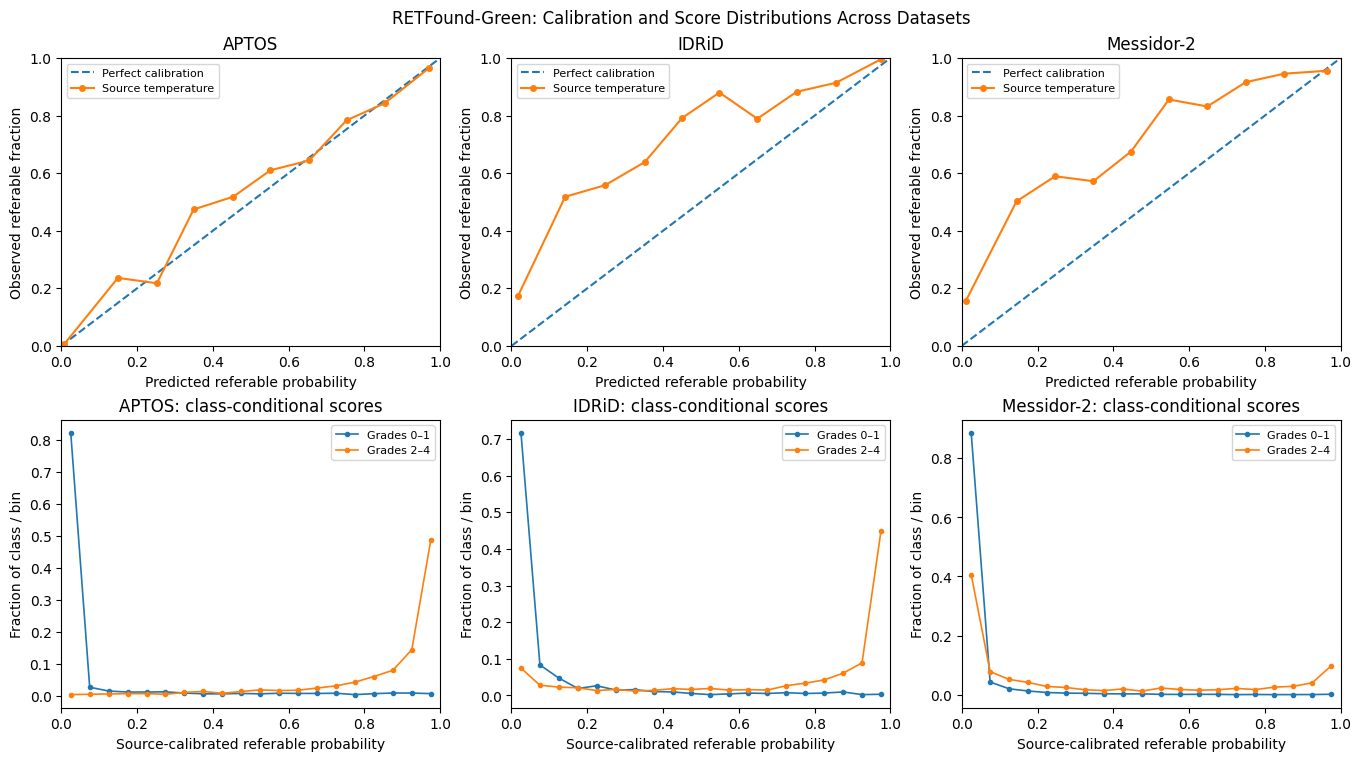


VERIFICATION PASSED
All 15 saved screening outcomes reproduced using the original APTOS source-selected policies.

Journal outputs saved:
/content/drive/MyDrive/thesis_DR/major_revision_M1/external_calibration_shift_figure.png
/content/drive/MyDrive/thesis_DR/major_revision_M1/external_calibration_metrics_table.csv
/content/drive/MyDrive/thesis_DR/major_revision_M1/external_grade_clearance_table.csv

Original files modified: NO
New folders created: NO
Model training: NONE
External threshold fitting: NONE


In [ ]:

# ============================================================
# EXTERNAL CALIBRATION AND DISTRIBUTION SHIFT ANALYSIS
#
# ONE COMPLETE CELL — replace the previously failed cell
#
# Outputs intended for the journal:
# 1. NLL, Brier score and ECE comparison table
# 2. Reliability and class-conditional score figure
# 3. Grade 2–4 missed-referral table
#
# Uses ORIGINAL APTOS 5% LTT source policy.
# Does not assume external saved thresholds are identical.
#
# No Drive mounting
# No new folders
# No training
# No image processing
# No modification of original CSV files
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit

ROOT = Path("/content/drive/MyDrive/thesis_DR")
OUT = ROOT / "major_revision_M1"

SEEDS = (42, 43, 44, 45, 46)
ALPHA = 0.05

SIZES = {
    "APTOS": 526,
    "IDRiD": 507,
    "Messidor-2": 1740
}

PRED_NAMES = {
    "APTOS": "aptos_retfound_raw_predictions.csv",
    "IDRiD": "idrid_retfound_raw_predictions.csv",
    "Messidor-2": "messidor2_retfound_raw_predictions.csv"
}

RESULT_NAMES = {
    "APTOS": "aptos_retfound_internal_test_results.csv",
    "IDRiD": "idrid_external_results.csv",
    "Messidor-2": "messidor2_external_results.csv"
}

POLICY_NAME = "aptos_retfound_ltt_risk_control.csv"
TEMP_NAME = "aptos_retfound_temperature_scaling.json"

# ============================================================
# 1. VERIFY ORIGINAL FILES
# ============================================================

files = [
    ROOT / name
    for name in (
        list(PRED_NAMES.values())
        + list(RESULT_NAMES.values())
        + [POLICY_NAME, TEMP_NAME]
    )
]

missing = [
    str(path)
    for path in files
    if not path.is_file()
]

if missing:
    raise FileNotFoundError(
        "Original files missing:\n"
        + "\n".join(missing)
    )

assert OUT.is_dir(), (
    f"Existing output folder not found: {OUT}"
)

# ============================================================
# 2. LOAD THE ACTUAL SOURCE LTT POLICY
#
# Authoritative source:
# aptos_retfound_ltt_risk_control.csv
#
# Do not select external thresholds using external labels.
# ============================================================

pol = pd.read_csv(ROOT / POLICY_NAME)

required_policy = {
    "seed",
    "alpha",
    "certified",
    "selected_threshold"
}

assert required_policy.issubset(pol.columns), (
    f"Missing source-policy columns: "
    f"{required_policy - set(pol.columns)}"
)

pol = pol.loc[
    np.isclose(
        pd.to_numeric(pol["alpha"], errors="coerce"),
        ALPHA,
        rtol=0,
        atol=1e-12
    )
].copy()

if (
    len(pol) != 5
    or set(pol["seed"].astype(int)) != set(SEEDS)
    or pol["seed"].duplicated().any()
):
    raise ValueError(
        "Expected exactly five original source policies "
        "for alpha=0.05. Inspect original LTT records."
    )

certified = (
    pol["certified"]
    .astype(str)
    .str.strip()
    .str.lower()
)

if not certified.eq("true").all():
    raise ValueError(
        "Not all original 5% source policies certified. "
        "No replacement thresholds will be invented."
    )

pol = pol.set_index("seed")

with open(ROOT / TEMP_NAME, encoding="utf-8") as f:
    temp_obj = json.load(f)

assert isinstance(temp_obj, dict)
assert "seeds" in temp_obj

sources = {}

for seed in SEEDS:

    temperature = float(
        temp_obj["seeds"][str(seed)]["temperature"]
    )

    threshold = float(
        pol.loc[seed, "selected_threshold"]
    )

    if not (
        np.isfinite(temperature)
        and temperature > 0
        and np.isfinite(threshold)
        and 0 <= threshold <= 1
    ):
        raise ValueError(
            f"Seed {seed}: invalid original source policy."
        )

    sources[seed] = (temperature, threshold)

print("PASS: Original APTOS 5% LTT policies loaded.")

# ============================================================
# 3. LOAD ORIGINAL SAVED EVALUATION RESULTS
# ============================================================

refs = {}

for dataset, filename in RESULT_NAMES.items():

    frame = pd.read_csv(ROOT / filename)

    if (
        "seed" not in frame.columns
        or len(frame) != 5
        or set(frame["seed"].astype(int)) != set(SEEDS)
        or frame["seed"].duplicated().any()
    ):
        raise ValueError(
            f"{dataset}: invalid original evaluation records."
        )

    frame["seed"] = frame["seed"].astype(int)

    refs[dataset] = frame.set_index("seed")

# ============================================================
# 4. LOAD AND VALIDATE RAW PREDICTIONS
# ============================================================

predictions = {}

for dataset, filename in PRED_NAMES.items():

    p = pd.read_csv(
        ROOT / filename,
        dtype={"image_id": str}
    )

    required = {
        "seed",
        "image_id",
        "original_grade",
        "binary_label",
        "raw_logit"
    }

    if dataset == "APTOS":
        required.add("split")

    if not required.issubset(p.columns):
        raise ValueError(
            f"{dataset}: missing columns "
            f"{required - set(p.columns)}"
        )

    p["seed"] = p["seed"].astype(int)

    if dataset == "APTOS":
        p = p.loc[
            p["split"] == "internal_test"
        ].copy()

    if (
        len(p) != SIZES[dataset] * 5
        or set(p["seed"]) != set(SEEDS)
    ):
        raise ValueError(
            f"{dataset}: incorrect image or seed count."
        )

    if p.duplicated(["seed", "image_id"]).any():
        raise ValueError(
            f"{dataset}: duplicate seed/image records."
        )

    p["original_grade"] = pd.to_numeric(
        p["original_grade"],
        errors="raise"
    ).astype(int)

    p["binary_label"] = pd.to_numeric(
        p["binary_label"],
        errors="raise"
    ).astype(int)

    logits = p["raw_logit"].to_numpy(float)

    if not np.isfinite(logits).all():
        raise ValueError(
            f"{dataset}: nonfinite logits."
        )

    if not p["original_grade"].isin(range(5)).all():
        raise ValueError(
            f"{dataset}: invalid severity grades."
        )

    labels = p["binary_label"].to_numpy(int)
    grades_array = p["original_grade"].to_numpy(int)

    if not np.array_equal(
        labels,
        (grades_array >= 2).astype(int)
    ):
        raise ValueError(
            f"{dataset}: binary labels disagree with grades."
        )

    if not p.groupby("seed").size().eq(
        SIZES[dataset]
    ).all():
        raise ValueError(
            f"{dataset}: unexpected per-seed sample sizes."
        )

    # External images and ground truth must remain fixed
    # across the five repeated model evaluations.

    if dataset != "APTOS":

        cols = [
            "image_id",
            "original_grade",
            "binary_label"
        ]

        baseline = (
            p.loc[p.seed == SEEDS[0], cols]
            .sort_values("image_id")
            .reset_index(drop=True)
        )

        for seed in SEEDS[1:]:

            current = (
                p.loc[p.seed == seed, cols]
                .sort_values("image_id")
                .reset_index(drop=True)
            )

            if not baseline.equals(current):
                raise ValueError(
                    f"{dataset}: image identities or "
                    "ground-truth labels differ across seeds."
                )

    predictions[dataset] = p

print("PASS: All source and external prediction records verified.")

# ============================================================
# 5. CALIBRATION METRIC
# 10 equal-width probability bins
# ============================================================

def expected_calibration_error(prob, labels, bins=10):

    indices = np.minimum(
        (prob * bins).astype(int),
        bins - 1
    )

    counts = np.bincount(
        indices,
        minlength=bins
    )

    prob_sum = np.bincount(
        indices,
        weights=prob,
        minlength=bins
    )

    label_sum = np.bincount(
        indices,
        weights=labels,
        minlength=bins
    )

    used = counts > 0

    return float(
        np.sum(
            np.abs(
                prob_sum[used] / counts[used]
                - label_sum[used] / counts[used]
            ) * counts[used]
        ) / len(labels)
    )

# ============================================================
# 6. CALCULATE METRICS AND AUDIT FROZEN DECISIONS
# ============================================================

calibration_rows = []
grade_rows = []
audit_rows = []

curves = {
    name: []
    for name in PRED_NAMES
}

histograms = {
    name: {0: [], 1: []}
    for name in PRED_NAMES
}

for dataset, p in predictions.items():

    for seed in SEEDS:

        d = p.loc[p.seed == seed]

        y = d["binary_label"].to_numpy(int)
        grades = d["original_grade"].to_numpy(int)
        logits = d["raw_logit"].to_numpy(float)

        temperature, source_threshold = sources[seed]

        # Original APTOS-fitted probability calibration.
        raw_prob = expit(logits)

        calibrated_logits = logits / temperature
        calibrated_prob = expit(calibrated_logits)

        # Original APTOS-selected 5% LTT threshold.
        clear = calibrated_prob <= source_threshold

        cleared_n = int(clear.sum())
        error_n = int(y[clear].sum())

        saved = refs[dataset].loc[seed]

        # Read each dataset's ACTUAL saved fields.
        # These are AUDIT FIELDS, not replacement policies.

        if dataset == "IDRiD":

            threshold_field = "ltt_threshold"
            clear_field = "auto_clear"
            error_field = "auto_clear_errors"

        else:

            threshold_field = "frozen_threshold"
            clear_field = "auto_clear_count"
            error_field = "referable_auto_clear_errors"

        saved_threshold = float(
            saved[threshold_field]
        )

        saved_clear = int(
            saved[clear_field]
        )

        saved_errors = int(
            saved[error_field]
        )

        count_match = (
            cleared_n == saved_clear
            and error_n == saved_errors
        )

        audit_row = {
            "dataset": dataset,
            "seed": seed,
            "APTOS_source_threshold": source_threshold,
            "saved_result_threshold": saved_threshold,
            "threshold_difference": (
                saved_threshold - source_threshold
            ),
            "source_policy_clear": cleared_n,
            "saved_clear": saved_clear,
            "source_policy_errors": error_n,
            "saved_errors": saved_errors,
            "screening_counts_match": count_match
        }

        # Independently check any saved temperature.
        if "temperature" in saved.index:

            saved_temperature = float(
                saved["temperature"]
            )

            if not np.isclose(
                temperature,
                saved_temperature,
                atol=1e-6,
                rtol=1e-6
            ):
                audit_row["saved_temperature_differs"] = True

        # ----------------------------------------------------
        # 6A. Raw and calibrated probability metrics
        # ----------------------------------------------------

        metrics = {
            "dataset": dataset,
            "seed": seed,
            "n": len(y),

            "raw_nll": float(
                np.mean(
                    np.logaddexp(0.0, logits)
                    - y * logits
                )
            ),

            "calibrated_nll": float(
                np.mean(
                    np.logaddexp(0.0, calibrated_logits)
                    - y * calibrated_logits
                )
            ),

            "raw_brier": float(
                np.mean((raw_prob - y) ** 2)
            ),

            "calibrated_brier": float(
                np.mean((calibrated_prob - y) ** 2)
            ),

            "raw_ece": expected_calibration_error(
                raw_prob, y
            ),

            "calibrated_ece": expected_calibration_error(
                calibrated_prob, y
            )
        }

        # IDRiD has previously saved calibration metrics.
        # Verify them instead of assuming our calculations
        # reproduce the original results.

        if dataset == "IDRiD":

            for field in (
                "raw_nll",
                "calibrated_nll",
                "raw_brier",
                "calibrated_brier"
            ):

                if not np.isclose(
                    metrics[field],
                    float(saved[field]),
                    atol=1e-5,
                    rtol=1e-5
                ):
                    audit_row[f"{field}_mismatch"] = True

        audit_rows.append(audit_row)
        calibration_rows.append(metrics)

        # ----------------------------------------------------
        # 6B. Grade-conditioned missed referrals
        #
        # Grades 2–4 are referable.
        # This is grade-specific clearance, NOT
        # conditional risk among all auto-cleared images.
        # ----------------------------------------------------

        if dataset != "APTOS":

            for grade in (2, 3, 4):

                grade_mask = grades == grade

                total_grade = int(grade_mask.sum())

                if total_grade == 0:
                    raise ValueError(
                        f"{dataset}, seed {seed}: "
                        f"no grade-{grade} images."
                    )

                cleared_grade = int(
                    (grade_mask & clear).sum()
                )

                grade_rows.append({
                    "dataset": dataset,
                    "seed": seed,
                    "grade": grade,
                    "n_images": total_grade,
                    "cleared_n": cleared_grade,
                    "grade_miss_pct": (
                        100 * cleared_grade / total_grade
                    )
                })

        # ----------------------------------------------------
        # 6C. Reliability diagram
        # ----------------------------------------------------

        indices = np.minimum(
            (calibrated_prob * 10).astype(int),
            9
        )

        curve = np.full(
            (10, 2),
            np.nan,
            dtype=float
        )

        for bin_index in range(10):

            mask = indices == bin_index

            if mask.any():

                curve[bin_index] = [
                    calibrated_prob[mask].mean(),
                    y[mask].mean()
                ]

        curves[dataset].append(curve)

        # ----------------------------------------------------
        # 6D. Class-conditional score distributions
        # ----------------------------------------------------

        for label in (0, 1):

            class_probs = calibrated_prob[
                y == label
            ]

            if len(class_probs) == 0:
                raise ValueError(
                    f"{dataset}, seed {seed}: "
                    f"binary class {label} absent."
                )

            counts = np.histogram(
                class_probs,
                bins=np.linspace(0, 1, 21)
            )[0]

            histograms[dataset][label].append(
                counts / len(class_probs)
            )

# ============================================================
# 7. PRINT ACTUAL SOURCE VS SAVED THRESHOLD DIFFERENCES
#
# This replaces the previous incorrect equality assumption.
# ============================================================

audit = pd.DataFrame(audit_rows)

print("\n" + "=" * 75)
print("SOURCE POLICY VS ORIGINAL SAVED SCREENING RESULTS")
print("=" * 75)

print(
    audit[
        [
            "dataset",
            "seed",
            "APTOS_source_threshold",
            "saved_result_threshold",
            "threshold_difference",
            "source_policy_clear",
            "saved_clear",
            "source_policy_errors",
            "saved_errors",
            "screening_counts_match"
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.9f}"
    )
)

all_counts_match = bool(
    audit["screening_counts_match"].all()
)

# Detect actual mismatches in previously saved temperature
# and independently recorded IDRiD probability metrics.

validation_columns = [
    col
    for col in audit.columns
    if (
        col.endswith("_mismatch")
        or col == "saved_temperature_differs"
    )
]

if validation_columns:

    invalid_calibration = bool(
        audit[validation_columns]
        .fillna(False)
        .any()
        .any()
    )

else:
    invalid_calibration = False

# ============================================================
# 8. JOURNAL TABLE — PROBABILITY CALIBRATION
# ============================================================

metric_data = pd.DataFrame(calibration_rows)

metric_fields = (
    "raw_nll",
    "calibrated_nll",
    "raw_brier",
    "calibrated_brier",
    "raw_ece",
    "calibrated_ece"
)

calibration_table = metric_data.groupby(
    "dataset",
    sort=False
).agg({
    column: ["mean", "std"]
    for column in metric_fields
})

calibration_table.columns = [
    f"{metric}_{stat}"
    for metric, stat in calibration_table.columns
]

calibration_table = (
    calibration_table.reset_index()
)

print("\n" + "=" * 75)
print("JOURNAL TABLE: RAW VS CALIBRATED PROBABILITIES")
print("=" * 75)

print(
    calibration_table.round(4).to_string(
        index=False
    )
)

# ============================================================
# 9. JOURNAL TABLE — GRADE-SPECIFIC MISSED REFERRALS
# ============================================================

grade_data = pd.DataFrame(grade_rows)

grade_table = grade_data.groupby(
    ["dataset", "grade"],
    sort=False
).agg(
    n_images=("n_images", "first"),
    mean_cleared_n=("cleared_n", "mean"),
    grade_miss_mean_pct=("grade_miss_pct", "mean"),
    grade_miss_sd_pct=("grade_miss_pct", "std")
).reset_index()

print("\n" + "=" * 75)
print("JOURNAL TABLE: GRADE 2–4 MISSED REFERRALS")
print("=" * 75)

print(
    grade_table.round(3).to_string(
        index=False
    )
)

# ============================================================
# 10. JOURNAL FIGURE
#
# Top: source-temperature reliability across datasets
# Bottom: class-conditional prediction-score distributions
# ============================================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(13.5, 7.5),
    constrained_layout=True
)

centers = (
    np.arange(20) + 0.5
) / 20

for column, dataset in enumerate(PRED_NAMES):

    top = axes[0, column]

    top.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Perfect calibration"
    )

    stacked = np.stack(
        curves[dataset],
        axis=0
    )

    plot_x = []
    plot_y = []

    for bin_index in range(10):

        valid = (
            np.isfinite(
                stacked[:, bin_index, 0]
            )
            & np.isfinite(
                stacked[:, bin_index, 1]
            )
        )

        if valid.any():

            plot_x.append(
                float(
                    stacked[
                        valid, bin_index, 0
                    ].mean()
                )
            )

            plot_y.append(
                float(
                    stacked[
                        valid, bin_index, 1
                    ].mean()
                )
            )

    top.plot(
        plot_x,
        plot_y,
        marker="o",
        markersize=4,
        label="Source temperature"
    )

    top.set(
        title=dataset,
        xlabel="Predicted referable probability",
        ylabel="Observed referable fraction",
        xlim=(0, 1),
        ylim=(0, 1)
    )

    top.legend(fontsize=8)

    # Class-conditional score distributions.

    bottom = axes[1, column]

    for label, name in (
        (0, "Grades 0–1"),
        (1, "Grades 2–4")
    ):

        fractions = np.stack(
            histograms[dataset][label]
        ).mean(axis=0)

        bottom.plot(
            centers,
            fractions,
            marker=".",
            linewidth=1.2,
            label=name
        )

    bottom.set(
        title=f"{dataset}: class-conditional scores",
        xlabel="Source-calibrated referable probability",
        ylabel="Fraction of class / bin",
        xlim=(0, 1)
    )

    bottom.legend(fontsize=8)

fig.suptitle(
    "RETFound-Green: Calibration and Score "
    "Distributions Across Datasets"
)

# ============================================================
# 11. FINAL VERIFICATION AND SAVE
#
# If original evaluations disagree with our calculations,
# DO NOT save provisional results as journal evidence.
# ============================================================

if invalid_calibration or not all_counts_match:

    print("\n" + "=" * 75)
    print("VERIFICATION REQUIRES REVIEW — NO OUTPUTS SAVED")
    print("=" * 75)

    if invalid_calibration:
        print(
            "The source temperature or existing IDRiD "
            "NLL/Brier values do not reproduce."
        )

    if not all_counts_match:
        print(
            "Some original external screening counts "
            "do not match the APTOS-frozen source policy."
        )

    print(
        "The tables and figure are displayed for "
        "diagnosis only, NOT verified journal results."
    )

    plt.show()
    plt.close(fig)

else:

    figure_path = (
        OUT / "external_calibration_shift_figure.png"
    )

    calibration_path = (
        OUT / "external_calibration_metrics_table.csv"
    )

    grade_path = (
        OUT / "external_grade_clearance_table.csv"
    )

    fig.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight"
    )

    calibration_table.to_csv(
        calibration_path,
        index=False
    )

    grade_table.to_csv(
        grade_path,
        index=False
    )

    plt.show()
    plt.close(fig)

    print("\n" + "=" * 75)
    print("VERIFICATION PASSED")
    print("=" * 75)

    print(
        "All 15 saved screening outcomes reproduced "
        "using the original APTOS source-selected policies."
    )

    print("\nJournal outputs saved:")

    for path in (
        figure_path,
        calibration_path,
        grade_path
    ):
        print(path)

print("\nOriginal files modified: NO")
print("New folders created: NO")
print("Model training: NONE")
print("External threshold fitting: NONE")


PASS: Source temperatures and prediction records verified.


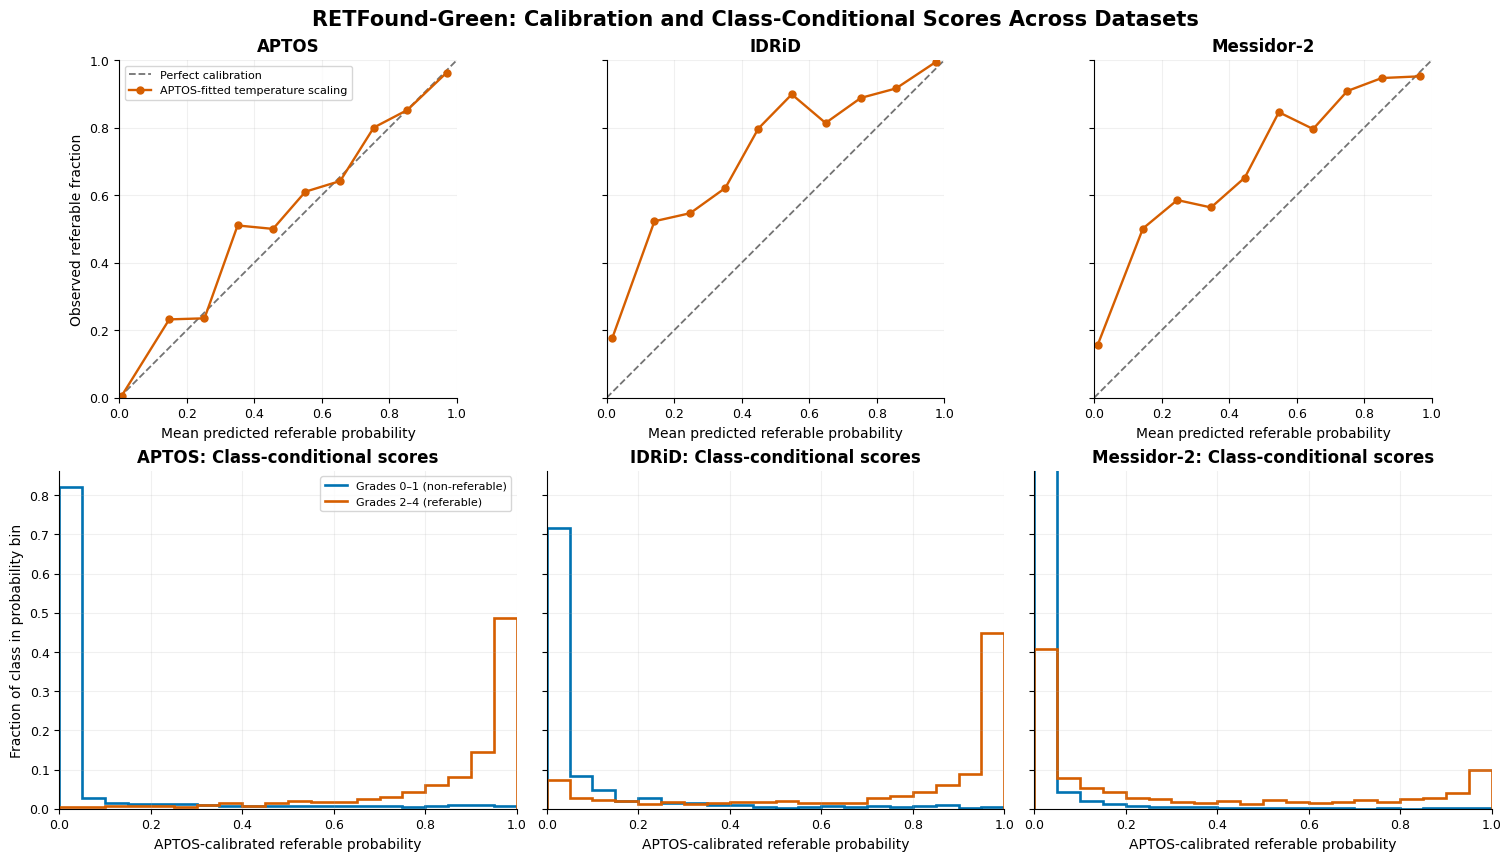


FIGURE UPDATED: /content/drive/MyDrive/thesis_DR/major_revision_M1/external_calibration_shift_figure.png
Images per seed: {'APTOS': 526, 'IDRiD': 507, 'Messidor-2': 1740}
Model seeds: (42, 43, 44, 45, 46)
Reliability: 10 probability bins, five evaluations.
Histograms: normalized per class, averaged over seeds.
Original files modified: NO
Additional tables created: NONE
New folders: NONE
Model training: NONE


In [ ]:

# ============================================================
# JOURNAL FIGURE ONLY — CALIBRATION AND SCORE DISTRIBUTIONS
# Uses verified original prediction files and APTOS temperatures
# No training, no new folders, no extra CSV files
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit

ROOT = Path("/content/drive/MyDrive/thesis_DR")
OUT = ROOT / "major_revision_M1"

PRED_FILES = {
    "APTOS": "aptos_retfound_raw_predictions.csv",
    "IDRiD": "idrid_retfound_raw_predictions.csv",
    "Messidor-2": "messidor2_retfound_raw_predictions.csv",
}

SEEDS = (42, 43, 44, 45, 46)

temp_path = ROOT / "aptos_retfound_temperature_scaling.json"

required_paths = [
    ROOT / filename for filename in PRED_FILES.values()
] + [temp_path]

missing = [
    str(p) for p in required_paths if not p.is_file()
]

if missing:
    raise FileNotFoundError(
        "Missing original files: " + ", ".join(missing)
    )

if not OUT.is_dir():
    raise FileNotFoundError(
        f"Existing output folder missing: {OUT}"
    )

# ------------------------------------------------------------
# 1. Load original APTOS-fitted temperature parameters
# ------------------------------------------------------------

with temp_path.open(encoding="utf-8") as f:
    temp_json = json.load(f)

temperatures = {}

for seed in SEEDS:
    T = float(temp_json["seeds"][str(seed)]["temperature"])

    if not (np.isfinite(T) and T > 0):
        raise ValueError(
            f"Invalid original temperature for seed {seed}"
        )

    temperatures[seed] = T

# ------------------------------------------------------------
# 2. Load, validate and summarize existing predictions
# ------------------------------------------------------------

reliability = {}
class_histograms = {}
counts_per_seed = {}

edges = np.linspace(0, 1, 21)

for dataset, filename in PRED_FILES.items():

    df = pd.read_csv(
        ROOT / filename,
        dtype={"image_id": str}
    )

    required = {
        "seed", "image_id", "original_grade",
        "binary_label", "raw_logit"
    }

    if dataset == "APTOS":
        required.add("split")

    if not required.issubset(df.columns):
        raise ValueError(
            f"{filename}: missing "
            f"{required - set(df.columns)}"
        )

    if dataset == "APTOS":
        df = df.loc[
            df["split"].eq("internal_test")
        ].copy()

    df["seed"] = pd.to_numeric(
        df["seed"], errors="raise"
    ).astype(int)

    if (
        set(df["seed"]) != set(SEEDS)
        or df.duplicated(["seed", "image_id"]).any()
    ):
        raise ValueError(
            f"{dataset}: invalid seed/image records"
        )

    n_by_seed = df.groupby("seed").size()

    if (
        len(set(n_by_seed)) != 1
        or int(n_by_seed.iloc[0]) == 0
    ):
        raise ValueError(
            f"{dataset}: unequal or empty per-seed cohorts"
        )

    counts_per_seed[dataset] = int(n_by_seed.iloc[0])

    # Confirm external image identities and labels are
    # consistent across the five model evaluations.

    if dataset != "APTOS":

        baseline = None

        for seed in SEEDS:

            current = (
                df.loc[
                    df.seed.eq(seed),
                    ["image_id", "original_grade", "binary_label"]
                ]
                .sort_values("image_id")
                .reset_index(drop=True)
            )

            if (
                baseline is not None
                and not current.equals(baseline)
            ):
                raise ValueError(
                    f"{dataset}: image/label records "
                    "differ across seeds"
                )

            baseline = current

    # Reliability: accumulate bin counts across all
    # five repeated predictions, without treating them
    # as independent patient observations.

    counts10 = np.zeros(10, dtype=int)
    sum_prob10 = np.zeros(10, dtype=float)
    sum_label10 = np.zeros(10, dtype=float)

    # Distribution: normalize within each class and seed,
    # then average the five seed-specific histograms.

    hist_by_class = {0: [], 1: []}

    for seed in SEEDS:

        part = df.loc[df.seed.eq(seed)]

        grades = pd.to_numeric(
            part["original_grade"],
            errors="raise"
        ).to_numpy(float)

        labels = pd.to_numeric(
            part["binary_label"],
            errors="raise"
        ).to_numpy(float)

        logits = pd.to_numeric(
            part["raw_logit"],
            errors="raise"
        ).to_numpy(float)

        if (
            not np.isfinite(logits).all()
            or not np.isin(grades, range(5)).all()
            or not np.isin(labels, [0, 1]).all()
            or not np.array_equal(
                labels.astype(int),
                (grades >= 2).astype(int)
            )
        ):
            raise ValueError(
                f"{dataset} seed {seed}: "
                "invalid logits, grades or labels"
            )

        # Apply ORIGINAL source-fitted temperature only.
        probabilities = expit(
            logits / temperatures[seed]
        )

        # 10 equal-width reliability bins.

        indices = np.minimum(
            (probabilities * 10).astype(int), 9
        )

        counts10 += np.bincount(
            indices, minlength=10
        )

        sum_prob10 += np.bincount(
            indices,
            weights=probabilities,
            minlength=10
        )

        sum_label10 += np.bincount(
            indices,
            weights=labels,
            minlength=10
        )

        # 20-bin class-conditional probability histograms.

        for label in (0, 1):

            selected = probabilities[labels == label]

            if len(selected) == 0:
                raise ValueError(
                    f"{dataset} seed {seed}: "
                    f"class {label} absent"
                )

            hist = np.histogram(
                selected, bins=edges
            )[0]

            hist_by_class[label].append(
                hist / len(selected)
            )

    occupied = counts10 > 0

    reliability[dataset] = (
        sum_prob10[occupied] / counts10[occupied],
        sum_label10[occupied] / counts10[occupied]
    )

    class_histograms[dataset] = {
        label: np.mean(hist_by_class[label], axis=0)
        for label in (0, 1)
    }

print("PASS: Source temperatures and prediction records verified.")

# ------------------------------------------------------------
# 3. Generate improved journal figure
# ------------------------------------------------------------

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8,
    "axes.spines.top": False,
    "axes.spines.right": False,
}):

    fig, axes = plt.subplots(
        2, 3,
        figsize=(15, 8.5),
        sharey="row",
        constrained_layout=True
    )

    blue = "#0072B2"
    orange = "#D55E00"

    for j, dataset in enumerate(PRED_FILES):

        # ----------------------------------------------------
        # TOP ROW: Reliability diagram
        # ----------------------------------------------------

        ax = axes[0, j]

        ax.plot(
            [0, 1], [0, 1],
            linestyle="--",
            linewidth=1.3,
            color="0.45",
            label="Perfect calibration"
        )

        predicted, observed = reliability[dataset]

        ax.plot(
            predicted,
            observed,
            color=orange,
            marker="o",
            markersize=5,
            linewidth=1.7,
            label="APTOS-fitted temperature scaling"
        )

        ax.set_title(dataset, fontweight="bold")

        ax.set_xlabel(
            "Mean predicted referable probability"
        )

        if j == 0:
            ax.set_ylabel(
                "Observed referable fraction"
            )
            ax.legend(
                loc="upper left",
                frameon=True
            )

        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)

        ax.set_xticks(np.linspace(0, 1, 6))
        ax.set_yticks(np.linspace(0, 1, 6))

        ax.set_aspect("equal", adjustable="box")
        ax.grid(alpha=0.18)

        # ----------------------------------------------------
        # BOTTOM ROW: Class-conditional score distributions
        # Step plots show the actual histogram bins.
        # ----------------------------------------------------

        ax = axes[1, j]

        ax.stairs(
            class_histograms[dataset][0],
            edges,
            color=blue,
            linewidth=1.9,
            label="Grades 0–1 (non-referable)"
        )

        ax.stairs(
            class_histograms[dataset][1],
            edges,
            color=orange,
            linewidth=1.9,
            label="Grades 2–4 (referable)"
        )

        ax.set_title(
            f"{dataset}: Class-conditional scores",
            fontweight="bold"
        )

        ax.set_xlabel(
            "APTOS-calibrated referable probability"
        )

        if j == 0:
            ax.set_ylabel(
                "Fraction of class in probability bin"
            )
            ax.legend(
                loc="upper right",
                frameon=True
            )

        ax.set_xlim(0, 1)
        ax.set_ylim(bottom=0)

        ax.set_xticks(np.linspace(0, 1, 6))

        ax.grid(alpha=0.18)

    fig.suptitle(
        "RETFound-Green: Calibration and "
        "Class-Conditional Scores Across Datasets",
        fontsize=15,
        fontweight="semibold"
    )

    # --------------------------------------------------------
    # 4. Save ONLY the existing journal figure
    # --------------------------------------------------------

    figure_path = (
        OUT / "external_calibration_shift_figure.png"
    )

    fig.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)

print("\nFIGURE UPDATED:", figure_path)
print("Images per seed:", counts_per_seed)
print("Model seeds:", SEEDS)
print("Reliability: 10 probability bins, five evaluations.")
print("Histograms: normalized per class, averaged over seeds.")
print("Original files modified: NO")
print("Additional tables created: NONE")
print("New folders: NONE")
print("Model training: NONE")


#**Statistical Uncertainty, Calibration Consistency, Preprocessing Sensitivity, and Reproducibility Audit**

In [ ]:

# ============================================================
# REMAINING REVIEWER ANALYSES — ONE COLAB CELL
# Existing experimental records only; no model training
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
from scipy.special import expit, logit
from scipy.stats import beta, binomtest
from sklearn.metrics import roc_auc_score

ROOT = Path("/content/drive/MyDrive/thesis_DR")
OUT = ROOT / "major_revision_M1"
SEEDS = (42, 43, 44, 45, 46)
ALPHA = 0.05

# Filenames checked against the existing 33-file inventory.
NAMES = {
    "source_ltt": "aptos_retfound_ltt_risk_control.csv",
    "dino_ltt": "aptos_dinov2_large_ltt_risk_control.csv",
    "med_ltt": "aptos_medsiglip_ltt_risk_control.csv",
    "temps": "aptos_retfound_temperature_scaling.json",
    "aptos_pred": "aptos_retfound_raw_predictions.csv",
    "idrid_pred": "idrid_retfound_raw_predictions.csv",
    "mess_pred": "messidor2_retfound_raw_predictions.csv",
    "aptos_results": "aptos_retfound_internal_test_results.csv",
    "idrid_results": "idrid_external_results.csv",
    "mess_results": "messidor2_external_results.csv",
    "alt_preproc": "messidor2_aptos_preprocess_sensitivity_predictions.csv",
    "aptos_manifest": "aptos_split_manifest.csv",
    "aptos_audit": "aptos_exact_duplicate_audit.csv",
    "idrid_audit": "idrid_exact_duplicate_audit.csv",
    "mess_manifest": "messidor2_recert_split_manifest.csv",
}

missing = [
    name for name, filename in NAMES.items()
    if not (ROOT / filename).is_file()
]

if missing or not OUT.is_dir():
    raise FileNotFoundError(
        f"Missing files: {missing}; "
        f"existing output folder: {OUT.is_dir()}"
    )

def csv(key):
    return pd.read_csv(
        ROOT / NAMES[key],
        dtype={"image_id": str, "original_image_id": str}
    )

def need(df, columns, context):
    unknown = set(columns) - set(df.columns)
    if unknown:
        raise ValueError(
            f"{context}: missing columns {sorted(unknown)}"
        )

def flag(series, context):
    mapping = {
        "true": True, "false": False,
        "1": True, "0": False,
        "1.0": True, "0.0": False
    }
    converted = (
        series.astype(str).str.strip().str.lower()
        .map(mapping)
    )
    if converted.isna().any():
        raise ValueError(
            f"{context}: unexpected Boolean values "
            f"{series[converted.isna()].unique().tolist()}"
        )
    return converted.to_numpy(bool)

def strict_ids(df, columns, context):
    if (
        df[columns].isna().any().any()
        or df.duplicated(columns).any()
    ):
        raise ValueError(
            f"{context}: missing or duplicate identifiers"
        )

def verified_upper(k, n, saved, context):
    calculated = (
        1.0 if k == n
        else float(beta.ppf(0.95, k + 1, n - k))
    )
    saved = float(saved)

    # Verify whether the existing file stores
    # confidence bounds as fractions or percentages.
    alternatives = [
        (abs(saved - calculated), "fraction"),
        (abs(saved / 100 - calculated), "percent")
    ]
    difference, unit = min(alternatives)

    if not np.isfinite(difference) or difference > 5e-4:
        raise ValueError(
            f"{context}: saved upper bound {saved} "
            f"does not reproduce {calculated:.8f}"
        )

    return calculated, unit

# ============================================================
# PART 1 — ORIGINAL SOURCE CERTIFICATION RECORDS
# ============================================================

with (ROOT / NAMES["temps"]).open(encoding="utf-8") as f:
    temp_json = json.load(f)

source = {}
cert_frames = []

for encoder, key in (
    ("RETFound-Green", "source_ltt"),
    ("DINOv2-Large", "dino_ltt"),
    ("MedSigLIP", "med_ltt")
):

    p = csv(key)

    fields = [
        "seed", "alpha", "delta", "method",
        "candidate_count", "risk_calibration_n",
        "certified", "selected_sequence_position",
        "selected_threshold", "selected_p_value",
        "empirical_ltt_loss", "first_failed_threshold",
        "first_failed_p_value", "ordering_source",
        "candidate_grid_source",
        "certified_candidates_before_stop"
    ]
    need(p, fields, key)

    p["seed"] = pd.to_numeric(
        p["seed"], errors="raise"
    ).astype(int)
    p["alpha"] = pd.to_numeric(
        p["alpha"], errors="raise"
    )

    if (
        len(p) != 15
        or set(p.seed) != set(SEEDS)
        or set(np.round(p.alpha, 5)) != {0.01, 0.02, 0.05}
        or p.duplicated(["seed", "alpha"]).any()
    ):
        raise ValueError(
            f"{key}: original LTT records do not match "
            "the recorded experimental design."
        )

    p["certified"] = flag(p["certified"], key)
    p.insert(0, "encoder", encoder)
    cert_frames.append(p)

    if key == "source_ltt":

        for seed in SEEDS:
            selected = p.loc[
                p.seed.eq(seed)
                & np.isclose(
                    p.alpha, ALPHA, atol=1e-12, rtol=0
                )
            ]

            if (
                len(selected) != 1
                or not bool(selected.iloc[0]["certified"])
            ):
                raise ValueError(
                    f"Seed {seed}: missing original "
                    "certified 5% source policy."
                )

            threshold = float(
                selected.iloc[0]["selected_threshold"]
            )
            T = float(
                temp_json["seeds"][str(seed)]["temperature"]
            )

            if not (
                0 < threshold < 1
                and np.isfinite(T)
                and T > 0
            ):
                raise ValueError(
                    f"Seed {seed}: invalid source parameters."
                )

            source[seed] = (T, threshold)

cert_table = pd.concat(cert_frames, ignore_index=True)

print("PASS: Three original encoder LTT record sets loaded.")
print("NOTE: Stored source p-values are not independently recomputed.")

# ============================================================
# PART 2 — EXTERNAL STATISTICAL UNCERTAINTY
# AND RAW VS TEMPERATURE-SCALED DECISIONS
# ============================================================

datasets = {
    "APTOS": (
        "aptos_pred", "aptos_results", 526,
        "auto_clear_count",
        "referable_auto_clear_errors",
        "frozen_threshold",
        "risk_upper_95_one_sided"
    ),
    "IDRiD": (
        "idrid_pred", "idrid_results", 507,
        "auto_clear", "auto_clear_errors",
        "ltt_threshold", "upper_95_risk_bound"
    ),
    "Messidor-2": (
        "mess_pred", "mess_results", 1740,
        "auto_clear_count",
        "referable_auto_clear_errors",
        "frozen_threshold", "upper_95_risk_bound"
    )
}

predictions = {}
saved_results = {}
uncertainty = []
temperature_results = []

for dataset, info in datasets.items():

    (
        pred_key, result_key, expected_n,
        clear_field, error_field,
        threshold_field, upper_field
    ) = info

    df = csv(pred_key)
    ref = csv(result_key)

    need(
        df,
        ["seed", "image_id", "original_grade",
         "binary_label", "raw_logit"],
        pred_key
    )
    need(
        ref,
        ["seed", clear_field, error_field,
         threshold_field, upper_field],
        result_key
    )

    if dataset == "APTOS":
        need(df, ["split"], pred_key)
        df = df.loc[
            df["split"].eq("internal_test")
        ].copy()

    df["seed"] = pd.to_numeric(
        df["seed"], errors="raise"
    ).astype(int)
    ref["seed"] = pd.to_numeric(
        ref["seed"], errors="raise"
    ).astype(int)

    strict_ids(df, ["seed", "image_id"], pred_key)

    if (
        len(ref) != 5
        or set(ref.seed) != set(SEEDS)
        or ref.seed.duplicated().any()
        or set(df.seed) != set(SEEDS)
        or not df.groupby("seed").size().eq(expected_n).all()
    ):
        raise ValueError(
            f"{dataset}: original cohort/seed records mismatch."
        )

    df["original_grade"] = pd.to_numeric(
        df["original_grade"], errors="raise"
    ).astype(int)
    df["binary_label"] = pd.to_numeric(
        df["binary_label"], errors="raise"
    ).astype(int)

    if (
        not df.original_grade.isin(range(5)).all()
        or not df.binary_label.eq(
            df.original_grade.ge(2).astype(int)
        ).all()
        or not np.isfinite(
            pd.to_numeric(df.raw_logit).to_numpy(float)
        ).all()
    ):
        raise ValueError(
            f"{dataset}: invalid labels, grades, or logits."
        )

    # Same external images and labels across five seeds.
    if dataset != "APTOS":
        baseline = None
        for seed in SEEDS:
            current = (
                df.loc[
                    df.seed.eq(seed),
                    ["image_id", "original_grade",
                     "binary_label"]
                ]
                .sort_values("image_id")
                .reset_index(drop=True)
            )
            if baseline is not None and not current.equals(baseline):
                raise ValueError(
                    f"{dataset}: external image/label mismatch."
                )
            baseline = current

    ref = ref.set_index("seed")
    predictions[dataset] = df
    saved_results[dataset] = ref

    for seed in SEEDS:

        d = df.loc[df.seed.eq(seed)]

        y = d.binary_label.to_numpy(int)
        logits = d.raw_logit.to_numpy(float)

        T, threshold = source[seed]

        calibrated_prob = expit(logits / T)
        calibrated_clear = calibrated_prob <= threshold

        # Equivalent RAW probability threshold.
        # Positive temperature scaling is monotonic.
        raw_threshold = float(
            expit(T * logit(threshold))
        )
        raw_clear = expit(logits) <= raw_threshold

        discordant = int(
            np.count_nonzero(
                calibrated_clear != raw_clear
            )
        )

        cleared = int(calibrated_clear.sum())
        errors = int(y[calibrated_clear].sum())

        original = ref.loc[seed]

        if (
            cleared != int(original[clear_field])
            or errors != int(original[error_field])
        ):
            raise ValueError(
                f"{dataset} seed {seed}: original screening "
                "counts not reproduced."
            )

        # IDRiD threshold is stored rounded to 6 decimals.
        # Use original full-precision source LTT threshold.
        if not np.isclose(
            float(original[threshold_field]),
            threshold, rtol=0, atol=5e-7
        ):
            raise ValueError(
                f"{dataset} seed {seed}: source threshold mismatch."
            )

        if discordant:
            raise ValueError(
                f"{dataset} seed {seed}: "
                f"{discordant} discordant decisions between "
                "mathematically equivalent thresholds."
            )

        temperature_results.append({
            "dataset": dataset,
            "seed": seed,
            "temperature": T,
            "calibrated_source_threshold": threshold,
            "equivalent_raw_threshold": raw_threshold,
            "evaluated_n": len(y),
            "identical_decisions": len(y) - discordant,
            "auto_clear_n": cleared,
            "false_clear_n": errors,
            "discordant_decisions": discordant,
            "observed_risk_pct": (
                100 * errors / cleared
                if cleared else np.nan
            )
        })

        if dataset != "APTOS":

            upper, unit = verified_upper(
                errors, cleared,
                original[upper_field],
                f"{dataset} seed {seed}"
            )

            # One-sided 95% Clopper–Pearson LOWER bound.
            lower = (
                0.0 if errors == 0
                else float(
                    beta.ppf(
                        0.05, errors,
                        cleared - errors + 1
                    )
                )
            )

            # H0: external conditional risk <= 5%.
            # H1: external conditional risk > 5%.
            pvalue = float(
                binomtest(
                    errors, cleared,
                    p=ALPHA,
                    alternative="greater"
                ).pvalue
            )

            uncertainty.append({
                "dataset": dataset,
                "seed": seed,
                "auto_clear_n": cleared,
                "false_clear_n": errors,
                "observed_risk_pct": 100 * errors / cleared,
                "lower_95_one_sided_pct": 100 * lower,
                "upper_95_one_sided_pct": 100 * upper,
                "p_value_risk_gt_5pct": pvalue,
                "lower_bound_exceeds_5pct": bool(
                    lower > ALPHA
                ),
                "saved_upper_unit": unit
            })

print("PASS: All 15 frozen screening outcomes reproduced.")
print("PASS: Saved external upper risk bounds reproduced.")
print("PASS: Raw and scaled equivalent decisions match.")

# ============================================================
# PART 3 — EXISTING MESSIDOR-2 PREPROCESSING SENSITIVITY
# ============================================================

alt = csv("alt_preproc")

need(
    alt,
    ["seed", "image_id", "original_grade",
     "binary_label", "raw_logit", "p_calibrated",
     "auto_clear", "preprocessing"],
    NAMES["alt_preproc"]
)

alt["seed"] = pd.to_numeric(
    alt["seed"], errors="raise"
).astype(int)

strict_ids(alt, ["seed", "image_id"], "alternative preprocessing")

if (
    set(alt.seed) != set(SEEDS)
    or not alt.groupby("seed").size().eq(1740).all()
):
    raise ValueError(
        "Alternative preprocessing cohort is incomplete."
    )

merged = predictions["Messidor-2"].merge(
    alt,
    on=["seed", "image_id"],
    how="outer",
    suffixes=("_original", "_alternative"),
    indicator=True,
    validate="one_to_one"
)

if not merged["_merge"].eq("both").all():
    raise ValueError(
        "Original/alternative image identities do not match."
    )

for col in ("original_grade", "binary_label"):
    if not np.array_equal(
        merged[f"{col}_original"].to_numpy(),
        merged[f"{col}_alternative"].to_numpy()
    ):
        raise ValueError(
            f"Preprocessing ground-truth mismatch: {col}"
        )

preprocessing = []

for seed in SEEDS:

    d = merged.loc[merged.seed.eq(seed)]

    labels = d.binary_label_original.to_numpy(int)
    grades = d.original_grade_original.to_numpy(int)
    alt_logits = d.raw_logit_alternative.to_numpy(float)

    if not np.isfinite(alt_logits).all():
        raise ValueError(
            f"Seed {seed}: nonfinite alternative logits."
        )

    T, threshold = source[seed]

    alt_prob = expit(alt_logits / T)

    # Verify saved alternative calibrated probabilities.
    if not np.allclose(
        alt_prob,
        d.p_calibrated.to_numpy(float),
        rtol=1e-6,
        atol=1e-6
    ):
        raise ValueError(
            f"Seed {seed}: alternative saved probabilities "
            "do not match the original APTOS temperature."
        )

    alt_clear = alt_prob <= threshold

    if not np.array_equal(
        alt_clear,
        flag(d["auto_clear"], f"preprocessing seed {seed}")
    ):
        raise ValueError(
            f"Seed {seed}: alternative saved decisions "
            "cannot be reproduced."
        )

    original_prob = expit(
        d.raw_logit_original.to_numpy(float) / T
    )
    original_clear = original_prob <= threshold

    if (
        int(original_clear.sum())
        != int(
            saved_results["Messidor-2"]
            .loc[seed, "auto_clear_count"]
        )
        or int(labels[original_clear].sum())
        != int(
            saved_results["Messidor-2"]
            .loc[seed, "referable_auto_clear_errors"]
        )
    ):
        raise ValueError(
            f"Seed {seed}: original comparison policy mismatch."
        )

    grade2 = grades == 2

    for variant, prob, clear in (
        (
            "Original external preprocessing",
            original_prob, original_clear
        ),
        (
            "Saved alternative preprocessing",
            alt_prob, alt_clear
        )
    ):

        n_clear = int(clear.sum())
        k_error = int(labels[clear].sum())

        preprocessing.append({
            "seed": seed,
            "variant": variant,
            "saved_preprocessing_labels": "; ".join(
                sorted(
                    d.preprocessing.dropna()
                    .astype(str).unique()
                )
            ),
            "auroc": roc_auc_score(labels, prob),
            "auto_clear_n": n_clear,
            "false_clear_n": k_error,
            "coverage_pct": (
                100 * n_clear / len(labels)
            ),
            "conditional_risk_pct": (
                100 * k_error / n_clear
                if n_clear else np.nan
            ),
            "grade2_miss_pct": (
                100 * int((clear & grade2).sum())
                / int(grade2.sum())
            ),
            "changed_decisions_vs_original": int(
                np.count_nonzero(
                    clear != original_clear
                )
            )
        })

print("PASS: Messidor-2 preprocessing records aligned.")
print("PASS: Alternative saved decisions reproduced.")

# ============================================================
# PART 4 — DATASET INTEGRITY AND EXCLUSION AUDIT
# ============================================================

aptos_audit = csv("aptos_audit")
aptos_manifest = csv("aptos_manifest")

need(
    aptos_audit,
    ["image_id", "original_grade",
     "binary_label", "action"],
    "APTOS integrity"
)
need(
    aptos_manifest,
    ["seed", "image_id", "original_grade",
     "binary_label", "split"],
    "APTOS manifest"
)

strict_ids(aptos_audit, ["image_id"], "APTOS audit")

aptos_manifest["seed"] = pd.to_numeric(
    aptos_manifest["seed"], errors="raise"
).astype(int)

strict_ids(
    aptos_manifest, ["seed", "image_id"],
    "APTOS split manifest"
)

retained_aptos = set(
    aptos_manifest.loc[
        aptos_manifest.seed.eq(SEEDS[0]), "image_id"
    ]
)

for seed in SEEDS:
    if set(
        aptos_manifest.loc[
            aptos_manifest.seed.eq(seed), "image_id"
        ]
    ) != retained_aptos:
        raise ValueError(
            "APTOS retained cohort differs across seeds."
        )

if not retained_aptos.issubset(
    set(aptos_audit.image_id)
):
    raise ValueError(
        "APTOS retained images absent from integrity audit."
    )

# Validate risk-calibration N against the actual partition
# only if its saved name identifies that subset uniquely.
risk_names = [
    name
    for name in (
        aptos_manifest["split"]
        .dropna().astype(str).unique()
    )
    if "risk" in name.lower()
    and "cal" in name.lower()
]

if len(risk_names) == 1:

    for seed in SEEDS:

        n_actual = int(
            (
                aptos_manifest.seed.eq(seed)
                & aptos_manifest.split.eq(risk_names[0])
            ).sum()
        )

        n_reported = (
            cert_table.loc[
                cert_table.seed.eq(seed),
                "risk_calibration_n"
            ]
            .astype(int)
            .unique()
        )

        if (
            len(n_reported) != 1
            or n_actual != int(n_reported[0])
        ):
            raise ValueError(
                f"Seed {seed}: risk-calibration sample "
                "size does not match split manifest."
            )

    print("PASS: Saved risk-calibration counts match manifest.")

else:
    print(
        "LIMITATION: Risk-calibration partition name "
        "is ambiguous; stored counts not independently checked."
    )

aptos_audit["retained"] = (
    aptos_audit.image_id.isin(retained_aptos)
)

if (
    len(aptos_audit) != 3662
    or len(retained_aptos) != 3504
    or int((~aptos_audit.retained).sum()) != 158
):
    raise ValueError(
        "APTOS exclusion counts do not reproduce."
    )

if not set(
    predictions["APTOS"].image_id
).issubset(retained_aptos):
    raise ValueError(
        "APTOS evaluation images outside retained cohort."
    )

# IDRiD identity mapping:
# Test the actual available identifier combinations.
# Do NOT assume image_id and original_image_id are equal.

id_audit = csv("idrid_audit")
id_pred = csv("idrid_pred")

need(
    id_audit,
    ["image_id", "original_image_id",
     "original_grade", "binary_label",
     "audit_status"],
    "IDRiD audit"
)

need(
    id_pred,
    ["image_id", "original_image_id",
     "seed", "original_grade", "binary_label"],
    "IDRiD predictions"
)

id_pred = id_pred.loc[
    pd.to_numeric(id_pred.seed).eq(SEEDS[0])
].copy()

matches = []

for audit_col in ("image_id", "original_image_id"):
    for pred_col in ("image_id", "original_image_id"):

        if (
            id_audit[audit_col].isna().any()
            or id_pred[pred_col].isna().any()
            or id_audit[audit_col].duplicated().any()
        ):
            continue

        a = id_audit.set_index(audit_col)
        p = id_pred.set_index(pred_col)

        if (
            not p.index.is_unique
            or not set(p.index).issubset(set(a.index))
        ):
            continue

        found = a.loc[p.index]

        if (
            np.array_equal(
                found.original_grade.to_numpy(int),
                p.original_grade.to_numpy(int)
            )
            and np.array_equal(
                found.binary_label.to_numpy(int),
                p.binary_label.to_numpy(int)
            )
        ):
            matches.append(
                (audit_col, pred_col, set(p.index))
            )

integrity = []

for grade in range(5):

    at_grade = (
        aptos_audit.original_grade
        .astype(int).eq(grade).to_numpy()
    )
    kept = aptos_audit.retained.to_numpy(bool)

    integrity.append({
        "dataset": "APTOS",
        "grade": grade,
        "original_images": int(at_grade.sum()),
        "retained_images": int(
            (at_grade & kept).sum()
        ),
        "excluded_images": int(
            (at_grade & ~kept).sum()
        ),
        "mapping_status": "verified"
    })

if len(id_audit) != 516 or len(id_pred) != 507:
    raise ValueError(
        "IDRiD cohort sizes disagree with original records."
    )

if matches:

    audit_col, pred_col, ids = matches[0]

    kept = (
        id_audit[audit_col].isin(ids)
        .to_numpy(bool)
    )

    if int(kept.sum()) != 507:
        raise ValueError(
            "IDRiD identifier mapping is inconsistent."
        )

    for grade in range(5):

        at_grade = (
            id_audit.original_grade
            .astype(int).eq(grade).to_numpy()
        )

        integrity.append({
            "dataset": "IDRiD",
            "grade": grade,
            "original_images": int(at_grade.sum()),
            "retained_images": int(
                (at_grade & kept).sum()
            ),
            "excluded_images": int(
                (at_grade & ~kept).sum()
            ),
            "mapping_status": (
                f"audit.{audit_col}=predictions.{pred_col}"
            )
        })

    print(
        f"PASS: IDRiD exclusion identities verified "
        f"using {audit_col} and {pred_col}."
    )

else:
    print(
        "LIMITATION: IDRiD source identifiers could "
        "not be matched exactly. No unsupported "
        "grade-level exclusion counts will be reported."
    )

# Verify the retained Messidor-2 evaluation cohort.
mess_manifest = csv("mess_manifest")

need(
    mess_manifest,
    ["image_id", "original_grade",
     "binary_label", "split"],
    "Messidor-2 manifest"
)

strict_ids(
    mess_manifest, ["image_id"],
    "Messidor-2 split manifest"
)

mess_truth = predictions["Messidor-2"].loc[
    predictions["Messidor-2"].seed.eq(SEEDS[0]),
    ["image_id", "original_grade", "binary_label"]
]

mess_check = mess_manifest.merge(
    mess_truth,
    on="image_id",
    how="outer",
    suffixes=("_manifest", "_prediction"),
    indicator=True,
    validate="one_to_one"
)

if (
    len(mess_check) != 1740
    or not mess_check["_merge"].eq("both").all()
):
    raise ValueError(
        "Messidor-2 retained image identities mismatch."
    )

for col in ("original_grade", "binary_label"):
    if not np.array_equal(
        mess_check[f"{col}_manifest"].to_numpy(),
        mess_check[f"{col}_prediction"].to_numpy()
    ):
        raise ValueError(
            f"Messidor-2 label mismatch: {col}"
        )

print("PASS: APTOS integrity and Messidor-2 cohort verified.")

# ============================================================
# PART 5 — PRINT RESULTS AND SAVE VERIFIED OUTPUTS
# ============================================================

uncertainty_df = pd.DataFrame(uncertainty)
temperature_df = pd.DataFrame(temperature_results)
preprocessing_df = pd.DataFrame(preprocessing)
integrity_df = pd.DataFrame(integrity)

cert_fields = [
    "encoder", "seed", "alpha", "delta", "method",
    "ordering_source", "candidate_grid_source",
    "candidate_count", "risk_calibration_n",
    "certified", "certified_candidates_before_stop",
    "selected_sequence_position", "selected_threshold",
    "selected_p_value", "empirical_ltt_loss",
    "first_failed_threshold", "first_failed_p_value"
]

cert_df = cert_table[cert_fields].copy()

print("\n" + "=" * 70)
print("1. EXTERNAL RISK UNCERTAINTY")
print("=" * 70)

print(
    uncertainty_df[
        ["dataset", "seed", "observed_risk_pct",
         "lower_95_one_sided_pct",
         "upper_95_one_sided_pct",
         "p_value_risk_gt_5pct"]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6g}"
    )
)

print("\n" + "=" * 70)
print("2. RAW VS CALIBRATED SCREENING DECISIONS")
print("=" * 70)

print(
    temperature_df.groupby(
        "dataset", sort=False
    ).agg(
        evaluations=("seed", "count"),
        total_discordant=("discordant_decisions", "sum")
    ).to_string()
)

print("\n" + "=" * 70)
print("3. MESSIDOR-2 PREPROCESSING SENSITIVITY")
print("=" * 70)

print(
    preprocessing_df.groupby(
        "variant", sort=False
    )[
        ["auroc", "coverage_pct",
         "conditional_risk_pct", "grade2_miss_pct",
         "changed_decisions_vs_original"]
    ].mean().round(5).to_string()
)

print("\n" + "=" * 70)
print("4. DATASET EXCLUSIONS BY DR GRADE")
print("=" * 70)

print(integrity_df.to_string(index=False))

print("\n" + "=" * 70)
print("5. SAVED SOURCE LTT CERTIFICATION RECORDS")
print("=" * 70)

print(
    cert_df.groupby(
        ["encoder", "alpha"], sort=False
    ).agg(
        certified_seeds=("certified", "sum"),
        seed_count=("seed", "count"),
        min_cal_n=("risk_calibration_n", "min"),
        max_cal_n=("risk_calibration_n", "max")
    ).to_string()
)

print("\nOriginal 5% selected policies:")
print(
    cert_df.loc[
        np.isclose(cert_df.alpha, ALPHA),
        ["encoder", "seed", "risk_calibration_n",
         "selected_threshold", "selected_p_value",
         "empirical_ltt_loss", "first_failed_p_value"]
    ].to_string(index=False)
)

# Save only after checks above have completed.
# Existing output directory — no mkdir.

outputs = {
    "reviewer_external_risk_exceedance.csv": uncertainty_df,
    "reviewer_temperature_equivalent_thresholds.csv": temperature_df,
    "reviewer_messidor_preprocessing_sensitivity.csv": preprocessing_df,
    "reviewer_dataset_exclusion_audit.csv": integrity_df,
    "reviewer_source_ltt_seedwise_records.csv": cert_df
}

for filename, frame in outputs.items():
    frame.to_csv(OUT / filename, index=False)

print("\n" + "=" * 70)
print("COMBINED CELL FINISHED")
print("=" * 70)

for filename in outputs:
    print(OUT / filename)

print("\nNew folders: NONE")
print("Original research files modified: NONE")
print("Model training: NONE")
print("External threshold fitting: NONE")

print("\nINTERPRETATION LIMITS:")
print("- External risk tests are image-level and seed-wise.")
print("- The same external images are reused across seeds.")
print("- No examination-clustered confidence interval is claimed.")
print("- Temperature comparison uses equivalent thresholds.")
print("- Original LTT p-values are stored, not independently replayed.")
print("- Missing SR-GBLS development code is not reconstructed.")
print("- Messidor-2 original archive provenance is not established.")


PASS: Three original encoder LTT record sets loaded.
NOTE: Stored source p-values are not independently recomputed.
PASS: All 15 frozen screening outcomes reproduced.
PASS: Saved external upper risk bounds reproduced.
PASS: Raw and scaled equivalent decisions match.
PASS: Messidor-2 preprocessing records aligned.
PASS: Alternative saved decisions reproduced.
PASS: Saved risk-calibration counts match manifest.
PASS: IDRiD exclusion identities verified using image_id and image_id.
PASS: APTOS integrity and Messidor-2 cohort verified.

1. EXTERNAL RISK UNCERTAINTY
   dataset  seed  observed_risk_pct  lower_95_one_sided_pct  upper_95_one_sided_pct  p_value_risk_gt_5pct
     IDRiD    42             16.185                 11.7538                 21.5105           4.45807e-08
     IDRiD    43            15.2174                 11.0362                 20.2636           1.69261e-07
     IDRiD    44            11.9718                 7.77358                 17.4152            0.00078122
     IDR

#**SR-GBLS Component Ablation: Stability-Based Feature Selection and Boundary Weighting**

In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import binom
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

ROOT = Path('/content/drive/MyDrive/thesis_DR')
OUT = ROOT / 'major_revision_M1'
SEEDS = (42, 43, 44, 45, 46)
SIZES = {'APTOS': 3504}
FILES = {'APTOS': 'aptos_retfound_raw_predictions.csv'}

VARIANTS = {
    'Neither': (False, False),
    'Selection only': (True, False),
    'Weighting only': (False, True),
    'Both (SR-GBLS)': (True, True),
}

C_GRID = (0.03, 0.3, 3.0)
BOUNDARY_GRID = (2.0, 4.0)
LTT_GRID = np.linspace(0.20, 0.95, 76)
ALPHA = DELTA = 0.05
GRADE2_PENALTY = 0.75
MATCH_FRACTION = 0.50

paths = [
    ROOT / 'gbls_exp11_morphology_features_v1.csv',
    ROOT / 'sr_gbls_exp12_results.csv',
    *(ROOT / f for f in FILES.values())
]

if not OUT.is_dir():
    raise FileNotFoundError(OUT)

for p in paths:
    if not p.is_file():
        raise FileNotFoundError(p)

morph = pd.read_csv(
    paths[0],
    dtype={'image_id': 'string'}
)

morph = morph.loc[
    morph.dataset.eq('APTOS')
].copy()

saved = pd.read_csv(paths[1])

features = [
    c for c in morph.columns
    if c not in ('dataset', 'image_id')
]

if (
    len(features) != 32
    or morph.duplicated(['dataset', 'image_id']).any()
    or morph.groupby('dataset').size().to_dict() != SIZES
    or not np.isfinite(
        morph[features].to_numpy(float)
    ).all()
):
    raise ValueError(
        'Morphology feature input does not match the saved cohort.'
    )

needed = {
    'seed', 'dataset', 'analysis', 'method',
    'selected_k', 'C', 'boundary_weight',
    'selected_features', 'threshold', 'n',
    'auto_clear_n', 'missed_referable_n'
}

if not needed.issubset(saved.columns):
    raise ValueError(
        'Missing saved SR-GBLS fields: '
        + str(needed - set(saved.columns))
    )

orig = saved.loc[
    (saved.analysis == 'source_LTT')
    & (saved.method == 'SR_GBLS')
    & (saved.dataset == 'APTOS')
].copy()

if (
    len(orig) != 5
    or orig.duplicated(['seed', 'dataset']).any()
    or set(orig.seed) != set(SEEDS)
    or set(orig.dataset) != set(SIZES)
):
    raise ValueError(
        'Saved APTOS source-LTT records do not match five seeds.'
    )

orig = orig.set_index(['seed', 'dataset'])

config = {}

for seed in SEEDS:
    r = orig.loc[(seed, 'APTOS')]

    chosen = [
        x.strip()
        for x in str(r.selected_features).split(';')
        if x.strip()
    ]

    if (
        len(chosen) != int(r.selected_k)
        or len(chosen) != len(set(chosen))
        or not set(chosen).issubset(features)
        or float(r.C) not in C_GRID
        or float(r.boundary_weight) not in BOUNDARY_GRID
    ):
        raise ValueError(
            f'Invalid source-selected configuration for seed {seed}.'
        )

    config[seed] = {
        'selected': chosen,
        'C': float(r.C),
        'boundary': float(r.boundary_weight)
    }

data = {}

for dataset, name in FILES.items():
    d = pd.read_csv(
        ROOT / name,
        dtype={'image_id': 'string'}
    )

    req = {
        'seed', 'image_id', 'original_grade',
        'binary_label', 'split'
    }

    if not req.issubset(d.columns):
        raise ValueError(
            f'{dataset}: missing columns {req - set(d.columns)}'
        )

    if (
        len(d) != 5 * SIZES[dataset]
        or d.duplicated(['seed', 'image_id']).any()
        or set(d.seed) != set(SEEDS)
        or not np.array_equal(
            d.binary_label.to_numpy(int),
            (d.original_grade.to_numpy(int) >= 2).astype(int)
        )
    ):
        raise ValueError(
            f'{dataset}: invalid prediction records.'
        )

    d = d.merge(
        morph.loc[
            morph.dataset.eq(dataset),
            ['image_id', *features]
        ],
        on='image_id',
        how='left',
        validate='many_to_one'
    )

    if d[features].isna().any().any():
        raise ValueError(
            f'{dataset}: morphology alignment failed.'
        )

    for seed in SEEDS:
        x = d.loc[d.seed.eq(seed)]

        if len(x) != SIZES[dataset]:
            raise ValueError(
                f'{dataset}: seed {seed} cohort mismatch.'
            )

        expected = {
            'development': 2102,
            'prob_calibration': 350,
            'risk_calibration': 526,
            'internal_test': 526
        }

        if x.split.value_counts().to_dict() != expected:
            raise ValueError(
                f'APTOS: seed {seed} source splits differ.'
            )

    data[dataset] = d


def grade_weights(grades, boundary):
    g = np.asarray(grades, int)

    w = np.ones(len(g), dtype=float)
    w[g == 0] = 0.5
    w[np.isin(g, (1, 2))] = boundary

    return w / w.mean()


def train(frame, cols, C, boundary):
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=C,
            solver='lbfgs',
            max_iter=1500
        )
    )

    model.fit(
        frame[cols].to_numpy(float),
        frame.binary_label.to_numpy(int),
        logisticregression__sample_weight=grade_weights(
            frame.original_grade,
            boundary
        )
    )

    return model


def predict(model, frame, cols):
    return model.predict_proba(
        frame[cols].to_numpy(float)
    )[:, 1]


def exact_quota(scores, ids, count):
    score = np.asarray(scores, float)
    image_ids = np.asarray(ids).astype(str)

    if (
        not np.isfinite(score).all()
        or len(set(image_ids)) != len(image_ids)
    ):
        raise ValueError(
            'Nonfinite scores or repeated image identities.'
        )

    if not 0 < count <= len(score):
        raise ValueError(
            'Invalid matched-coverage count.'
        )

    order = np.lexsort((image_ids, score))

    keep = np.zeros(len(score), dtype=bool)
    keep[order[:count]] = True

    return keep


def measure(df, keep):
    y = df.binary_label.to_numpy(int)
    grade = df.original_grade.to_numpy(int)

    n = len(df)
    cleared = int(keep.sum())
    errors = int(y[keep].sum())

    n_ref = int(y.sum())
    g2 = grade == 2

    return {
        'n': n,
        'auto_clear_n': cleared,
        'missed_referable_n': errors,
        'coverage_pct': 100 * cleared / n,
        'risk_pct': (
            100 * errors / cleared
            if cleared else np.nan
        ),
        'referable_miss_pct': (
            100 * errors / n_ref
            if n_ref else np.nan
        ),
        'grade2_miss_pct': (
            100 * int((keep & g2).sum()) / int(g2.sum())
            if g2.any() else np.nan
        )
    }


def source_ltt(dev_scores, cal_scores, y):
    selected = None

    for t in np.unique(
        np.quantile(dev_scores, LTT_GRID)
    ):
        cleared = cal_scores <= t

        n = int(cleared.sum())
        k = int(y[cleared].sum())

        p = (
            float(binom.cdf(k, n, ALPHA))
            if n else 1.0
        )

        if p > DELTA:
            break

        selected = float(t)

    return selected


def tune_source(dev, cols, use_boundary, seed):
    folds = list(
        StratifiedKFold(
            n_splits=4,
            shuffle=True,
            random_state=seed
        ).split(
            dev,
            dev.binary_label.to_numpy(int)
        )
    )

    choices = [
        (C, b)
        for C in C_GRID
        for b in (
            BOUNDARY_GRID
            if use_boundary else (1.0,)
        )
    ]

    best = None

    g2 = dev.original_grade.to_numpy(int) == 2
    labels = dev.binary_label.to_numpy(int)

    quota = int(
        np.floor(MATCH_FRACTION * len(dev))
    )

    ids = dev.image_id.astype(str).to_numpy()

    for C, boundary in choices:
        oof = np.full(len(dev), np.nan)

        for a, v in folds:
            fitted = train(
                dev.iloc[a],
                cols,
                C,
                boundary
            )

            oof[v] = predict(
                fitted,
                dev.iloc[v],
                cols
            )

        if not np.isfinite(oof).all():
            raise RuntimeError(
                'Source cross-validation predictions incomplete.'
            )

        keep = exact_quota(
            oof,
            ids,
            quota
        )

        risk = labels[keep].mean()

        grade2_miss = (
            (keep & g2).sum() / g2.sum()
        )

        score = float(
            risk + GRADE2_PENALTY * grade2_miss
        )

        candidate = (
            score,
            C,
            boundary
        )

        if best is None or candidate < best:
            best = candidate

    _, C_best, b_best = best

    return C_best, b_best, best[0]


rows = []
replay_count = 0

for seed in SEEDS:
    src = data['APTOS'].loc[
        data['APTOS'].seed.eq(seed)
    ]

    dev = src.loc[
        src.split.eq('development')
    ].copy().reset_index(drop=True)

    cal = src.loc[
        src.split.eq('risk_calibration')
    ].copy().reset_index(drop=True)

    internal = src.loc[
        src.split.eq('internal_test')
    ].copy().reset_index(drop=True)

    old = config[seed]

    replay_model = train(
        dev,
        old['selected'],
        old['C'],
        old['boundary']
    )

    t_replay = source_ltt(
        predict(
            replay_model,
            dev,
            old['selected']
        ),
        predict(
            replay_model,
            cal,
            old['selected']
        ),
        cal.binary_label.to_numpy(int)
    )

    replay_prob = predict(
        replay_model,
        internal,
        old['selected']
    )

    replay_accept = (
        replay_prob <= t_replay
        if t_replay is not None
        else np.zeros(len(internal), dtype=bool)
    )

    replay_metrics = measure(
        internal,
        replay_accept
    )

    recorded = orig.loc[
        (seed, 'APTOS')
    ]

    correct_cutoff = (
        t_replay is not None
        and pd.notna(recorded.threshold)
        and np.isclose(
            t_replay,
            float(recorded.threshold),
            rtol=0,
            atol=5e-6
        )
    )

    if (
        not correct_cutoff
        or replay_metrics['n'] != int(recorded.n)
        or replay_metrics['auto_clear_n']
            != int(recorded.auto_clear_n)
        or replay_metrics['missed_referable_n']
            != int(recorded.missed_referable_n)
    ):
        raise RuntimeError(
            f'Saved SR-GBLS replay mismatch: seed {seed}.'
        )

    replay_count += 1

    for variant, (
        use_selection,
        use_boundary
    ) in VARIANTS.items():

        cols = (
            old['selected']
            if use_selection else features
        )

        C, boundary, dev_cv_loss = tune_source(
            dev,
            cols,
            use_boundary,
            seed
        )

        model = train(
            dev,
            cols,
            C,
            boundary
        )

        cutoff = source_ltt(
            predict(model, dev, cols),
            predict(model, cal, cols),
            cal.binary_label.to_numpy(int)
        )

        scores = predict(
            model,
            internal,
            cols
        )

        count = int(
            np.floor(MATCH_FRACTION * len(internal))
        )

        analyses = (
            (
                'source_LTT',
                scores <= cutoff
                if cutoff is not None
                else np.zeros(len(internal), dtype=bool)
            ),
            (
                'matched_50pct',
                exact_quota(
                    scores,
                    internal.image_id.to_numpy(),
                    count
                )
            )
        )

        for analysis, accepted in analyses:
            measured = measure(
                internal,
                accepted
            )

            if (
                analysis == 'matched_50pct'
                and measured['auto_clear_n'] != count
            ):
                raise RuntimeError(
                    'Internal coverage failed to match.'
                )

            rows.append({
                'seed': seed,
                'dataset': 'APTOS',
                'analysis': analysis,
                'variant': variant,
                'stability_selection': use_selection,
                'boundary_weighting': use_boundary,
                'selected_k': len(cols),
                'C': C,
                'boundary_weight': boundary,
                'development_cv_loss': dev_cv_loss,
                'source_certified': (
                    cutoff is not None
                    if analysis == 'source_LTT'
                    else False
                ),
                'threshold': (
                    cutoff
                    if analysis == 'source_LTT'
                    else np.nan
                ),
                **measured
            })

results = pd.DataFrame(rows)

if (
    len(results) != 40
    or results.duplicated(
        ['seed', 'dataset', 'analysis', 'variant']
    ).any()
):
    raise RuntimeError(
        'Incomplete APTOS ablation matrix.'
    )

for seed, group in results.loc[
    results.analysis.eq('matched_50pct')
].groupby('seed'):

    if group.auto_clear_n.nunique() != 1:
        raise RuntimeError(
            f'Seed {seed}: unmatched internal coverage.'
        )

base = results.loc[
    results.variant.eq('Neither'),
    [
        'seed',
        'dataset',
        'analysis',
        'coverage_pct',
        'risk_pct',
        'grade2_miss_pct'
    ]
].rename(columns={
    'coverage_pct': 'baseline_coverage_pct',
    'risk_pct': 'baseline_risk_pct',
    'grade2_miss_pct': 'baseline_grade2_miss_pct'
})

results = results.merge(
    base,
    on=['seed', 'dataset', 'analysis'],
    validate='many_to_one'
)

for metric in (
    'coverage_pct',
    'risk_pct',
    'grade2_miss_pct'
):
    results['delta_' + metric + '_pp'] = (
        results[metric]
        - results['baseline_' + metric]
    )

results = results.drop(columns=[
    'baseline_coverage_pct',
    'baseline_risk_pct',
    'baseline_grade2_miss_pct'
])

summary = results.groupby(
    ['analysis', 'dataset', 'variant'],
    sort=False
).agg(
    seeds=('seed', 'nunique'),
    certified_seeds=('source_certified', 'sum'),
    coverage_mean_pct=('coverage_pct', 'mean'),
    coverage_sd_pct=('coverage_pct', 'std'),
    risk_mean_pct=('risk_pct', 'mean'),
    risk_sd_pct=('risk_pct', 'std'),
    grade2_miss_mean_pct=(
        'grade2_miss_pct', 'mean'
    ),
    grade2_miss_sd_pct=(
        'grade2_miss_pct', 'std'
    ),
    delta_coverage_pp=(
        'delta_coverage_pct_pp', 'mean'
    ),
    delta_risk_pp=(
        'delta_risk_pct_pp', 'mean'
    ),
    delta_grade2_miss_pp=(
        'delta_grade2_miss_pct_pp', 'mean'
    )
).reset_index()

seedwise_path = (
    OUT / 'sr_gbls_component_ablation_seedwise.csv'
)

table_path = (
    OUT / 'sr_gbls_component_ablation_table.csv'
)

tmp1 = OUT / 'sr_gbls_component_ablation_seedwise.pending.csv'
tmp2 = OUT / 'sr_gbls_component_ablation_table.pending.csv'

results.to_csv(tmp1, index=False)
summary.to_csv(tmp2, index=False)

tmp1.replace(seedwise_path)
tmp2.replace(table_path)

print('APTOS SR-GBLS replay:', replay_count, '/5')
print('APTOS ablation evaluations:', len(results))

print('\nSOURCE LTT')
print(
    summary.loc[
        summary.analysis.eq('source_LTT')
    ].round(3).to_string(index=False)
)

print('\nMATCHED INTERNAL COVERAGE (50%)')
print(
    summary.loc[
        summary.analysis.eq('matched_50pct')
    ].round(3).to_string(index=False)
)

print('\nReplaced:', seedwise_path)
print('Replaced:', table_path)


APTOS SR-GBLS replay: 5 /5
APTOS ablation evaluations: 40

SOURCE LTT
  analysis dataset        variant  seeds  certified_seeds  coverage_mean_pct  coverage_sd_pct  risk_mean_pct  risk_sd_pct  grade2_miss_mean_pct  grade2_miss_sd_pct  delta_coverage_pp  delta_risk_pp  delta_grade2_miss_pp
source_LTT   APTOS        Neither      5                5             54.335            2.869          2.826        1.069                 3.609               2.540              0.000          0.000                 0.000
source_LTT   APTOS Selection only      5                5             54.563            2.087          2.696        0.753                 3.321               1.941              0.228         -0.130                -0.288
source_LTT   APTOS Weighting only      5                5             54.601            2.591          2.901        0.676                 3.754               2.348              0.266          0.075                 0.145
source_LTT   APTOS Both (SR-GBLS)      5          

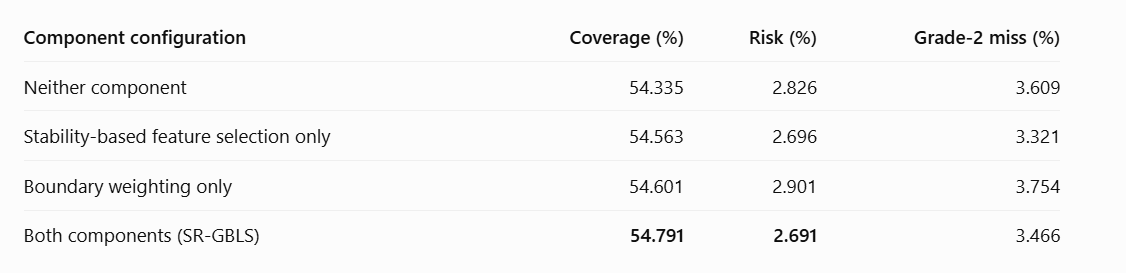

#**Examination-Level Risk Uncertainty and Dataset Provenance**

In [ ]:

from pathlib import Path
import os, re
import numpy as np
import pandas as pd
from scipy.special import expit

ROOT = Path('/content/drive/MyDrive/thesis_DR')
OUT = ROOT / 'major_revision_M1'
SEEDS = (42, 43, 44, 45, 46)
N_BOOT = 10000

required_paths = {
    'predictions': ROOT / 'messidor2_retfound_raw_predictions.csv',
    'results': ROOT / 'messidor2_external_results.csv',
    'manifest': ROOT / 'messidor2_recert_split_manifest.csv',
}

for p in [OUT, *required_paths.values()]:
    if not p.exists():
        raise FileNotFoundError(str(p))

pred = pd.read_csv(
    required_paths['predictions'],
    dtype={'image_id': str}
)
results = pd.read_csv(required_paths['results'])
manifest = pd.read_csv(
    required_paths['manifest'],
    dtype={'image_id': str}
)

if not {
    'seed', 'image_id', 'original_grade',
    'binary_label', 'raw_logit'
}.issubset(pred):
    raise ValueError('Prediction columns mismatch.')

if not {
    'seed', 'temperature', 'frozen_threshold',
    'auto_clear_count', 'referable_auto_clear_errors'
}.issubset(results):
    raise ValueError('Screening-result columns mismatch.')

if not {
    'image_id', 'original_grade', 'binary_label'
}.issubset(manifest):
    raise ValueError('Manifest columns mismatch.')

if (
    len(pred) != 8700
    or len(manifest) != 1740
    or len(results) != 5
    or set(pred.seed) != set(SEEDS)
    or set(results.seed) != set(SEEDS)
    or pred.duplicated(['seed', 'image_id']).any()
    or manifest.image_id.duplicated().any()
    or results.seed.duplicated().any()
):
    raise ValueError('Cohort or seed validation failed.')


def image_key(value):
    if pd.isna(value):
        return ''
    s = (
        str(value).strip()
        .replace('\\', '/')
        .split('/')[-1]
        .strip()
        .casefold()
    )
    return re.sub(
        r'\.(jpeg|jpg|png|tiff|tif|bmp|webp)$',
        '',
        s
    )


for df in (pred, manifest):
    df['_key'] = df.image_id.map(image_key)

    if df._key.eq('').any():
        raise ValueError('Blank image identity.')

if (
    pred.duplicated(['seed', '_key']).any()
    or manifest._key.duplicated().any()
):
    raise ValueError('Ambiguous image identity.')

reference = (
    manifest.sort_values('_key')
    .reset_index(drop=True)
)

keys = reference._key.tolist()
key_set = set(keys)

labels = reference.binary_label.to_numpy(int)
grades = reference.original_grade.to_numpy(int)

if (
    not np.isin(grades, np.arange(5)).all()
    or not np.array_equal(
        labels,
        (grades >= 2).astype(int)
    )
):
    raise ValueError('Five-grade binary labels mismatch.')

predictions_by_seed = {}

for seed in SEEDS:
    subset = (
        pred.loc[pred.seed.eq(seed)]
        .set_index('_key')
        .reindex(keys)
    )

    if (
        len(subset) != 1740
        or subset.image_id.isna().any()
        or not np.array_equal(
            subset.original_grade.to_numpy(int),
            grades
        )
        or not np.array_equal(
            subset.binary_label.to_numpy(int),
            labels
        )
    ):
        raise ValueError(
            f'Image/grade alignment failed: {seed}'
        )

    predictions_by_seed[seed] = subset

saved_by_seed = results.set_index('seed')
cleared_by_seed = {}

for seed in SEEDS:
    r = saved_by_seed.loc[seed]

    T = float(r.temperature)
    threshold = float(r.frozen_threshold)

    if (
        not np.isfinite(T)
        or T <= 0
        or not 0 <= threshold <= 1
    ):
        raise ValueError(
            f'Invalid temperature or threshold: {seed}'
        )

    logit = (
        predictions_by_seed[seed]
        .raw_logit.to_numpy(float)
    )

    if not np.isfinite(logit).all():
        raise ValueError(f'Invalid logits: {seed}')

    cleared = expit(logit / T) <= threshold

    n_cleared = int(cleared.sum())
    n_errors = int(labels[cleared].sum())

    if (
        n_cleared != int(r.auto_clear_count)
        or n_errors != int(
            r.referable_auto_clear_errors
        )
    ):
        raise ValueError(
            f'Frozen-policy counts mismatch: {seed}'
        )

    cleared_by_seed[seed] = cleared


SKIP_NAME = (
    'raw_predictions',
    'external_results',
    'recert_split_manifest',
    'preprocess_sensitivity',
    'risk_certification',
    'ltt_recertification',
    'gbls_',
    'sr_gbls_',
    'reviewer_',
    'ablation',
    'embedding',
    'aptos_',
    'idrid_',
    'importance_weights'
)

allowed_ext = {
    '.csv', '.tsv', '.xlsx',
    '.xls', '.parquet'
}

metadata_paths = []

for folder, dirs, filenames in os.walk(ROOT):
    relative_depth = len(
        Path(folder).relative_to(ROOT).parts
    )

    dirs[:] = sorted(
        d for d in dirs
        if relative_depth < 5
        and d.lower() not in {
            'major_revision_m1',
            '__pycache__',
            '.git',
            'images',
            'image',
            'jpg',
            'jpeg',
            'png',
            'fundus_images',
            'embeddings',
            'checkpoints',
            'train_images',
            'test_images'
        }
    )

    for filename in sorted(filenames):
        p = Path(folder) / filename
        name = filename.casefold()

        if (
            p.suffix.casefold() not in allowed_ext
            or any(x in name for x in SKIP_NAME)
        ):
            continue

        location = str(
            p.relative_to(ROOT)
        ).casefold()

        if not any(
            x in location
            for x in (
                'messidor',
                'pair',
                'exam',
                'annotat',
                'grading',
                'grade',
                'label',
                'patient'
            )
        ):
            continue

        try:
            if p.stat().st_size <= 25 * 1024 * 1024:
                metadata_paths.append(p)
        except OSError:
            pass


def tables_in(path):
    try:
        ext = path.suffix.casefold()

        if ext == '.csv':
            yield '', pd.read_csv(
                path, dtype=str, nrows=5000
            )

        elif ext == '.tsv':
            yield '', pd.read_csv(
                path,
                sep='\t',
                dtype=str,
                nrows=5000
            )

        elif ext in ('.xlsx', '.xls'):
            sheets = pd.read_excel(
                path,
                sheet_name=None,
                dtype=str,
                nrows=5000
            )

            for sheet, frame in sheets.items():
                yield str(sheet), frame

        elif ext == '.parquet':
            yield '', (
                pd.read_parquet(path)
                .head(5000)
                .astype(str)
            )

    except (
        ImportError, ValueError, OSError,
        KeyError, TypeError
    ):
        return


def column_name(col):
    return re.sub(
        r'[^a-z0-9]+',
        '_',
        str(col).casefold()
    ).strip('_')


exam_names = {
    'exam_id',
    'examination_id',
    'examination',
    'exam',
    'exam_number',
    'examination_number',
    'visit_id',
    'study_id',
    'image_pair_id',
    'bilateral_pair_id',
    'retinal_examination_id'
}

grade_names = {
    'original_grade',
    'grade',
    'dr_grade',
    'retinopathy_grade',
    'diabetic_retinopathy_grade',
    'adjudicated_dr_grade',
    'severity_grade',
    'diagnosis',
    'diagnosis_grade',
    'dr_level'
}

image_names = {
    'image_id',
    'image_name',
    'image',
    'image_path',
    'image_filename',
    'image_file',
    'filename',
    'file_name',
    'file',
    'name',
    'fundus_image',
    'image_name_1',
    'original_image_id'
}

mapping_options = []
grade_options = []

for path in metadata_paths:
    for sheet, frame in tables_in(path):
        if frame.empty or len(frame.columns) > 80:
            continue

        norm = {
            c: column_name(c)
            for c in frame.columns
        }

        matches = {}

        for col in frame.columns:
            strings = frame[col].map(image_key)

            n_match = int(
                strings.isin(key_set).sum()
            )

            if n_match >= 100:
                matches[col] = strings

        if not matches:
            continue

        image_candidates = sorted(
            matches,
            key=lambda c: (
                norm[c] not in image_names,
                -int(
                    matches[c].isin(key_set).sum()
                )
            )
        )

        source = str(path.relative_to(ROOT))

        if sheet:
            source += f' [{sheet}]'

        for image_col in image_candidates[:6]:
            ids = matches[image_col]
            valid = ids.isin(key_set)

            if (
                int(valid.sum()) != 1740
                or ids[valid].duplicated().any()
            ):
                continue

            for exam_col in frame.columns:
                if norm[exam_col] not in exam_names:
                    continue

                grp = (
                    frame.loc[valid, exam_col]
                    .astype('string')
                    .str.strip()
                )

                if (
                    grp.isna().any()
                    or grp.eq('').any()
                ):
                    continue

                mapping_options.append((
                    3,
                    source,
                    dict(zip(ids[valid], grp))
                ))

            for gc in frame.columns:
                if norm[gc] not in grade_names:
                    continue

                numeric = pd.to_numeric(
                    frame.loc[valid, gc],
                    errors='coerce'
                )

                if (
                    numeric.isna().any()
                    or not np.isin(
                        numeric.to_numpy(),
                        np.arange(5)
                    ).all()
                ):
                    continue

                d = dict(
                    zip(
                        ids[valid],
                        numeric.astype(int)
                    )
                )

                mismatches = sum(
                    d[k] != int(g)
                    for k, g in zip(keys, grades)
                )

                grade_options.append((
                    mismatches,
                    source,
                    d
                ))

        if len(image_candidates) >= 2:
            from itertools import combinations

            for a, b in combinations(
                image_candidates[:8], 2
            ):
                pair_map = {}
                invalid = False

                for idx, (ka, kb) in enumerate(
                    zip(matches[a], matches[b])
                ):
                    matched = {
                        k for k in (ka, kb)
                        if k in key_set
                    }

                    for k in matched:
                        if k in pair_map:
                            invalid = True
                            break

                        pair_map[k] = (
                            f'{source} :: pair-row-{idx}'
                        )

                    if invalid:
                        break

                if (
                    not invalid
                    and len(pair_map) == 1740
                ):
                    mapping_options.append((
                        2,
                        source,
                        pair_map
                    ))


valid_mappings = []

for priority, source, mapping in mapping_options:
    if set(mapping) != key_set:
        continue

    counts = pd.Series(
        [mapping[k] for k in keys]
    ).value_counts()

    if (
        870 <= len(counts) <= 874
        and counts.between(1, 2).all()
        and int((counts == 2).sum()) >= 866
    ):
        signature = frozenset(
            frozenset(
                k for k in keys
                if mapping[k] == group
            )
            for group in counts.index
        )

        valid_mappings.append((
            priority,
            source,
            mapping,
            signature
        ))

mapping = None
mapping_source = ''

if valid_mappings:
    valid_mappings.sort(
        key=lambda t: (-t[0], t[1])
    )

    if all(
        x[3] == valid_mappings[0][3]
        for x in valid_mappings
    ):
        mapping_source = valid_mappings[0][1]
        mapping = valid_mappings[0][2]

    else:
        print(
            'EXAMINATION MATCH: conflicting mappings.'
        )

label_source = ''
external_grade = None

if grade_options:
    grade_options.sort(
        key=lambda x: (x[0], x[1])
    )

    if grade_options[0][0] == 0:
        label_source = grade_options[0][1]
        external_grade = grade_options[0][2]

provenance = reference[
    ['image_id', 'original_grade', 'binary_label']
].copy()

provenance['manifest_grade_verified'] = True

provenance['examination_id'] = (
    [mapping[k] for k in keys]
    if mapping else pd.NA
)

provenance['examination_mapping_file'] = (
    mapping_source if mapping else pd.NA
)

provenance['separate_annotation_grade'] = (
    [external_grade[k] for k in keys]
    if external_grade else pd.NA
)

provenance['annotation_table_file'] = (
    label_source if label_source else pd.NA
)

cluster_results = None

if mapping:
    groups, group_codes = np.unique(
        np.asarray(
            [mapping[k] for k in keys],
            dtype=str
        ),
        return_inverse=True
    )

    n_groups = len(groups)

    clear_matrix = np.vstack([
        cleared_by_seed[s]
        for s in SEEDS
    ])

    misses_matrix = (
        clear_matrix
        & (labels[None, :] == 1)
    )

    group_cleared = np.vstack([
        np.bincount(
            group_codes,
            weights=a,
            minlength=n_groups
        )
        for a in clear_matrix
    ])

    group_misses = np.vstack([
        np.bincount(
            group_codes,
            weights=e,
            minlength=n_groups
        )
        for e in misses_matrix
    ])

    rng = np.random.default_rng(20261114)

    draws = np.empty(
        (N_BOOT, len(SEEDS)),
        dtype=float
    )

    for start in range(0, N_BOOT, 250):
        size = min(
            250,
            N_BOOT - start
        )

        take = rng.integers(
            0,
            n_groups,
            size=(size, n_groups)
        )

        num = (
            group_misses[:, take]
            .sum(axis=2)
            .T
        )

        den = (
            group_cleared[:, take]
            .sum(axis=2)
            .T
        )

        if (den == 0).any():
            raise RuntimeError(
                'Bootstrap sample has zero cleared images.'
            )

        draws[start:start + size] = (
            100 * num / den
        )

    rows = []

    n_pairs = int(
        (np.bincount(group_codes) == 2).sum()
    )

    for j, seed in enumerate(SEEDS):
        accept = cleared_by_seed[seed]

        q = np.quantile(
            draws[:, j],
            [.025, .05, .95, .975]
        )

        rows.append({
            'seed': seed,
            'examinations': n_groups,
            'two_eye_examinations': n_pairs,
            'single_eye_examinations': (
                n_groups - n_pairs
            ),
            'evaluated_images': len(keys),
            'auto_clear_count': int(accept.sum()),
            'referable_auto_clear_errors': int(
                labels[accept].sum()
            ),
            'observed_risk_pct': (
                100 * float(labels[accept].mean())
            ),
            'clustered_two_sided_95_lower_pct': (
                float(q[0])
            ),
            'clustered_one_sided_95_lower_pct': (
                float(q[1])
            ),
            'clustered_one_sided_95_upper_pct': (
                float(q[2])
            ),
            'clustered_two_sided_95_upper_pct': (
                float(q[3])
            ),
            'one_sided_95_lower_exceeds_5pct': (
                bool(q[1] > 5)
            ),
            'bootstrap_repetitions': N_BOOT,
            'examination_mapping_file': (
                mapping_source
            )
        })

    cluster_results = pd.DataFrame(rows)

audit_path = (
    OUT / 'reviewer_messidor_examination_provenance.csv'
)

tmp_audit = (
    OUT / 'reviewer_messidor_examination_provenance.pending.csv'
)

provenance.to_csv(
    tmp_audit,
    index=False
)

tmp_audit.replace(audit_path)

print(
    'PASS: 5/5 frozen policies, '
    '1,740 image IDs and grades verified.'
)

if mapping:
    ci_path = (
        OUT / 'reviewer_messidor_examination_clustered_ci.csv'
    )

    tmp_ci = (
        OUT / 'reviewer_messidor_examination_clustered_ci.pending.csv'
    )

    cluster_results.to_csv(
        tmp_ci,
        index=False
    )

    tmp_ci.replace(ci_path)

    print(
        f'PASS: {cluster_results.examinations.iloc[0]} '
        'examination groups verified.'
    )

    print(
        cluster_results.drop(
            columns='examination_mapping_file'
        ).round(4).to_string(index=False)
    )

    print('Saved:', ci_path)

else:
    print(
        'Examination-clustered CI: not calculated '
        '(verified mapping unavailable).'
    )

print(
    'Annotation-grade agreement:',
    '1740/1740'
    if external_grade
    else 'independent table not verified'
)

print('Saved:', audit_path)


PASS: 5/5 frozen policies, 1,740 image IDs and grades verified.
Examination-clustered CI: not calculated (verified mapping unavailable).
Annotation-grade agreement: independent table not verified
Saved: /content/drive/MyDrive/thesis_DR/major_revision_M1/reviewer_messidor_examination_provenance.csv


#**Messidor-2 Examination Pairing and Annotation Provenance Recovery**

In [ ]:
from pathlib import Path
import zipfile

folder = Path("/content/MESSIDOR2/MESSIDOR2")
archive = Path("/content/MESSIDOR2.zip")

print("EXTRACTED DATASET:")
for p in sorted(folder.iterdir())[:20]:
    print("DIR" if p.is_dir() else "FILE", p.name)

with zipfile.ZipFile(archive) as z:
    names = z.namelist()

    metadata = [
        n for n in names
        if n.lower().endswith(
            (".csv", ".xlsx", ".xls", ".tsv", ".json")
        )
    ]

    images = [
        n for n in names
        if n.lower().endswith(
            (".jpg", ".jpeg", ".png", ".tif", ".tiff")
        )
    ]

    print("\nImages in archive:", len(images))
    print("\nMetadata files:", metadata[:30])
    print("\nSample image filenames:", images[:10])

EXTRACTED DATASET:
FILE readme.txt
DIR test
DIR train
DIR val

Images in archive: 1744

Metadata files: []

Sample image filenames: ['MESSIDOR2/val/eproliferativedr/20051214_40912_0100_PP.png', 'MESSIDOR2/val/eproliferativedr/IM004346.png', 'MESSIDOR2/val/eproliferativedr/IM001941.png', 'MESSIDOR2/val/eproliferativedr/20051208_42314_0400_PP.png', 'MESSIDOR2/val/eproliferativedr/20051021_52127_0100_PP.png', 'MESSIDOR2/val/dseveredr/20060530_55724_0100_PP.png', 'MESSIDOR2/val/dseveredr/IM003481.png', 'MESSIDOR2/val/dseveredr/20051216_45226_0200_PP.png', 'MESSIDOR2/val/dseveredr/20051020_45068_0100_PP.png', 'MESSIDOR2/val/dseveredr/20060412_62936_0200_PP.png']


In [ ]:
from pathlib import Path

readme = Path("/content/MESSIDOR2/MESSIDOR2/readme.txt")

if not readme.is_file():
    raise FileNotFoundError(readme)

print(readme.read_text(encoding="utf-8", errors="replace"))

This folder includes the preprocessed images from Messidor-2 (https://www.adcis.net/en/third-party/messidor2/)

Please refer to the Messidor-2 website for more information about the dataset.



External Screening Risk and Statistical Uncertainty.

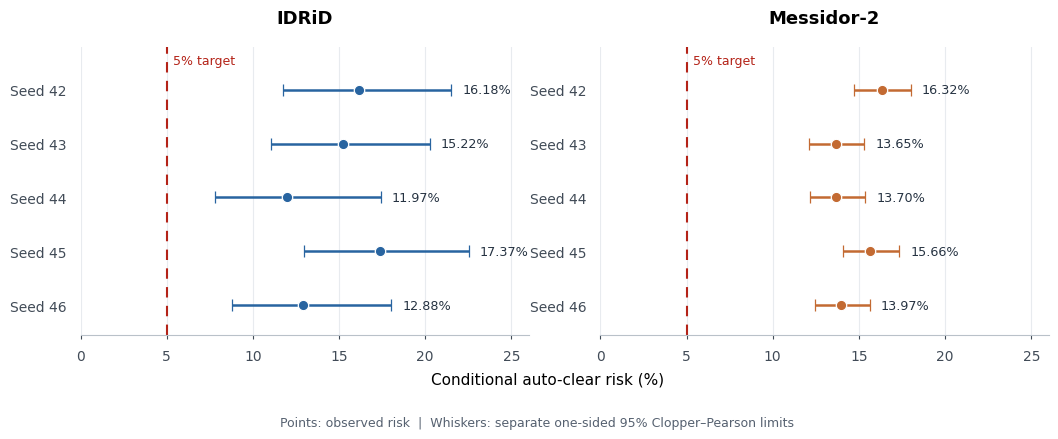

PASS: 10 external risk evaluations plotted.
Saved: /content/drive/MyDrive/thesis_DR/major_revision_M1/M1_external_risk_uncertainty_figure.png
Saved: /content/drive/MyDrive/thesis_DR/major_revision_M1/M1_external_risk_uncertainty_figure.svg


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

ROOT = Path("/content/drive/MyDrive/thesis_DR")
OUT = ROOT / "major_revision_M1"

INPUT = OUT / "reviewer_external_risk_exceedance.csv"
PNG = OUT / "M1_external_risk_uncertainty_figure.png"
SVG = OUT / "M1_external_risk_uncertainty_figure.svg"

if not INPUT.is_file():
    raise FileNotFoundError(INPUT)

df = pd.read_csv(INPUT)

required = {
    "dataset",
    "seed",
    "observed_risk_pct",
    "lower_95_one_sided_pct",
    "upper_95_one_sided_pct",
}

if not required.issubset(df.columns):
    raise ValueError(
        f"Missing columns: {required - set(df.columns)}"
    )

datasets = ("IDRiD", "Messidor-2")
seeds = (42, 43, 44, 45, 46)

if (
    len(df) != 10
    or df.duplicated(["dataset", "seed"]).any()
    or set(df["dataset"]) != set(datasets)
):
    raise ValueError("External evaluation records mismatch.")

for dataset in datasets:
    if set(df.loc[df.dataset.eq(dataset), "seed"]) != set(seeds):
        raise ValueError(f"Incomplete seed records: {dataset}")

numeric = [
    "observed_risk_pct",
    "lower_95_one_sided_pct",
    "upper_95_one_sided_pct",
]

for col in numeric:
    df[col] = pd.to_numeric(df[col], errors="raise")

if not np.isfinite(df[numeric].to_numpy(float)).all():
    raise ValueError("Nonfinite risk values.")

if not (
    (df.lower_95_one_sided_pct <= df.observed_risk_pct).all()
    and (df.observed_risk_pct <= df.upper_95_one_sided_pct).all()
    and df.lower_95_one_sided_pct.ge(0).all()
    and df.upper_95_one_sided_pct.le(100).all()
):
    raise ValueError("Invalid confidence limits.")

colors = {
    "IDRiD": "#2864A0",
    "Messidor-2": "#C36A32",
}

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 13,
    "axes.edgecolor": "#B9C1C9",
    "axes.linewidth": 0.8,
    "xtick.color": "#414B57",
    "ytick.color": "#414B57",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
}):

    fig, axes = plt.subplots(
        1, 2,
        figsize=(11, 4.5),
        sharex=True,
        sharey=True,
        gridspec_kw={"wspace": 0.16},
    )

    x_max = max(
        26.0,
        float(df.upper_95_one_sided_pct.max()) + 3.2
    )

    for ax, dataset in zip(axes, datasets):

        part = (
            df.loc[df.dataset.eq(dataset)]
            .set_index("seed")
            .loc[list(seeds)]
            .reset_index()
        )

        risk = part.observed_risk_pct.to_numpy(float)
        lower = part.lower_95_one_sided_pct.to_numpy(float)
        upper = part.upper_95_one_sided_pct.to_numpy(float)

        y = np.arange(len(seeds))
        color = colors[dataset]

        ax.axvline(
            5.0,
            color="#B42318",
            linewidth=1.5,
            linestyle=(0, (5, 4)),
            zorder=1,
        )

        ax.errorbar(
            risk,
            y,
            xerr=np.vstack([
                risk - lower,
                upper - risk,
            ]),
            fmt="o",
            color=color,
            ecolor=color,
            markersize=7.5,
            markeredgecolor="white",
            markeredgewidth=0.9,
            elinewidth=1.8,
            capsize=4,
            capthick=1.5,
            zorder=3,
        )

        for i in range(len(seeds)):
            ax.text(
                upper[i] + 0.65,
                y[i],
                f"{risk[i]:.2f}%",
                fontsize=9.2,
                fontweight="medium",
                color="#253241",
                va="center",
                ha="left",
            )

        ax.set_title(
            dataset,
            fontweight="bold",
            pad=17,
        )

        ax.set_yticks(y)
        ax.set_yticklabels([
            f"Seed {s}" for s in seeds
        ])

        ax.set_ylim(4.55, -0.8)
        ax.set_xlim(0, x_max)

        ax.xaxis.set_major_locator(
            MultipleLocator(5)
        )

        ax.grid(
            axis="x",
            linestyle="-",
            color="#E8EBEF",
            linewidth=0.8,
            zorder=0,
        )

        ax.set_axisbelow(True)

        for spine in ("top", "right", "left"):
            ax.spines[spine].set_visible(False)

        ax.tick_params(
            axis="y",
            length=0,
            pad=10,
        )

        ax.tick_params(
            axis="x",
            length=3,
            pad=7,
        )

        ax.text(
            5.35,
            -0.55,
            "5% target",
            color="#B42318",
            fontsize=9,
            fontweight="medium",
            ha="left",
            va="center",
        )

    axes[0].tick_params(
        axis="y",
        labelleft=True
    )

    axes[1].tick_params(
        axis="y",
        labelleft=True
    )

    fig.supxlabel(
        "Conditional auto-clear risk (%)",
        x=0.53,
        y=0.115,
        fontsize=11,
    )

    fig.text(
        0.52,
        0.035,
        "Points: observed risk  |  Whiskers: separate one-sided 95% Clopper–Pearson limits",
        ha="center",
        va="center",
        fontsize=9,
        color="#566170",
    )

    fig.subplots_adjust(
        left=0.105,
        right=0.985,
        top=0.87,
        bottom=0.23,
    )

    fig.savefig(
        PNG,
        dpi=450,
        bbox_inches="tight",
        pad_inches=0.18,
    )

    fig.savefig(
        SVG,
        bbox_inches="tight",
        pad_inches=0.18,
    )

    plt.show()
    plt.close(fig)

print("PASS: 10 external risk evaluations plotted.")
print("Saved:", PNG)
print("Saved:", SVG)


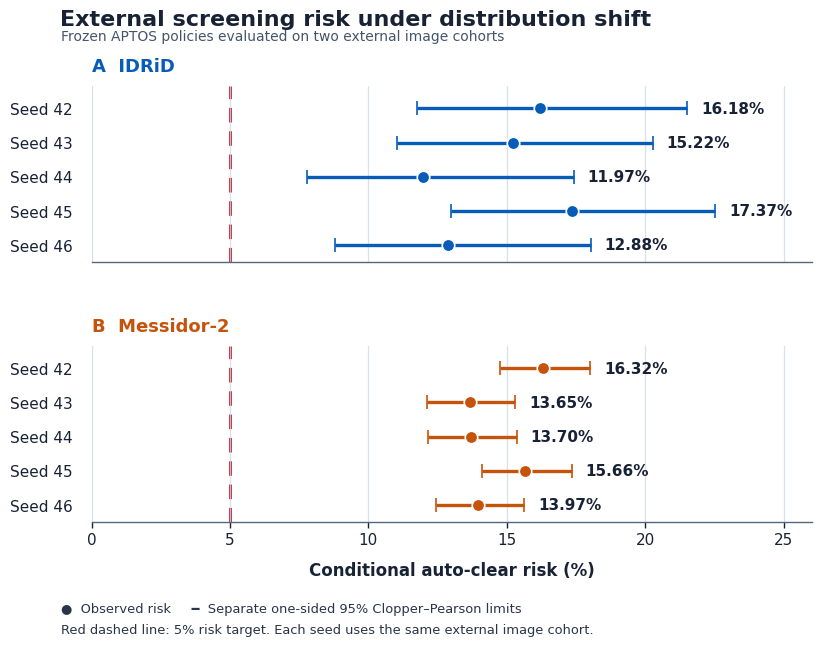

PASS: 10/10 external evaluations plotted.
Updated: /content/drive/MyDrive/thesis_DR/major_revision_M1/M1_external_risk_uncertainty_figure.png
Updated: /content/drive/MyDrive/thesis_DR/major_revision_M1/M1_external_risk_uncertainty_figure.svg


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("/content/drive/MyDrive/thesis_DR")
OUT = ROOT / "major_revision_M1"

SOURCE = OUT / "reviewer_external_risk_exceedance.csv"
PNG = OUT / "M1_external_risk_uncertainty_figure.png"
SVG = OUT / "M1_external_risk_uncertainty_figure.svg"

if not SOURCE.is_file():
    raise FileNotFoundError(SOURCE)

df = pd.read_csv(SOURCE)

required = {
    "dataset",
    "seed",
    "observed_risk_pct",
    "lower_95_one_sided_pct",
    "upper_95_one_sided_pct",
}

if not required.issubset(df.columns):
    raise ValueError(
        f"Missing columns: {required - set(df.columns)}"
    )

datasets = ("IDRiD", "Messidor-2")
seeds = (42, 43, 44, 45, 46)

if (
    len(df) != 10
    or df.duplicated(["dataset", "seed"]).any()
    or set(df.dataset) != set(datasets)
):
    raise ValueError("External evaluation records mismatch.")

for dataset in datasets:
    observed_seeds = set(
        df.loc[df.dataset.eq(dataset), "seed"]
    )
    if observed_seeds != set(seeds):
        raise ValueError(
            f"Incomplete seed records: {dataset}"
        )

cols = [
    "observed_risk_pct",
    "lower_95_one_sided_pct",
    "upper_95_one_sided_pct",
]

for col in cols:
    df[col] = pd.to_numeric(df[col], errors="raise")

values = df[cols].to_numpy(float)

if not np.isfinite(values).all():
    raise ValueError("Nonfinite risk or confidence bounds.")

if not (
    (df.lower_95_one_sided_pct >= 0).all()
    and (
        df.lower_95_one_sided_pct
        <= df.observed_risk_pct
    ).all()
    and (
        df.observed_risk_pct
        <= df.upper_95_one_sided_pct
    ).all()
    and (df.upper_95_one_sided_pct <= 100).all()
):
    raise ValueError("Invalid risk confidence limits.")

colors = {
    "IDRiD": "#075CBA",
    "Messidor-2": "#C6530C",
}

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "text.color": "#182235",
    "axes.labelcolor": "#182235",
    "xtick.color": "#182235",
    "ytick.color": "#182235",
    "axes.edgecolor": "#57677A",
    "axes.linewidth": 1.0,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
}):

    fig, axes = plt.subplots(
        2, 1,
        figsize=(9.0, 6.7),
        sharex=True,
        gridspec_kw={"hspace": 0.48},
    )

    fig.suptitle(
        "External screening risk under distribution shift",
        fontsize=16,
        fontweight="bold",
        x=0.115,
        ha="left",
        y=0.985,
    )

    fig.text(
        0.116, 0.938,
        "Frozen APTOS policies evaluated on two external image cohorts",
        fontsize=10,
        color="#44546A",
        ha="left",
    )

    x_max = max(
        26.0,
        float(df.upper_95_one_sided_pct.max()) + 3.0,
    )

    for index, (ax, dataset) in enumerate(
        zip(axes, datasets)
    ):

        part = (
            df.loc[df.dataset.eq(dataset)]
            .set_index("seed")
            .loc[list(seeds)]
        )

        risk = part.observed_risk_pct.to_numpy(float)
        lower = part.lower_95_one_sided_pct.to_numpy(float)
        upper = part.upper_95_one_sided_pct.to_numpy(float)

        y = np.arange(len(seeds))
        color = colors[dataset]

        ax.set_xlim(0, x_max)
        ax.set_ylim(4.5, -0.65)

        ax.set_yticks(
            y,
            [f"Seed {seed}" for seed in seeds],
        )

        ax.set_xticks(np.arange(0, 26, 5))

        ax.grid(
            axis="x",
            color="#D2DAE5",
            linewidth=0.95,
            alpha=0.8,
            zorder=0,
        )

        ax.axvline(
            5.0,
            linewidth=2.1,
            linestyle=(0, (5, 3)),
            color="#C21F30",
            zorder=1,
        )

        ax.errorbar(
            risk,
            y,
            xerr=np.vstack([
                risk - lower,
                upper - risk,
            ]),
            fmt="o",
            color=color,
            ecolor=color,
            markersize=9,
            markeredgewidth=1.2,
            markeredgecolor="white",
            elinewidth=2.4,
            capsize=5,
            capthick=2.0,
            zorder=3,
        )

        for yy, risk_value, upper_value in zip(
            y, risk, upper
        ):
            ax.text(
                upper_value + 0.5,
                yy,
                f"{risk_value:.2f}%",
                ha="left",
                va="center",
                fontsize=11,
                fontweight="bold",
                color="#182235",
            )

        label = (
            "A  IDRiD"
            if index == 0
            else "B  Messidor-2"
        )

        ax.set_title(
            label,
            loc="left",
            fontsize=13,
            fontweight="bold",
            color=color,
            pad=11,
        )

        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)

        ax.tick_params(
            axis="y",
            left=False,
            pad=10,
        )

        ax.tick_params(
            axis="x",
            bottom=(index == 1),
            labelbottom=(index == 1),
            length=4,
            width=1,
        )

    axes[-1].set_xlabel(
        "Conditional auto-clear risk (%)",
        fontsize=12,
        fontweight="bold",
        labelpad=10,
    )

    fig.text(
        0.116,
        0.085,
        "●  Observed risk     ━  Separate one-sided 95% Clopper–Pearson limits",
        fontsize=9.4,
        color="#293548",
    )

    fig.text(
        0.116,
        0.054,
        "Red dashed line: 5% risk target. "
        "Each seed uses the same external image cohort.",
        fontsize=9.4,
        color="#293548",
    )

    fig.subplots_adjust(
        left=0.15,
        right=0.95,
        top=0.87,
        bottom=0.22,
    )

    fig.savefig(
        PNG,
        dpi=450,
        bbox_inches="tight",
        pad_inches=0.2,
    )

    fig.savefig(
        SVG,
        bbox_inches="tight",
        pad_inches=0.2,
    )

    plt.show()
    plt.close(fig)

print("PASS: 10/10 external evaluations plotted.")
print("Updated:", PNG)
print("Updated:", SVG)


#Review

In [4]:
# DR REVIEWER REVISION — ALL FIVE ANALYSES IN ONE GOOGLE COLAB CELL
# Source procedures: Thesis_DR_APTOS_RETOUND.ipynb + Thesis_External_Validation.ipynb
# No training, no dataset download, no changes to existing prediction/model files.
# Requires prior Colab setup: Drive mounted, Messidor-2 images extracted, timm installed.
import json
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.special import expit
from scipy.stats import binom
from sklearn.metrics import roc_auc_score

ROOT = Path('/content/drive/MyDrive/thesis_DR')  # exact project folder in original notebooks
M2_ROOT = Path('/content/MESSIDOR2/MESSIDOR2')   # exact image root in original external notebook
SEEDS = (42, 43, 44, 45, 46)
ALPHAS = (0.01, 0.02, 0.05)
DELTA = 0.05
Q = np.linspace(0.02, 0.98, 50)

INPUTS = {
    'APTOS': 'aptos_retfound_raw_predictions.csv',
    'IDRiD': 'idrid_retfound_raw_predictions.csv',
    'Messidor-2': 'messidor2_retfound_raw_predictions.csv',
    'temperature': 'aptos_retfound_temperature_scaling.json',
    'ltt': 'aptos_retfound_ltt_risk_control.csv',
    'internal': 'aptos_retfound_internal_test_results.csv',
    'idrid_result': 'idrid_external_results.csv',
    'messidor_result': 'messidor2_external_results.csv',
    'head': 'aptos_retfound_mlp_heads.pt',
    'encoder': 'retfoundgreen_statedict.pth',
}
if not ROOT.is_dir():
    raise FileNotFoundError(f'Google Drive is not mounted or original project folder is absent: {ROOT}')
missing = [name for name in INPUTS.values() if not (ROOT/name).is_file()]
if missing:
    raise FileNotFoundError('Missing saved original study files:\n' + '\n'.join(missing))

raw = {}
for cohort in ('APTOS', 'IDRiD', 'Messidor-2'):
    f = INPUTS[cohort]
    d = pd.read_csv(ROOT/f, dtype={'image_id':str})
    required = {'seed','image_id','original_grade','binary_label','raw_logit'}
    if cohort == 'APTOS': required.add('split')
    if not required.issubset(d.columns):
        raise ValueError(f'{f}: missing columns {sorted(required-set(d.columns))}')
    if cohort == 'APTOS': d = d.loc[d.split == 'internal_test'].copy()
    d['seed'] = d['seed'].astype(int)
    if set(d.seed) != set(SEEDS) or d.duplicated(['seed','image_id']).any():
        raise ValueError(f'{f}: unexpected/missing seeds or duplicate image IDs')
    for s in SEEDS:
        ds = d.loc[d.seed==s]
        exp_n = {'APTOS':526,'IDRiD':507,'Messidor-2':1740}[cohort]
        if len(ds)!=exp_n: raise ValueError(f'{cohort}, seed {s}: expected {exp_n}, got {len(ds)}')
    y = d.binary_label.to_numpy(int)
    grade = d.original_grade.to_numpy(int)
    if not np.isin(grade,[0,1,2,3,4]).all() or not np.array_equal(y,(grade>=2).astype(int)):
        raise ValueError(f'{cohort}: invalid grade/label pairing')
    if not np.isfinite(d.raw_logit.to_numpy(float)).all():
        raise ValueError(f'{cohort}: nonfinite raw logits')
    if cohort != 'APTOS':
        reference = d.loc[d.seed==SEEDS[0], ['image_id','original_grade','binary_label']].sort_values('image_id').reset_index(drop=True)
        for s in SEEDS[1:]:
            comparison = d.loc[d.seed==s, ['image_id','original_grade','binary_label']].sort_values('image_id').reset_index(drop=True)
            if not reference.equals(comparison): raise ValueError(f'{cohort}: cohort or labels differ across seeds')
    raw[cohort] = d

# Full APTOS prediction CSV, including development and risk-calibration splits.
aptos_all = pd.read_csv(ROOT/INPUTS['APTOS'], dtype={'image_id':str})
if set(aptos_all.split.unique()) != {'development','prob_calibration','risk_calibration','internal_test'}:
    raise ValueError('APTOS split labels differ from original notebook')
for s in SEEDS:
    counts = aptos_all.loc[aptos_all.seed==s,'split'].value_counts().to_dict()
    if counts != {'development':2102,'risk_calibration':526,'internal_test':526,'prob_calibration':350}:
        raise ValueError(f'APTOS source split sizes invalid for seed {s}: {counts}')

with open(ROOT/INPUTS['temperature'], 'r') as f:
    temp_json=json.load(f)
T={s:float(temp_json['seeds'][str(s)]['temperature']) for s in SEEDS}
if any((not np.isfinite(t) or t<=0) for t in T.values()): raise ValueError('Invalid source temperature')
LTT=pd.read_csv(ROOT/INPUTS['ltt'])
if LTT.duplicated(['seed','alpha']).any(): raise ValueError('Duplicated LTT summary rows')
policy={}
for s in SEEDS:
    row=LTT.loc[(LTT.seed==s)&np.isclose(LTT.alpha,0.05,atol=1e-12)]
    if len(row)!=1 or not np.isfinite(float(row.iloc[0]['selected_threshold'])):
        raise ValueError(f'Original 5% LTT threshold absent for seed {s}')
    policy[s]=float(row.iloc[0]['selected_threshold'])

saved_results={
    'APTOS':pd.read_csv(ROOT/INPUTS['internal']).set_index('seed'),
    'IDRiD':pd.read_csv(ROOT/INPUTS['idrid_result']).set_index('seed'),
    'Messidor-2':pd.read_csv(ROOT/INPUTS['messidor_result']).set_index('seed'),
}
def cols_saved(cohort):
    if cohort=='IDRiD': return 'auto_clear','auto_clear_errors','ltt_threshold'
    return 'auto_clear_count','referable_auto_clear_errors','frozen_threshold'

def ece10(p,y):
    bins=np.minimum((10*p).astype(int),9)
    n=np.bincount(bins,minlength=10)
    ps=np.bincount(bins,weights=p,minlength=10)
    ys=np.bincount(bins,weights=y,minlength=10)
    mask=n>0
    return float(np.sum(np.abs(ps[mask]/n[mask]-ys[mask]/n[mask])*n[mask])/len(y))

def metrics(z,y,t):
    p=expit(z/t)
    return {'nll':float(np.mean(np.logaddexp(0,z/t)-y*z/t)),
            'brier':float(np.mean((p-y)**2)),
            'ece':ece10(p,y)}

# 1) EXTERNAL CALIBRATION + 2) GRADE-WISE CLEARANCE
cal_rows=[]; grade_rows=[]; screening_rows=[]
for cohort,d in raw.items():
    for s in SEEDS:
        v=d.loc[d.seed==s].sort_values('image_id')
        z=v.raw_logit.to_numpy(float)
        y=v.binary_label.to_numpy(int)
        g=v.original_grade.to_numpy(int)
        p=expit(z/T[s]); clear=p<=policy[s]
        old=saved_results[cohort].loc[s]
        count_col,error_col,threshold_col=cols_saved(cohort)
        if int(clear.sum())!=int(old[count_col]) or int(y[clear].sum())!=int(old[error_col]):
            raise ValueError(f'{cohort} seed {s}: saved original screening counts NOT reproduced')
        archived_threshold = float(old[threshold_col])
        if cohort == 'IDRiD':
            matches_archive = (
                np.isclose(policy[s], archived_threshold, atol=1e-10, rtol=0)
                or np.isclose(round(policy[s], 6), archived_threshold,
                              atol=5e-12, rtol=0)
            )
        else:
            matches_archive = np.isclose(policy[s], archived_threshold,
                                         atol=1e-10, rtol=0)
        if not matches_archive:
            raise ValueError(
                f'{cohort} seed {s}: source threshold CONFLICT. '
                f'LTT saved={policy[s]:.17g}; external archive={archived_threshold:.17g}; '
                f'LTT rounded to 6 decimals={round(policy[s], 6):.6f}. '
                'This is not explained by the six-decimal IDRiD archive rounding; '
                'inspect which saved LTT policy generated the external results.'
            )
        a=metrics(z,y,1.0); b=metrics(z,y,T[s])
        cal_rows.append({'cohort':cohort,'seed':s,'n':len(y),
                         **{'raw_'+k:v for k,v in a.items()},
                         **{'cal_'+k:v for k,v in b.items()}})
        screening_rows.append({'cohort':cohort,'seed':s,'cleared':int(clear.sum()),
                               'false_clear':int(y[clear].sum()),
                               'coverage_pct':100*np.mean(clear),
                               'risk_pct':100*np.mean(y[clear]) if clear.any() else np.nan})
        for grade in (0,1,2,3,4):
            mask=g==grade; n=int(mask.sum()); m=int((mask&clear).sum())
            grade_rows.append({'cohort':cohort,'seed':s,'grade':grade,'images':n,
                               'cleared':m,'clearance_pct':100*m/n if n else np.nan})
cal_df=pd.DataFrame(cal_rows)
grade_df=pd.DataFrame(grade_rows)
screen_df=pd.DataFrame(screening_rows)
cal_summary=cal_df.groupby('cohort',sort=False)[['raw_nll','cal_nll','raw_brier','cal_brier','raw_ece','cal_ece']].agg(['mean','std'])
cal_summary.columns=[f'{name}_{stat}' for name,stat in cal_summary.columns]
cal_summary=cal_summary.reset_index()
grade_summary=(grade_df.query('cohort != "APTOS" and grade >= 2')
               .groupby(['cohort','grade'],sort=False)
               .agg(n_images=('images','first'),mean_cleared=('cleared','mean'),
                    mean_clearance_pct=('clearance_pct','mean'),
                    sd_clearance_pct=('clearance_pct','std')).reset_index())
print('\n=== TASK 1: CALIBRATION — SOURCE AND TWO EXTERNAL COHORTS ===')
print(cal_summary.round(5).to_string(index=False))
print('\n=== TASK 2: GRADES 2–4 — IDRiD AND MESSIDOR-2 ===')
print(grade_summary.round(4).to_string(index=False))

# 3) COMPLETE FIXED-SEQUENCE LTT AUDIT + 5) RAW-vs-CALIBRATED LTT
def binary_kl(q,alpha):
    if q<=0: return float(-np.log1p(-alpha))
    if q>=1: return float(-np.log(alpha))
    return float(q*np.log(q/alpha)+(1-q)*np.log((1-q)/(1-alpha)))

def hb(loss,n,alpha):
    if loss>=alpha: return 1.0
    return float(min(1.0, np.e*binom.cdf(int(np.ceil(n*loss)),n,alpha),
                     np.exp(-n*binary_kl(min(loss,alpha),alpha))))

def threshold_stats(p,y,threshold,alpha):
    cleared=p<=threshold
    n=len(y); m=int(cleared.sum()); errors=int(y[cleared].sum())
    loss=float(np.mean(cleared*y+alpha*(~cleared)))
    return {'cleared':m,'errors':errors,'coverage':m/n,
            'conditional_risk':errors/m if m else np.nan,'loss':loss}

def run_ltt(dev_z,dev_y,risk_z,risk_y,t,seed,alpha,scale):
    dev=expit(dev_z/t); risk=expit(risk_z/t)
    thresholds=np.unique(np.quantile(dev,Q))
    order=[]
    for threshold in thresholds:
        st=threshold_stats(dev,dev_y,float(threshold),alpha)
        order.append({'threshold':float(threshold),'development_ltt_loss':st['loss'],
                      'development_coverage':st['coverage']})
    order=(pd.DataFrame(order).sort_values(['development_ltt_loss','development_coverage'],
                                          ascending=[True,False]).reset_index(drop=True))
    audited=[]; passed=[]; stopped=False
    for ix,row in order.iterrows():
        th=float(row['threshold'])
        st=threshold_stats(risk,risk_y,th,alpha)
        pval=hb(st['loss'],len(risk_y),alpha)
        reached=not stopped
        passed_test=bool(reached and pval<=DELTA and st['cleared']>0)
        if passed_test: passed.append((st['coverage'],th,pval,ix+1,st))
        elif reached: stopped=True
        audited.append({'scale':scale,'seed':seed,'alpha':alpha,'delta':DELTA,
                        'sequence_position':ix+1,'candidate_threshold':th,
                        'development_loss':row['development_ltt_loss'],
                        'development_coverage':row['development_coverage'],
                        'risk_calibration_n':len(risk_y),'risk_calibration_cleared':st['cleared'],
                        'risk_calibration_errors':st['errors'],'risk_calibration_loss':st['loss'],
                        'risk_calibration_coverage':st['coverage'],'hb_p_value':pval,
                        'reached_before_first_failure':reached,'certified_before_stop':passed_test})
    selected=sorted(passed,key=lambda x:(-x[0],x[1]))[0] if passed else None
    summ={'scale':scale,'seed':seed,'alpha':alpha,'delta':DELTA,
          'candidate_count':len(thresholds),'risk_calibration_n':len(risk_y),
          'certified':selected is not None,'n_certified_before_stop':len(passed),
          'selected_threshold':selected[1] if selected else np.nan,
          'selected_p_value':selected[2] if selected else np.nan,
          'selected_sequence_position':selected[3] if selected else np.nan,
          'selected_coverage':selected[4]['coverage'] if selected else 0.0,
          'selected_errors':selected[4]['errors'] if selected else np.nan}
    return audited,summ

all_candidates=[]; summaries=[]; decisions=[]
for s in SEEDS:
    ds=aptos_all.loc[aptos_all.seed==s]
    a=ds.loc[ds.split=='development'].sort_values('image_id')
    b=ds.loc[ds.split=='risk_calibration'].sort_values('image_id')
    for alpha in ALPHAS:
        for scale,t in [('raw',1.0),('calibrated',T[s])]:
            rows,summary=run_ltt(a.raw_logit.to_numpy(float),a.binary_label.to_numpy(int),
                                 b.raw_logit.to_numpy(float),b.binary_label.to_numpy(int),
                                 t,s,alpha,scale)
            all_candidates.extend(rows); summaries.append(summary)
summary_df=pd.DataFrame(summaries)
audit_df=pd.DataFrame(all_candidates)
# Validate reconstruction against original saved source certifications.
for s in SEEDS:
    for alpha in ALPHAS:
        original=LTT.loc[(LTT.seed==s)&np.isclose(LTT.alpha,alpha,atol=1e-12)]
        new=summary_df.loc[(summary_df.seed==s)&np.isclose(summary_df.alpha,alpha,atol=1e-12)&
                           (summary_df.scale=='calibrated')]
        if len(original)!=1 or len(new)!=1: raise ValueError(f'LTT rows missing for seed={s}, alpha={alpha}')
        o=original.iloc[0]; n=new.iloc[0]
        old_cert=str(o['certified']).strip().lower() in ('true','1','yes')
        if old_cert!=bool(n['certified']):
            raise ValueError(f'LTT certification mismatch seed {s}, alpha {alpha}')
        if old_cert:
            if not np.isclose(float(o['selected_threshold']),float(n['selected_threshold']),atol=1e-10,rtol=1e-8):
                raise ValueError(f'LTT threshold mismatch seed {s}, alpha {alpha}')
            if not np.isclose(float(o['selected_p_value']),float(n['selected_p_value']),atol=1e-10,rtol=1e-8):
                raise ValueError(f'LTT p-value mismatch seed {s}, alpha {alpha}')

# Compare selected decisions under raw and calibrated schemes.
for s in SEEDS:
    for alpha in ALPHAS:
        R=summary_df.loc[(summary_df.seed==s)&(summary_df.alpha==alpha)].set_index('scale')
        th_raw=R.loc['raw','selected_threshold']; th_cal=R.loc['calibrated','selected_threshold']
        for cohort,d in raw.items():
            v=d.loc[d.seed==s].sort_values('image_id')
            z=v.raw_logit.to_numpy(float); y=v.binary_label.to_numpy(int)
            clear_raw=expit(z)<=th_raw if np.isfinite(th_raw) else np.zeros(len(v),bool)
            clear_cal=expit(z/T[s])<=th_cal if np.isfinite(th_cal) else np.zeros(len(v),bool)
            decisions.append({'seed':s,'alpha':alpha,'cohort':cohort,
                              'raw_certified':bool(R.loc['raw','certified']),
                              'cal_certified':bool(R.loc['calibrated','certified']),
                              'raw_cleared':int(clear_raw.sum()),'cal_cleared':int(clear_cal.sum()),
                              'raw_errors':int(y[clear_raw].sum()),'cal_errors':int(y[clear_cal].sum()),
                              'different_decisions':int(np.sum(clear_raw!=clear_cal))})
decisions_df=pd.DataFrame(decisions)
print('\n=== TASK 3: SOURCE LTT CERTIFICATION — ALL SEEDS × TARGETS ===')
print(summary_df.query('scale == "calibrated"').round(9).to_string(index=False))
print(f'Candidate audit: {len(audit_df)} rows (raw and calibrated).')
print('\n=== TASK 5: RAW vs CALIBRATED LTT — FINAL POLICY DECISIONS ===')
print(decisions_df.to_string(index=False))

# 4) CONTROLLED MESSIDOR-2 PREPROCESSING SENSITIVITY
import torch
import torch.nn.functional as F
import timm
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

# Dynamic device targeting and execution config to work seamlessly on CPU or GPU.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
batch_size = 16 if torch.cuda.is_available() else 4
num_workers = 2 if torch.cuda.is_available() else 0
print(f'\nTargeting runtime device: {device.type.upper()} | Batch size: {batch_size}')

if not M2_ROOT.is_dir():
    raise FileNotFoundError(f'Messidor-2 images absent at the ORIGINAL notebook location: {M2_ROOT}')
reference=(raw['Messidor-2'].loc[raw['Messidor-2'].seed==SEEDS[0]]
           .sort_values('image_id').reset_index(drop=True))
image_paths=[M2_ROOT / image_id for image_id in reference.image_id]
missing_images=[str(p) for p in image_paths if not p.is_file()]
if missing_images:
    raise FileNotFoundError(f'{len(missing_images)} of 1740 original Messidor-2 images missing; first: {missing_images[0]}')

image_transform=transforms.Compose([transforms.ToTensor(),
                                    transforms.Normalize(mean=(0.5,)*3,std=(0.5,)*3)])

def prep(img,aptos_style):
    arr=np.asarray(img.convert('RGB'))
    if aptos_style:
        gray=0.299*arr[:,:,0]+0.587*arr[:,:,1]+0.114*arr[:,:,2]
        mask=gray>7
    else:
        mask=np.max(arr,axis=2)>10
    if mask.any():
        ys,xs=np.where(mask)
        img=Image.fromarray(arr[ys.min():ys.max()+1, xs.min():xs.max()+1])
    else:
        img=Image.fromarray(arr)
    w,h=img.size; side=max(w,h)
    canvas=Image.new('RGB',(side,side),(0,0,0))
    canvas.paste(img,((side-w)//2,(side-h)//2))
    return canvas.resize((392,392),Image.Resampling.BILINEAR if aptos_style else Image.Resampling.LANCZOS)

class PairedMessidor(Dataset):
    def __len__(self): return len(image_paths)
    def __getitem__(self,index):
        with Image.open(image_paths[index]) as image:
            image=image.convert('RGB')
            return image_transform(prep(image,False)),image_transform(prep(image,True))

model=timm.create_model('vit_small_patch14_reg4_dinov2',img_size=(392,392),num_classes=0,
                        checkpoint_path=str(ROOT/INPUTS['encoder']))
model.global_pool='avg'
model=model.to(device).eval()
for param in model.parameters(): param.requires_grad_(False)
loader=DataLoader(PairedMessidor(),batch_size=batch_size,shuffle=False,num_workers=num_workers,pin_memory=torch.cuda.is_available())
base_features=[]; aptos_features=[]
with torch.inference_mode():
    for old_images,new_images in loader:
        old_features=model(old_images.to(device,non_blocking=True))
        new_features=model(new_images.to(device,non_blocking=True))
        if old_features.ndim!=2 or old_features.shape[1]!=384 or new_features.shape!=old_features.shape:
            raise ValueError('RETFound-Green embedding shape differs from original 384-dimensional implementation')
        base_features.append(old_features.cpu()); aptos_features.append(new_features.cpu())
old_emb=torch.cat(base_features); new_emb=torch.cat(aptos_features)
heads=torch.load(ROOT/INPUTS['head'],map_location='cpu',weights_only=False)['heads']
preproc_rows=[]; changed_rows=[]
for s in SEEDS:
    state=heads[s if s in heads else str(s)]['state_dict']
    def layer(shape):
        matches=[v.float() for v in state.values() if tuple(v.shape)==shape]
        if len(matches)!=1: raise ValueError(f'Seed {s}: expected one head tensor of shape {shape}')
        return matches[0]
    w1,b1,w2,b2=layer((512,384)),layer((512,)),layer((1,512)),layer((1,))
    def apply_head(x):
        return F.linear(F.relu(F.linear(x,w1,b1)),w2,b2).squeeze(1).numpy()
    old_logits=apply_head(old_emb); new_logits=apply_head(new_emb)
    original=(raw['Messidor-2'].loc[raw['Messidor-2'].seed==s]
              .sort_values('image_id').reset_index(drop=True))
    original_z=original.raw_logit.to_numpy(float)
    max_error=float(np.max(np.abs(original_z-old_logits)))
    old_clear=expit(original_z/T[s])<=policy[s]
    reproduced_clear=expit(old_logits/T[s])<=policy[s]
    if max_error>5e-3 or not np.array_equal(old_clear,reproduced_clear):
        raise ValueError(f'Seed {s}: original preprocessing/head reproduction FAILED (max logit error {max_error:.6g}); no sensitivity results should be reported')
    new_clear=expit(new_logits/T[s])<=policy[s]
    y=original.binary_label.to_numpy(int); g=original.original_grade.to_numpy(int)
    preproc_rows.append({'seed':s,'n':len(y),
        'original_auroc':roc_auc_score(y,original_z),
        'aptos_style_auroc':roc_auc_score(y,new_logits),
        'original_coverage_pct':100*old_clear.mean(),
        'aptos_style_coverage_pct':100*new_clear.mean(),
        'original_risk_pct':100*y[old_clear].mean() if old_clear.any() else np.nan,
        'aptos_style_risk_pct':100*y[new_clear].mean() if new_clear.any() else np.nan,
        'original_grade2_false_clear':int(((g==2)&old_clear).sum()),
        'aptos_style_grade2_false_clear':int(((g==2)&new_clear).sum()),
        'changed_decisions':int(np.sum(old_clear!=new_clear)),
        'mean_absolute_calibrated_score_change':float(np.mean(np.abs(expit(original_z/T[s])-expit(new_logits/T[s])))),
        'original_pipeline_max_logit_replay_error':max_error})
    for i,image_id in enumerate(original.image_id):
        changed_rows.append({'seed':s,'image_id':image_id,'grade':int(g[i]),
             'original_clear':bool(old_clear[i]),'aptos_style_clear':bool(new_clear[i]),
             'changed':bool(old_clear[i]!=new_clear[i]),
             'original_calibrated_score':float(expit(original_z[i]/T[s])),
             'aptos_style_calibrated_score':float(expit(new_logits[i]/T[s]))})
preproc_df=pd.DataFrame(preproc_rows)
changed_df=pd.DataFrame(changed_rows)
print('\n=== TASK 4: MESSIDOR-2 PREPROCESSING SENSITIVITY ===')
print(preproc_df.round(6).to_string(index=False))
print('\nMean ± SD of the five independently trained source models:')
print(preproc_df.select_dtypes(include='number').drop(columns=['seed','n']).agg(['mean','std']).round(6).to_string())

# Write analysis products only after all validation runs pass.
OUT=ROOT/'DR_reviewer_five_analysis_outputs'
OUT.mkdir(parents=True,exist_ok=True)
outputs={
 '01_calibration_seedwise.csv':cal_df,
 '01_calibration_summary.csv':cal_summary,
 '02_grade_clearance_seedwise.csv':grade_df,
 '02_grade_clearance_summary_external.csv':grade_summary,
 '03_ltt_candidate_audit_all_targets.csv':audit_df,
 '03_ltt_certification_summary.csv':summary_df,
 '04_messidor_preprocessing_seedwise.csv':preproc_df,
 '04_messidor_preprocessing_decisions.csv':changed_df,
 '05_raw_vs_calibrated_ltt_decisions.csv':decisions_df,
 'source_screening_reproduction_check.csv':screen_df,
 }
for name,data in outputs.items():
    data.to_csv(OUT/name,index=False)
print('\n=== COMPLETE: ALL FIVE ANALYSES FINISHED; ORIGINAL FILES UNMODIFIED ===')
print('Results folder:',OUT)
for name in outputs: print('  ',name)


=== TASK 1: CALIBRATION — SOURCE AND TWO EXTERNAL COHORTS ===
    cohort  raw_nll_mean  raw_nll_std  cal_nll_mean  cal_nll_std  raw_brier_mean  raw_brier_std  cal_brier_mean  cal_brier_std  raw_ece_mean  raw_ece_std  cal_ece_mean  cal_ece_std
     APTOS       0.17811      0.00669       0.17677      0.00712         0.05428        0.00180         0.05392        0.00162       0.03091      0.00882       0.02929      0.00744
     IDRiD       0.52578      0.09950       0.49855      0.11050         0.13126        0.02250         0.12951        0.02302       0.13332      0.04965       0.13454      0.04926
Messidor-2       0.82948      0.07455       0.76010      0.08221         0.16751        0.00783         0.16498        0.00706       0.16285      0.01457       0.15911      0.01446

=== TASK 2: GRADES 2–4 — IDRiD AND MESSIDOR-2 ===
    cohort  grade  n_images  mean_cleared  mean_clearance_pct  sd_clearance_pct
     IDRiD      2       165          24.6             14.9091            3.5495
  